In [1]:
import os.path as op
from pathlib import Path
from pandas import plotting
from scipy import io
import mne
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score, cohen_kappa_score
import os
from mne.stats import permutation_t_test, permutation_cluster_1samp_test
from scipy.stats import permutation_test
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
from scipy import stats
from math import ceil
from matplotlib.lines import Line2D
import pingouin as pg
from sklearn.metrics import roc_curve, auc

import matplotlib.gridspec as gridspec
import string

from config import *
from stat_fun import *

subjects_id =  ['s0986', 's0987', 's0989', 's0990', 's0991', 
                's0992', 's0993', 's0994', 's0995', 's0996', 
                's1116', 's1117', 's1120', 's1121', 's1124', 
                's1127', 's1129', 's1130']

sampling = '120Hz' 

path_load_score = 'C:/Users/Romar/Documents/PhD_Agency/DATA/decoding_output/'
path_figure = 'C:/Users/Romar/Documents/PhD_Agency/DATA/decoding_output/figures/'
if not os.path.exists(path_figure):
    os.makedirs(path_figure)

saving = False  # Whether to save the figure or not
viz_plot = True  # Whether to display the plot or not

########### FUNCTIONS ############

def calculate_q_statistic(y_true, pred_a, pred_b):
    """Calculates Yule's Q-statistic between two classifiers."""
    # Contingency table
    n11 = np.sum((pred_a == y_true) & (pred_b == y_true)) # Both correct
    n10 = np.sum((pred_a == y_true) & (pred_b != y_true)) # A correct, B wrong
    n01 = np.sum((pred_a != y_true) & (pred_b == y_true)) # A wrong, B correct
    n00 = np.sum((pred_a != y_true) & (pred_b != y_true)) # Both wrong
    
    num = (n11 * n00) - (n10 * n01)
    den = (n11 * n00) + (n10 * n01)
    
    return num / den if den != 0 else 0

def analyze_complementarity(df, subject):
    results = []
    time_windows = df['time'].unique()

    for t in time_windows:
        window_df = df[df['time'] == t]
        
        roc_m1 = roc_auc_score(window_df['y_true'], window_df['proba_temporal'])
        roc_m2 = roc_auc_score(window_df['y_true'], window_df['proba_tfr'])
        roc_m3 = roc_auc_score(window_df['y_true'], window_df['proba_riemann'])
        roc_ens = roc_auc_score(window_df['y_true'], window_df['proba_ensemble'])
        
        # 2. Calculate Ensemble Gain (The "Improvement")
        max_single = max(roc_m1, roc_m2, roc_m3)
        ensemble_gain = roc_ens - max_single
        
        # 3. Diversity Metrics (Are they making different mistakes?)
        q12 = calculate_q_statistic(window_df['y_true'], window_df['pred_temporal'], window_df['pred_tfr'])
        q13 = calculate_q_statistic(window_df['y_true'], window_df['pred_temporal'], window_df['pred_riemann'])
        q23 = calculate_q_statistic(window_df['y_true'], window_df['pred_tfr'], window_df['pred_riemann'])
        avg_q = np.mean([q12, q13, q23])
        
        # 4. Cohen's Kappa (Agreement beyond chance)
        kappa_12 = cohen_kappa_score(window_df['pred_temporal'], window_df['pred_tfr'])
        kappa_13 = cohen_kappa_score(window_df['pred_temporal'], window_df['pred_riemann'])
        kappa_23 = cohen_kappa_score(window_df['pred_tfr'], window_df['pred_riemann'])
        avg_kappa = np.mean([kappa_12, kappa_13, kappa_23])

        # 4. Complementarity: "Solo Successes" 
        # Trials where ONLY one module was correct, but the ensemble still got it right.
        # This proves the ensemble is harvesting unique info from specific modules.
        only_m1 = (window_df['pred_temporal'] == window_df['y_true']) & \
                  (window_df['pred_tfr'] != window_df['y_true']) & \
                  (window_df['pred_riemann'] != window_df['y_true'])
        
        ens_rescued_m1 = np.sum(only_m1 & (window_df['pred_ensemble'] == window_df['y_true']))

        # Error correlation to detect if modules make similar mistakes
        y = window_df['y_true'].values
        pred_t = window_df['pred_temporal'].values
        pred_f = window_df['pred_tfr'].values
        pred_r = window_df['pred_riemann'].values
        # Error vectors
        err_t = (pred_t != y).astype(int)
        err_f = (pred_f != y).astype(int)
        err_r = (pred_r != y).astype(int)

        # Error correlations
        corr_tf = np.corrcoef(err_t, err_f)[0,1]
        corr_tr = np.corrcoef(err_t, err_r)[0,1]
        corr_fr = np.corrcoef(err_f, err_r)[0,1]

        avg_error_corr = np.mean([corr_tf, corr_tr, corr_fr])
        
        results.append({
            'participant': subject,
            'time': t,
            'roc_auc_ens': roc_ens,
            'max_single_roc_auc': max_single,
            'ensemble_gain': ensemble_gain,
            'avg_q_statistic': avg_q,
            'q12': q12,
            'q13': q13,
            'q23': q23,
            'avg_kappa': avg_kappa,
            'kappa_12': kappa_12,
            'kappa_13': kappa_13,
            'kappa_23': kappa_23,
            'avg_err_corr': avg_error_corr,
            'corr_err_12': corr_tf,
            'corr_err_13': corr_tr,
            'corr_err_23': corr_fr,
            'm1_unique_contribution': ens_rescued_m1 / len(window_df)
        })

    return pd.DataFrame(results)

def plot_module_venn(df, participant_id, target_time, viz_plot=True, saving=False):
    """
    Plots a Venn diagram showing the overlap of correct trials 
    for the 3 modules at a specific time window.
    """
    # 1. Filter for the specific participant and time window
    # Assuming you have a 'subject_id' column or have already filtered the df
    window_df = df[df['time'] == target_time]
    
    # 2. Create sets of trial indices where each module was CORRECT
    # This is the "Ground Truth" of where the information lies.
    set1 = set(window_df[window_df['pred_temporal'] == window_df['y_true']]['trial_idx'])
    set2 = set(window_df[window_df['pred_tfr'] == window_df['y_true']]['trial_idx'])
    set3 = set(window_df[window_df['pred_riemann'] == window_df['y_true']]['trial_idx'])

    # 3. Plot
    plt.figure(figsize=(10, 8))
    v = venn3([set1, set2, set3], ('Temporal module', 'Spectral module', 'Riemannian module'))
    
    # Optional: Customize colors and transparency
    for patch in v.patches:
        if patch:
            patch.set_alpha(0.6)
            
    plt.title(f"Correct Trial Overlap - Participant {participant_id}\nTime: {target_time}ms to {target_time + 50}ms", 
              fontsize=15)
    
    # Add a note about the Ensemble
    correct_total = len(set1 | set2 | set3)
    total_trials = len(window_df)
    plt.annotate(f'Total Trials: {total_trials}\nTrials Correct in at least one Module: {correct_total}', 
                 xy=(1, 0), xycoords='axes fraction', horizontalalignment='right', 
                 verticalalignment='top', fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray"))
    
    if saving:
        plt.savefig(op.join(path_figure, f'venn_{participant_id}_time_{target_time}_{target_time + 50}.png'), dpi=300)
    if viz_plot:
        plt.show()

In [2]:
# Computing complementarity metrics for each subject
complementary_df_all_participants = []
df_detailed_HYDRE_all_subjects = []
df_detailed_LogR_all_subjects = []
df_detailed_LDA_CSP_all_subjects = []
df_detailed_GBT_PCA_all_subjects = []

# Initialize lists to store ROC scores for each method across all subjects
roc_scores_all_subjects_HYDRE = []
roc_scores_all_subjects_temporal_module = []
roc_scores_all_subjects_spectral_module = []
roc_scores_all_subjects_riemannian_module = []

accuracy_scores_all_subjects_HYDRE = []
accuracy_scores_all_subjects_temporal_module = []
accuracy_scores_all_subjects_spectral_module = []
accuracy_scores_all_subjects_riemannian_module = []

for n_subject, subject in enumerate(subjects_id):

    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
    df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))
    results_df = analyze_complementarity(df_detailed_HYDRE, subject=subject)
    complementary_df_all_participants.append(results_df)
    df_detailed_HYDRE_all_subjects.append(df_detailed_HYDRE)

    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LogR_win50'))
    df_detailed_LogR = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LogR_win50.csv' % subject))
    df_detailed_LogR_all_subjects.append(df_detailed_LogR)

    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LDA_CSP_20_win200_sl50'))
    df_detailed_LDA_CSP = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LDA_CSP_20_win200_sl50.csv' % subject))
    df_detailed_LDA_CSP_all_subjects.append(df_detailed_LDA_CSP)

    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'GBT_default_PCA_0.99_win50'))
    df_detailed_GBT_PCA = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_GBT_default_PCA_0.99_win50.csv' % subject))
    df_detailed_GBT_PCA_all_subjects.append(df_detailed_GBT_PCA)

    # Compute ROC AUC scores for each time window and module
    roc_scores_HYDRE = []
    roc_scores_temporal_module = []
    roc_scores_spectral_module = []
    roc_scores_Riemannian_module = []

    # Compute Accuracy scores for each time window and module
    accuracy_scores_HYDRE = []
    accuracy_scores_temporal_module = []
    accuracy_scores_spectral_module = []
    accuracy_scores_Riemannian_module = []

    for time_point in df_detailed_HYDRE['time'].unique():
        # Select data for the current time window
        data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
        # Compute ROC AUC for HYDRE and each module
        roc_scores_HYDRE.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
        roc_scores_temporal_module.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))
        roc_scores_spectral_module.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_tfr'].values))
        roc_scores_Riemannian_module.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))

        accuracy_scores_HYDRE.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_ensemble'].values))
        accuracy_scores_temporal_module.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_temporal'].values))
        accuracy_scores_spectral_module.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_tfr'].values))
        accuracy_scores_Riemannian_module.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_riemann'].values))

    roc_scores_all_subjects_HYDRE.append(np.array(roc_scores_HYDRE))
    roc_scores_all_subjects_temporal_module.append(np.array(roc_scores_temporal_module))
    roc_scores_all_subjects_spectral_module.append(np.array(roc_scores_spectral_module))
    roc_scores_all_subjects_riemannian_module.append(np.array(roc_scores_Riemannian_module))

    accuracy_scores_all_subjects_HYDRE.append(np.array(accuracy_scores_HYDRE))
    accuracy_scores_all_subjects_temporal_module.append(np.array(accuracy_scores_temporal_module))
    accuracy_scores_all_subjects_spectral_module.append(np.array(accuracy_scores_spectral_module))
    accuracy_scores_all_subjects_riemannian_module.append(np.array(accuracy_scores_Riemannian_module))

# After processing all subjects, concatenate the results into a single DataFrame
complementary_df_all_participants = pd.concat(complementary_df_all_participants, ignore_index=True)
df_detailed_HYDRE_all_subjects = pd.concat(df_detailed_HYDRE_all_subjects, ignore_index=True)
df_detailed_LogR_all_subjects = pd.concat(df_detailed_LogR_all_subjects, ignore_index=True)
df_detailed_LDA_CSP_all_subjects = pd.concat(df_detailed_LDA_CSP_all_subjects, ignore_index=True)
df_detailed_GBT_PCA_all_subjects = pd.concat(df_detailed_GBT_PCA_all_subjects, ignore_index=True)

# list_time_300 = []
# for n_subject, subject in enumerate(subjects_id):
#     tmp = accuracy_scores_all_subjects_HYDRE[n_subject][-6:]
#     list_time_300.append(np.mean(tmp))

# print(f"Average Accuracy in last 300ms: {np.mean(list_time_300):.3f}")

In [4]:
# Checking the number of PCs for the PCAs used in the HYDRE classifier (temporal and spectral modules)   
list_df_PCA_nubr = []

for n_subject, subject in enumerate(subjects_id):
    path_PCA_nbr = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_PCA_nbr_components'))
    df_tempo = pd.read_csv(Path(path_PCA_nbr, 'HYDRE3_PCAs_components_nbr_%s.csv' % subject))
    list_df_PCA_nubr.append(df_tempo)

df_PCA_nubr_all_subjects = pd.concat(list_df_PCA_nubr, ignore_index=True)


specific_time = -300  # replace with your target time point

mean_pcs_at_time_temporal = (
    df_PCA_nubr_all_subjects[df_PCA_nubr_all_subjects['time'] == specific_time]
    .groupby('participant_id')['nbr_PCs_temporal']
    .agg(
        mean_pcs='mean',
        std_pcs='std',
        min_pcs='min',
        max_pcs='max'
    )
    .reset_index()
)

print(f"--- PCs in temporal module for time point {specific_time} ---")
print(mean_pcs_at_time_temporal)

mean_pcs_at_time_spectral = (
    df_PCA_nubr_all_subjects[df_PCA_nubr_all_subjects['time'] == specific_time]
    .groupby('participant_id')['nbr_PCs_tfr']
    .agg(
        mean_pcs='mean',
        std_pcs='std',
        min_pcs='min',
        max_pcs='max'
    )
    .reset_index()
)

print(f"--- PCs in spectral module for time point {specific_time} ---")
print(mean_pcs_at_time_spectral)

group_mean_spectral = mean_pcs_at_time_spectral['mean_pcs'].mean()
group_std_spectral = mean_pcs_at_time_spectral['mean_pcs'].std()

print(f"Group Mean Spectral: {group_mean_spectral:.2f}")
print(f"Group SD Spectral:   {group_std_spectral:.2f}")

group_mean_temporal = mean_pcs_at_time_temporal['mean_pcs'].mean()
group_std_temporal = mean_pcs_at_time_temporal['mean_pcs'].std()

print(f"Group Mean Temporal: {group_mean_temporal:.2f}")
print(f"Group SD Temporal:   {group_std_temporal:.2f}")

--- PCs in temporal module for time point -300 ---
   participant_id  mean_pcs    std_pcs  min_pcs  max_pcs
0           s0986      45.9   0.316228       45       46
1           s0987      43.9   0.316228       43       44
2           s0989      47.0   0.000000       47       47
3           s0990      33.0   0.000000       33       33
4           s0991      47.0   0.000000       47       47
5           s0992      63.9   1.370320       62       67
6           s0993      38.6   0.516398       38       39
7           s0994      42.3   0.483046       42       43
8           s0995      91.8   0.788811       91       93
9           s0996      47.0   0.000000       47       47
10          s1116      47.4   0.516398       47       48
11          s1117      59.5   0.527046       59       60
12          s1120      43.1   0.316228       43       44
13          s1121      98.5   1.080123       97      100
14          s1124      13.1  12.965338        9       50
15          s1127      52.6   1.17378

In [5]:
# Comparing the time course of decoding scores for HYDRE and different classical methods and testing if they are significantly raising across time
methods=[ "HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]
    
mask_methods = list()
all_roc_all_methods = list()
df_stat_raising= list()

HYDRE_roc_dict = dict()

rho_value_all=[]


records = []

for method in methods:
    all_roc = list()

    for n_subject, subject in enumerate(subjects_id):

        if method == "HYDRE3" or method == "Riemannian module" or method == "Spectral module" or method == "temporal module":
        
            path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
            df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))

            roc_scores = []

            for time_point in df_detailed_HYDRE['time'].unique():
                # Select data for the current time window
                data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
                # Compute ROC AUC for HYDRE and each module
                if method == "HYDRE3":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
                if method == "Riemannian module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))
                if method == "Spectral module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_tfr'].values))
                if method == "temporal module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))     

        else:

            if method == "LogR_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LogR_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LogR_win50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))
            
            if method == "GBT_default_PCA_0.99_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'GBT_default_PCA_0.99_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_GBT_default_PCA_0.99_win50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))
            
            if method == "LDA_CSP_20_win200_sl50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LDA_CSP_20_win200_sl50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LDA_CSP_20_win200_sl50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))



        all_roc.append(roc_scores)
        
        if method in ["HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]:
            HYDRE_roc_dict[method] = np.array(all_roc)

        records.append({
            "Method": method,
            "Subject": subject,
            "ROC_AUC": roc_scores[-6]
        })


    df_roc_300ms = pd.DataFrame(records)

    # Test if the decoding scores are significantly better than chance (0.5) at each time point
    p_val = decod_stats(np.array(all_roc)-1/2.)
    wh_sign = p_val<0.05
    mask_methods.append(wh_sign)
    all_roc_all_methods.append(np.squeeze(np.mean(all_roc, axis=0)))  


    # Test if the score are significantly raising across time
    n_participants = np.array(all_roc).shape[0]
    n_times = np.array(all_roc).shape[1]
    time_vector = np.arange(n_times)
    rho_values = []

    for i in range(n_participants):
        # We only care about the correlation coefficient (rho)
        rho, _ = stats.spearmanr(time_vector,np.array(all_roc)[i, :])
        rho_values.append(rho)

    rho_values = np.array(rho_values)

    rho_value_all.append(rho_values)

    # 2. Test if the distribution of rhos is significantly > 0
    # We use Wilcoxon signed-rank test
    stat, p_value = stats.wilcoxon(rho_values, alternative='greater')
    res_dict = {
        "Method": method,
        "Stat": stat,
        "p_value": p_value,
        "Mean_Rho": np.mean(rho_values),
        "std_Rho": np.std(rho_values),
        "range_Rho": (np.min(rho_values), np.max(rho_values))
    }
    df_stat_raising.append(res_dict)

# Compute significance masks
method_ref = "HYDRE3"
method_other = ["Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]

# Test against HYDRE
mask_compare_HYDRE = []
for method2 in method_other:
    X1 = np.vstack(HYDRE_roc_dict[method_ref])  # shape: (n_subjects, n_times)
    X2 = np.vstack(HYDRE_roc_dict[method2])
    X_diff = X1 - X2
    p_val = decod_stats(X_diff)  # your cluster-based permutation function
    mask_compare_HYDRE.append(p_val < 0.05)

# Create time axis
n_times = HYDRE_roc_dict[method_ref][0].shape[0]
times = np.linspace(-1450, 0, n_times)

mask_HYDRE_all_diff = np.logical_and.reduce(mask_compare_HYDRE)
indices = np.where(mask_HYDRE_all_diff == True)
print(f"Time window of significant difference between HYDRE & all the classifiers: {times[indices[0][0]]} ms to {times[indices[0][-1]]} ms")

df_stat_raising = pd.DataFrame(df_stat_raising)   

from statsmodels.stats.multitest import multipletests 
reject, pvals_corrected, _, _ = multipletests(df_stat_raising["p_value"], alpha=0.05, method='fdr_bh')

for n_method, method in enumerate(methods):
    print(method,":")
    tmp=df_stat_raising["Mean_Rho"].values[n_method]
    print(f"Mean Spearman Rho: {tmp:.4f}")
    tmp2=df_stat_raising["Stat"].values[n_method]
    print(f"t-statistic: {tmp2:.4f}")
    print(f"Group-level p-value: {pvals_corrected[n_method]}")

# Print the time at which the worst performing model first became significantly better than chance
for i, method in enumerate(methods):

    first_significant_time = times[np.where(mask_methods[i])[0][0]]
    print(f"{method} first becomes significantly better than chance at: {first_significant_time:.1f} ms")
    average_score_300ms = all_roc_all_methods[i][-6]
    print(f"Average ROC AUC at -300ms for {method}: {average_score_300ms:.3f}")
    average_score_0ms = all_roc_all_methods[i][-1]
    print(f"Average ROC AUC at the button press for {method}: {average_score_0ms:.3f}")
    average_score_last_300ms = all_roc_all_methods[i][-6:-1]
    print(f"Average ROC AUC -300ms to 0ms for {method}: {np.mean(average_score_last_300ms):.3f}")
    print("#########################################################################")
    print("\n")

Time window of significant difference between HYDRE & all the classifiers: -450.0 ms to -50.0 ms
HYDRE3 :
Mean Spearman Rho: 0.8572
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
Riemannian module :
Mean Spearman Rho: 0.7846
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
Spectral module :
Mean Spearman Rho: 0.6860
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
temporal module :
Mean Spearman Rho: 0.6419
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
LogR_win50 :
Mean Spearman Rho: 0.6092
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
GBT_default_PCA_0.99_win50 :
Mean Spearman Rho: 0.6046
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
LDA_CSP_20_win200_sl50 :
Mean Spearman Rho: 0.7111
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
HYDRE3 first becomes significantly better than chance at: -1450.0 ms
Average ROC AUC at -300ms for HYDRE3: 0.636
Average ROC AUC at the button press for HY

                     Method Subject   ROC_AUC
0                    HYDRE3   s0986  0.671580
1                    HYDRE3   s0987  0.651373
2                    HYDRE3   s0989  0.608574
3                    HYDRE3   s0990  0.648748
4                    HYDRE3   s0991  0.660815
..                      ...     ...       ...
121  LDA_CSP_20_win200_sl50   s1121  0.625031
122  LDA_CSP_20_win200_sl50   s1124  0.514923
123  LDA_CSP_20_win200_sl50   s1127  0.729820
124  LDA_CSP_20_win200_sl50   s1129  0.533918
125  LDA_CSP_20_win200_sl50   s1130  0.509047

[126 rows x 3 columns]
Method Subject  GBT_default_PCA_0.99_win50    HYDRE3  LDA_CSP_20_win200_sl50  \
0        s0986                    0.618984  0.671580                0.530881   
1        s0987                    0.548153  0.651373                0.627733   
2        s0989                    0.610603  0.608574                0.547523   
3        s0990                    0.519475  0.648748                0.581408   
4        s0991          

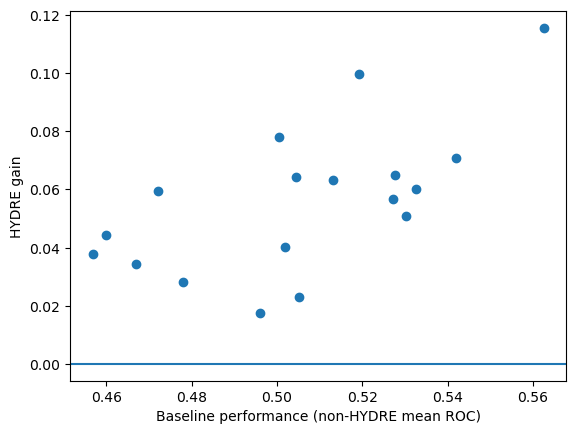

29.0 0.248046875


In [6]:
# Investigate if the HYDRE model improve decoding not only for the best performing subjects but also for the worst performing subjects
df = df_roc_300ms.copy()
print(df)
df_wide = df.pivot(
    index="Subject",
    columns="Method",
    values="ROC_AUC"
).reset_index()
df_wide["HYDRE_gain"] = df_wide["HYDRE3"] - df_wide.drop(columns=["Subject", "HYDRE3"]).mean(axis=1)
df_wide["baseline_perf"] = df_wide.drop(columns=["Subject", "HYDRE3"]).mean(axis=1)

print(df_wide)

from scipy.stats import spearmanr

rho, p = spearmanr(df_wide["baseline_perf"], df_wide["HYDRE_gain"])

print(rho, p)

plt.scatter(df_wide["baseline_perf"], df_wide["HYDRE_gain"])
plt.xlabel("Baseline performance (non-HYDRE mean ROC)")
plt.ylabel("HYDRE gain")
plt.axhline(0)
plt.show()



df_subject_mean = (
    df_roc_300ms[df_roc_300ms["Method"] != "HYDRE3"]
    .groupby("Subject", as_index=False)["ROC_AUC"]
    .mean()
    .rename(columns={"ROC_AUC": "mean_ROC"})
)

lowest_9_subjects = (
    df_subject_mean
    .sort_values("mean_ROC", ascending=True)
    .head(9)
)

# 1. filter worst subjects
df_worst = df_roc_300ms[
    df_roc_300ms["Subject"].isin(lowest_9_subjects["Subject"])
].copy()

# 2. pivot ONLY this subset
df_wide = df_worst.pivot(
    index="Subject",
    columns="Method",
    values="ROC_AUC"
)

df_wide["best_other"] = df_wide.drop(columns=["HYDRE3"]).max(axis=1)
df_wide["gain_best"] = df_wide["HYDRE3"] - df_wide["best_other"]

from scipy.stats import wilcoxon

stat, p = wilcoxon(df_wide["gain_best"], alternative="greater")

print(stat, p)


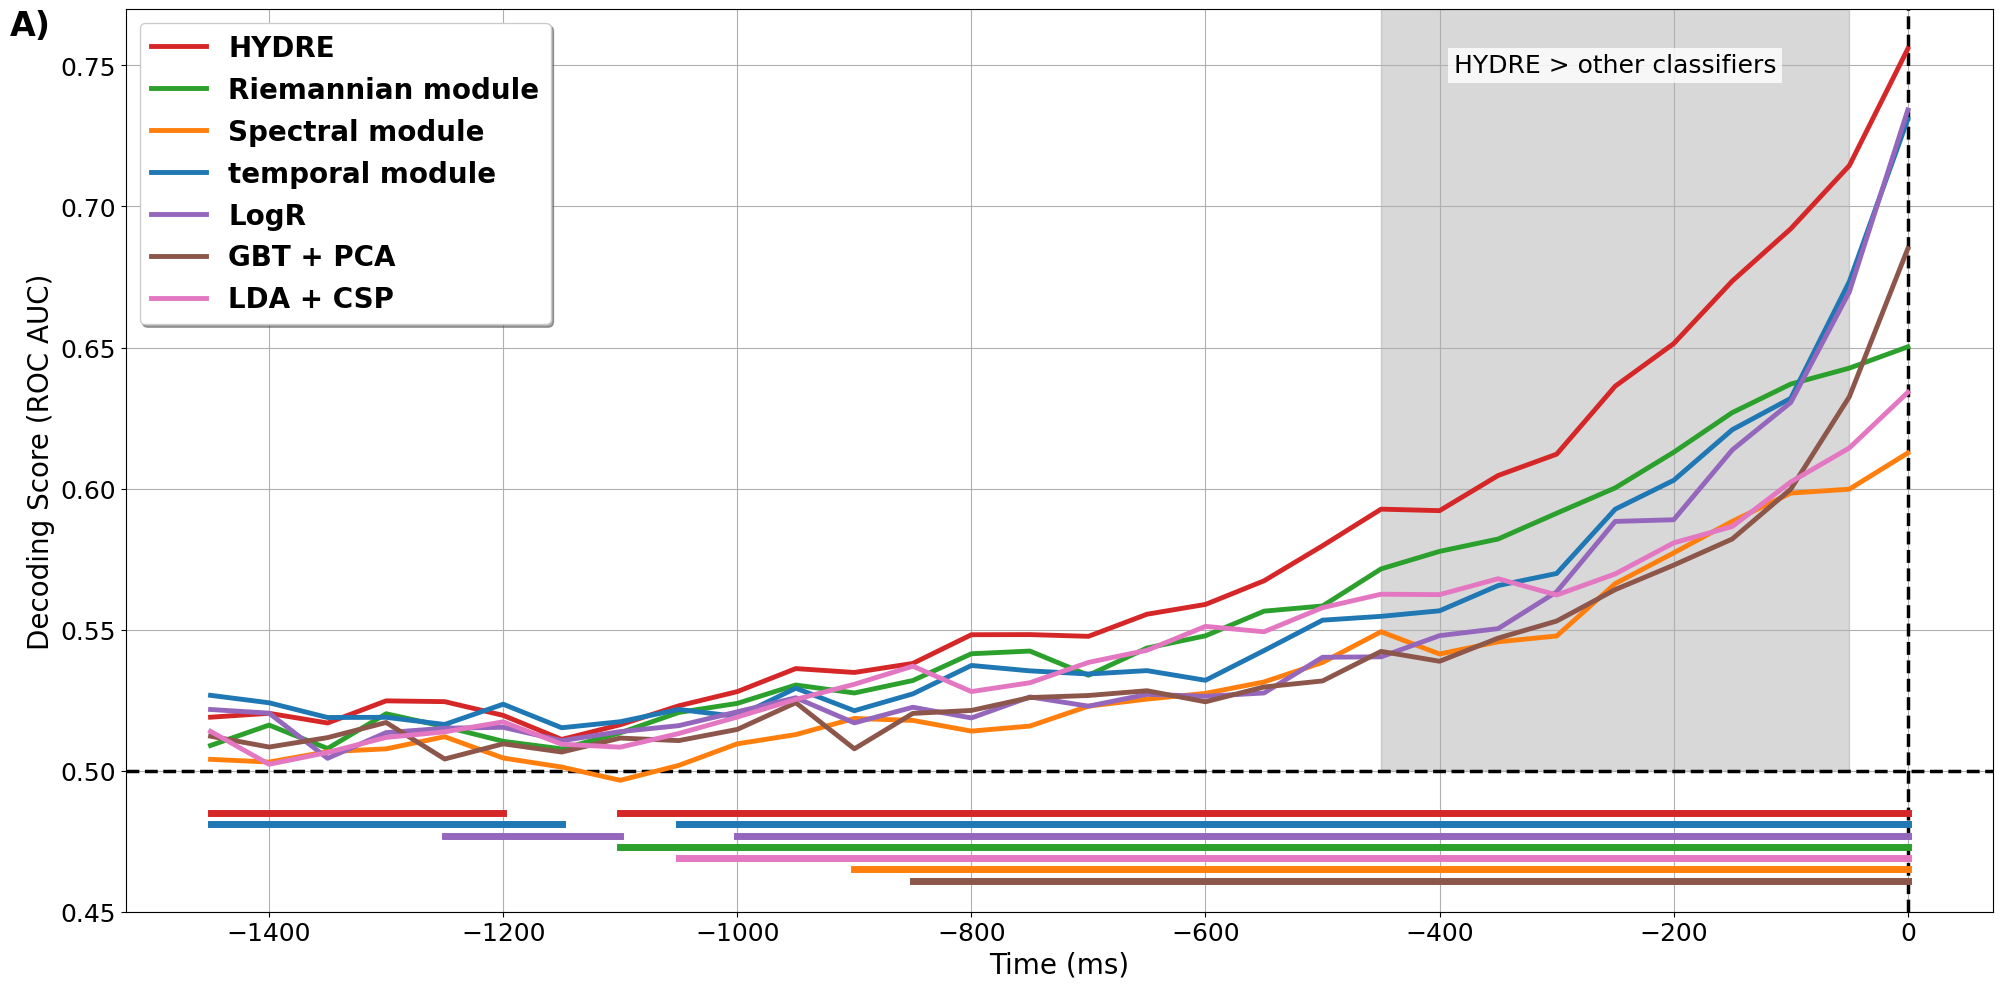

In [7]:
# Plot the figure with the time course of decoding scores for HYDRE and different classical methods

fig, axes = plt.subplots(1, 1, figsize=(20, 10))

colors_master = ['#d62728','#2ca02c','#ff7f0e','#1f77b4', '#9467bd', '#8c564b', '#e377c2']

labels_master = [
    "HYDRE",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR",
    "GBT + PCA",
    "LDA + CSP"
]

color_map = dict(zip(labels_master, colors_master))

# --- Plot settings ---
chance_level = 0.5
ymin = 0.45
ymax = 0.77

axes.set_ylim(ymin, ymax)

# Reference lines
axes.axvline(0., color='k', linestyle='--', linewidth=2.5)
axes.axhline(chance_level, color='k', linestyle='--', linewidth=2.5)

# ---------------------------------------------------------
# Compute ordering based on earliest significant time point
# ---------------------------------------------------------
first_sig_time = []

for i in range(len(mask_methods)):

    if np.any(mask_methods[i]):
        first_idx = np.where(mask_methods[i])[0][0]
        first_sig_time.append(times[first_idx])
    else:
        first_sig_time.append(np.inf)

# Sort: earliest significance = highest bar
order_bar = np.argsort(first_sig_time)

# Vertical positions (top -> bottom)
pos_bar1 = [0.485, 0.481, 0.477, 0.473, 0.469, 0.465, 0.461]

# Map method index -> vertical position
bar_position_map = np.empty(len(order_bar))
for rank, method_idx in enumerate(order_bar):
    bar_position_map[method_idx] = pos_bar1[rank]

# ---------------------------------------------------------
# Plot curves + significance bars
# ---------------------------------------------------------
for i in range(len(all_roc_all_methods)):

    sign_pos = np.full(mask_methods[i].shape, bar_position_map[i])
    sign_pos[~mask_methods[i]] = np.nan

    # Decoding curve
    axes.plot(
        times,
        all_roc_all_methods[i],
        label=labels_master[i],
        color=colors_master[i],
        linewidth=3.5
    )

    # Significance bar
    axes.plot(
        times,
        sign_pos,
        color=colors_master[i],
        linewidth=5
    )

    first_idx = np.where(mask_methods[i])[0][0]

# ---------------------------------------------------------
# Grey shaded region (HYDRE advantage)
# ---------------------------------------------------------
axes.fill_between(
    times,
    chance_level,
    ymax,
    where=mask_HYDRE_all_diff,
    color='grey',
    alpha=0.3,
    zorder=1
)

# Label inside shaded region
axes.text(
    np.mean(times[mask_HYDRE_all_diff]),
    0.75,
    'HYDRE > other classifiers',
    fontsize=18,
    color='black',
    ha='center',
    va='center',
    bbox=dict(
        facecolor='white',
        alpha=0.8,
        edgecolor='none',
        pad=4
    ),
    zorder=10
)

# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------
axes.set_ylabel('Decoding Score (ROC AUC)', fontsize=20)
axes.set_xlabel('Time (ms)', fontsize=20)

axes.tick_params(axis='y', labelsize=18)
axes.tick_params(axis='x', labelsize=18)

axes.legend(
    loc='best',
    frameon=True,
    fancybox=True,
    shadow=True,
    prop={'weight': 'bold', 'size': 20}
)

axes.grid(True)

axes.text(
    -0.04,
    1.00,
    'A)',
    transform=axes.transAxes,
    fontsize=24,
    fontweight='bold',
    va='top',
    ha='right'
)

plt.tight_layout()

if saving:
    plt.savefig(
        os.path.join(path_figure, fname_fig),
        format='svg',
        dpi=300
    )

if viz_plot:
    plt.show()

In [8]:
# Test with the accuracy scores instead of ROC AUC
methods=[ "HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]
    
mask_methods_accu = list()
all_accu_all_methods = list()
df_stat_raising= list()

HYDRE_accu_dict = dict()

rho_value_all=[]

for method in methods:
    all_accu = list()

    for n_subject, subject in enumerate(subjects_id):

        if method == "HYDRE3" or method == "Riemannian module" or method == "Spectral module" or method == "temporal module":
        
            path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
            df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))

            accu_scores = []

            for time_point in df_detailed_HYDRE['time'].unique():
                # Select data for the current time window
                data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
                # Compute accuracy for HYDRE and each module
                if method == "HYDRE3":
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_ensemble'].values))
                if method == "Riemannian module":
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_riemann'].values))
                if method == "Spectral module":
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_tfr'].values))
                if method == "temporal module":
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_temporal'].values))     

        else:

            if method == "LogR_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LogR_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LogR_win50.csv' % subject))

                accu_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred'].values))
            
            if method == "GBT_default_PCA_0.99_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'GBT_default_PCA_0.99_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_GBT_default_PCA_0.99_win50.csv' % subject))

                accu_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred'].values))
            
            if method == "LDA_CSP_20_win200_sl50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LDA_CSP_20_win200_sl50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LDA_CSP_20_win200_sl50.csv' % subject))

                accu_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    accu_scores.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred'].values))



        all_accu.append(accu_scores)
        
        if method in ["HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]:
            HYDRE_accu_dict[method] = np.array(all_accu)


    # Test if the decoding scores are significantly better than chance (0.5) at each time point
    p_val = decod_stats(np.array(all_accu)-1/2.)
    wh_sign = p_val<0.05
    mask_methods_accu.append(wh_sign)
    all_accu_all_methods.append(np.squeeze(np.mean(all_accu, axis=0)))  


    # Test if the score are significantly raising across time
    n_participants = np.array(all_accu).shape[0]
    n_times = np.array(all_accu).shape[1]
    time_vector = np.arange(n_times)
    rho_values = []

    for i in range(n_participants):
        # We only care about the correlation coefficient (rho)
        rho, _ = stats.spearmanr(time_vector,np.array(all_accu)[i, :])
        rho_values.append(rho)

    rho_values = np.array(rho_values)

    rho_value_all.append(rho_values)

    # 2. Test if the distribution of rhos is significantly > 0
    # We use Wilcoxon signed-rank test
    stat, p_value = stats.wilcoxon(rho_values, alternative='greater')
    res_dict = {
        "Method": method,
        "Stat": stat,
        "p_value": p_value,
        "Mean_Rho": np.mean(rho_values),
        "std_Rho": np.std(rho_values),
        "range_Rho": (np.min(rho_values), np.max(rho_values))
    }
    df_stat_raising.append(res_dict)

# Compute significance masks
method_ref = "HYDRE3"
method_other = ["Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]

# Test against HYDRE
mask_compare_HYDRE = []
for method2 in method_other:
    X1 = np.vstack(HYDRE_accu_dict[method_ref])  # shape: (n_subjects, n_times)
    X2 = np.vstack(HYDRE_accu_dict[method2])
    X_diff = X1 - X2
    p_val = decod_stats(X_diff)  # your cluster-based permutation function
    mask_compare_HYDRE.append(p_val < 0.05)
    if np.any(p_val < 0.05):
        print(f"Time window of significant difference between HYDRE & {method2}: {times[np.where(p_val < 0.05)[0][0]]} ms to {times[np.where(p_val < 0.05)[0][-1]]} ms")
    else:
        print(f"No significant difference between HYDRE & {method2} across time.")
        print(p_val)
        
# Create time axis
n_times = HYDRE_accu_dict[method_ref][0].shape[0]
times = np.linspace(-1450, 0, n_times)

mask_HYDRE_all_diff = np.logical_and.reduce(mask_compare_HYDRE)
indices = np.where(mask_HYDRE_all_diff == True)
if len(indices[0]) > 0:
    print(f"Time window of significant difference between HYDRE & all the classifiers: {times[indices[0][0]]} ms to {times[indices[0][-1]]} ms")

df_stat_raising = pd.DataFrame(df_stat_raising)   

from statsmodels.stats.multitest import multipletests 
reject, pvals_corrected, _, _ = multipletests(df_stat_raising["p_value"], alpha=0.05, method='fdr_bh')

for n_method, method in enumerate(methods):
    print(method,":")
    tmp=df_stat_raising["Mean_Rho"].values[n_method]
    print(f"Mean Spearman Rho: {tmp:.4f}")
    tmp2=df_stat_raising["Stat"].values[n_method]
    print(f"t-statistic: {tmp2:.4f}")
    print(f"Group-level p-value: {pvals_corrected[n_method]}")

# Print the time at which the worst performing model first became significantly better than chance
print("\n")
print("#########################################################################")

for i, method in enumerate(methods):

    first_significant_time = times[np.where(mask_methods_accu[i])[0][0]]
    print(f"{method} first becomes significantly better than chance at: {first_significant_time:.1f} ms")
    average_score_300ms = all_accu_all_methods[i][-6]
    print(f"Average Accuracy at -300ms for {method}: {average_score_300ms:.3f}")
    average_score_0ms = all_accu_all_methods[i][-1]
    print(f"Average Accuracy at the button press for {method}: {average_score_0ms:.3f}")
    average_score_last_300ms = all_accu_all_methods[i][-6:]
    print(f"Average Accuracy -300ms to 0ms for {method}: {np.mean(average_score_last_300ms):.3f}")
    average_score_last_500ms = all_accu_all_methods[i][-10:]
    print(f"Average Accuracy -500ms to 0ms for {method}: {np.mean(average_score_last_500ms):.3f}")
    print("#########################################################################")
    print("\n")

Time window of significant difference between HYDRE & Riemannian module: -500.0 ms to 0.0 ms
Time window of significant difference between HYDRE & Spectral module: -1450.0 ms to 0.0 ms
No significant difference between HYDRE & temporal module across time.
[1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         1.         0.33032227 1.         0.47875977 1.
 1.         1.         0.21655273 1.         1.         0.39013672
 1.         0.05639648 0.05639648 0.05639648 1.         1.        ]
Time window of significant difference between HYDRE & LogR_win50: -1350.0 ms to -100.0 ms
Time window of significant difference between HYDRE & GBT_default_PCA_0.99_win50: -800.0 ms to 0.0 ms
Time window of significant difference between HYDRE & LDA_CSP_20_win200_sl50: -1400.0 ms to 0.0 ms
HYDRE3 :
Mean Spearman Rho: 0.8192
t-statistic: 171.0000
Group-level p-value: 4.450480143229167e-06
Riemannian module :
Mean Spearman Rho: 0.

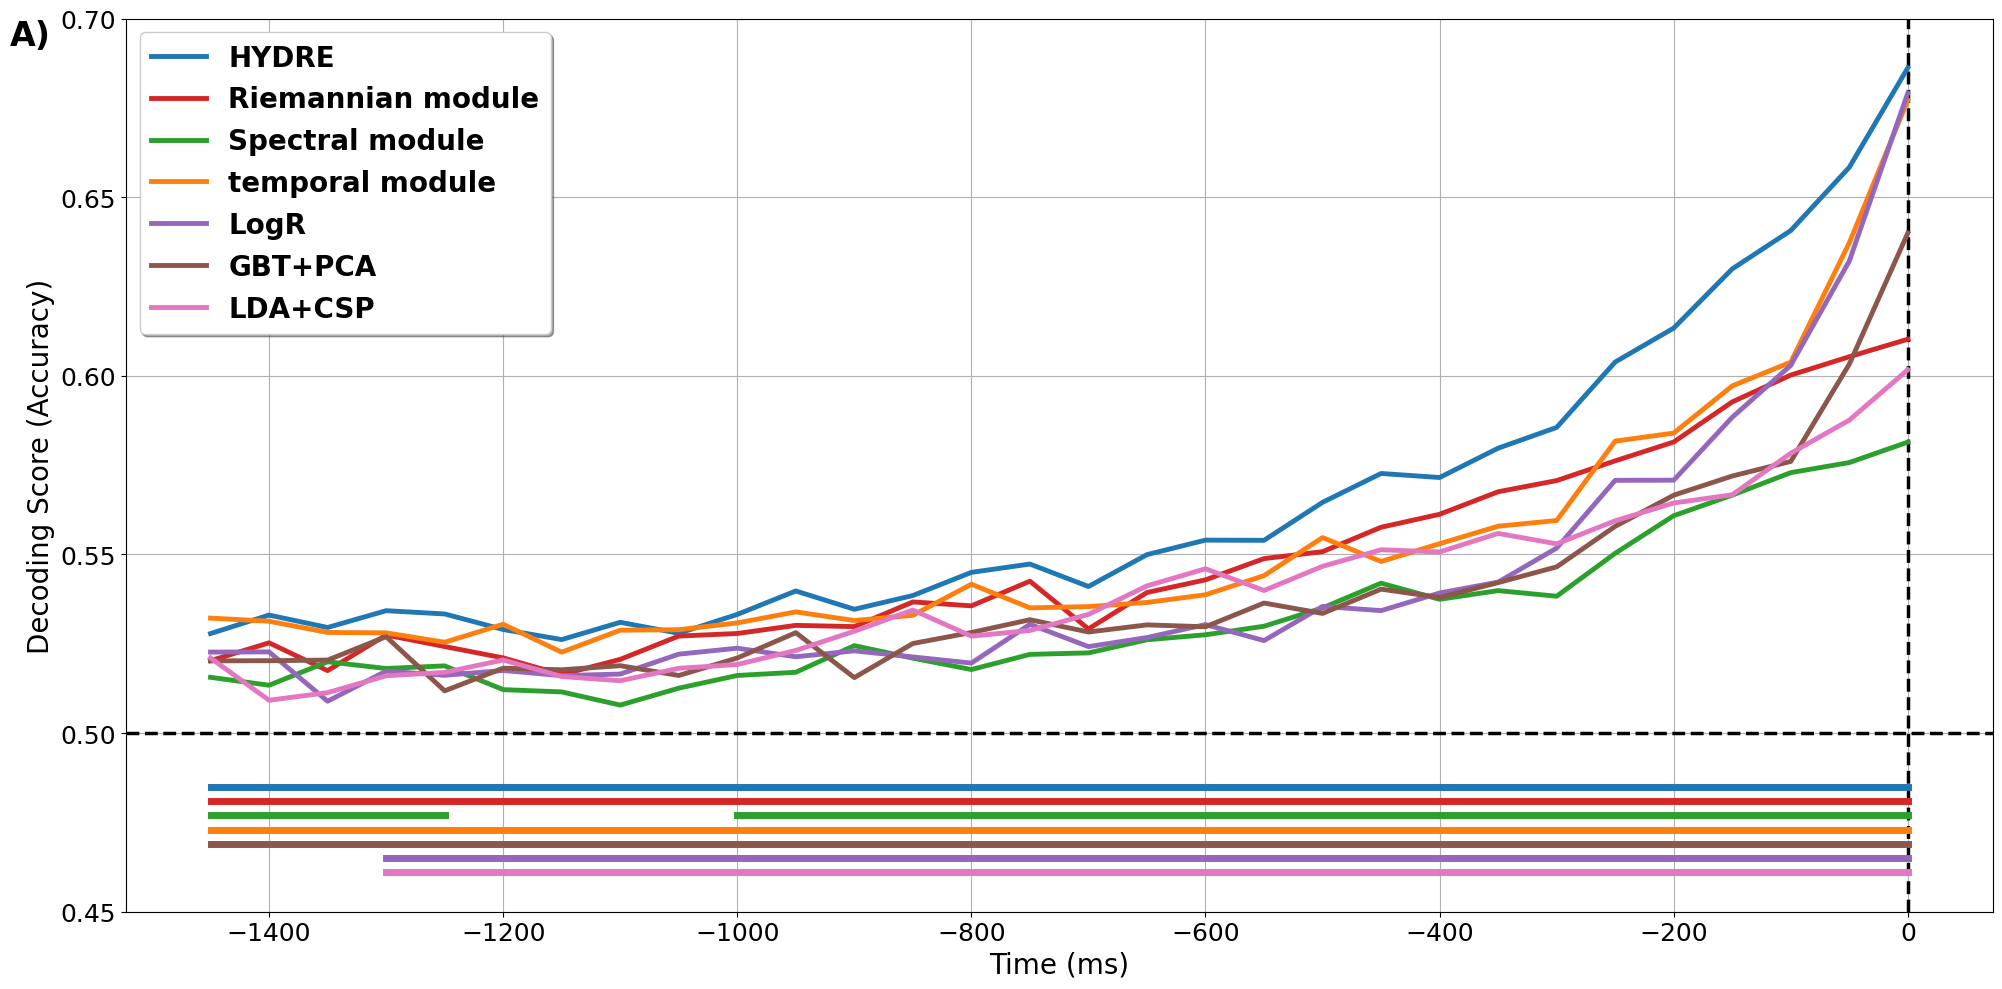

In [9]:
# Plot the figure with the time course of accuracy scores for HYDRE and different classical methods

fig, axes = plt.subplots(1, 1, figsize=(20, 10))

colors_master = [
    '#1f77b4', '#d62728', '#2ca02c',
    '#ff7f0e', '#9467bd', '#8c564b', '#e377c2'
]

labels_master = [
    "HYDRE",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR",
    "GBT+PCA",
    "LDA+CSP"
]

color_map = dict(zip(labels_master, colors_master))

# --- Plot settings ---
chance_level = 0.5
ymin = 0.45
ymax = 0.7

axes.set_ylim(ymin, ymax)

# Reference lines
axes.axvline(0., color='k', linestyle='--', linewidth=2.5)
axes.axhline(chance_level, color='k', linestyle='--', linewidth=2.5)

# ---------------------------------------------------------
# Compute ordering based on earliest significant time point
# ---------------------------------------------------------
first_sig_time = []

for i in range(len(mask_methods_accu)):

    if np.any(mask_methods_accu[i]):
        first_idx = np.where(mask_methods_accu[i])[0][0]
        first_sig_time.append(times[first_idx])
    else:
        first_sig_time.append(np.inf)

# Sort: earliest significance = highest bar
order_bar = np.argsort(first_sig_time)

# Vertical positions (top -> bottom)
pos_bar1 = [0.485, 0.481, 0.477, 0.473, 0.469, 0.465, 0.461]

# Map method index -> vertical position
bar_position_map = np.empty(len(order_bar))
for rank, method_idx in enumerate(order_bar):
    bar_position_map[method_idx] = pos_bar1[rank]

# ---------------------------------------------------------
# Plot curves + significance bars
# ---------------------------------------------------------
for i in range(len(all_accu_all_methods)):

    sign_pos = np.full(mask_methods_accu[i].shape, bar_position_map[i])
    sign_pos[~mask_methods_accu[i]] = np.nan

    # Decoding curve
    axes.plot(
        times,
        all_accu_all_methods[i],
        label=labels_master[i],
        color=colors_master[i],
        linewidth=3.5
    )

    # Significance bar
    axes.plot(
        times,
        sign_pos,
        color=colors_master[i],
        linewidth=5
    )

    first_idx = np.where(mask_methods_accu[i])[0][0]

# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------
axes.set_ylabel('Decoding Score (Accuracy)', fontsize=20)
axes.set_xlabel('Time (ms)', fontsize=20)

axes.tick_params(axis='y', labelsize=18)
axes.tick_params(axis='x', labelsize=18)

axes.legend(
    loc='best',
    frameon=True,
    fancybox=True,
    shadow=True,
    prop={'weight': 'bold', 'size': 20}
)

axes.grid(True)

axes.text(
    -0.04,
    1.00,
    'A)',
    transform=axes.transAxes,
    fontsize=24,
    fontweight='bold',
    va='top',
    ha='right'
)

plt.tight_layout()

if saving:
    plt.savefig(
        os.path.join(path_figure, fname_fig),
        format='svg',
        dpi=300
    )

if viz_plot:
    plt.show()

HYDRE
Optimal threshold
[0.4820466  0.46475194 0.4941696  0.39959075 0.49701172 0.42455046
 0.47559402 0.41393767 0.46042151 0.48561451 0.44762486 0.42812765
 0.38246451 0.44264251 0.43771277 0.41065984 0.45464176 0.47180067]
Mean optimal threshold : 0.44852018609663397 , SEM: 0.007917510853385728
Riemannian module
Optimal threshold
[0.32883174 0.45790312 0.31175765 0.40732504 0.4709377  0.46118981
 0.40661137 0.3131092  0.44211981 0.39495033 0.33635538 0.50181809
 0.23789067 0.4108097  0.3987532  0.30200478 0.59586679 0.51615665]
Mean optimal threshold : 0.40524394560721017 , SEM: 0.02109791633831099
Spectral module
Optimal threshold
[0.32128893 0.40748662 0.42331598 0.39123204 0.36872513 0.37575474
 0.59076218 0.5084394  0.38446373 0.46571799 0.30174716 0.44362621
 0.28704761 0.27930298 0.46019737 0.45512668 0.5819216  0.3393199 ]
Mean optimal threshold : 0.4103042371141786 , SEM: 0.02150842609633275
temporal module
Optimal threshold
[0.48591593 0.42265433 0.42088908 0.47654819 0.388

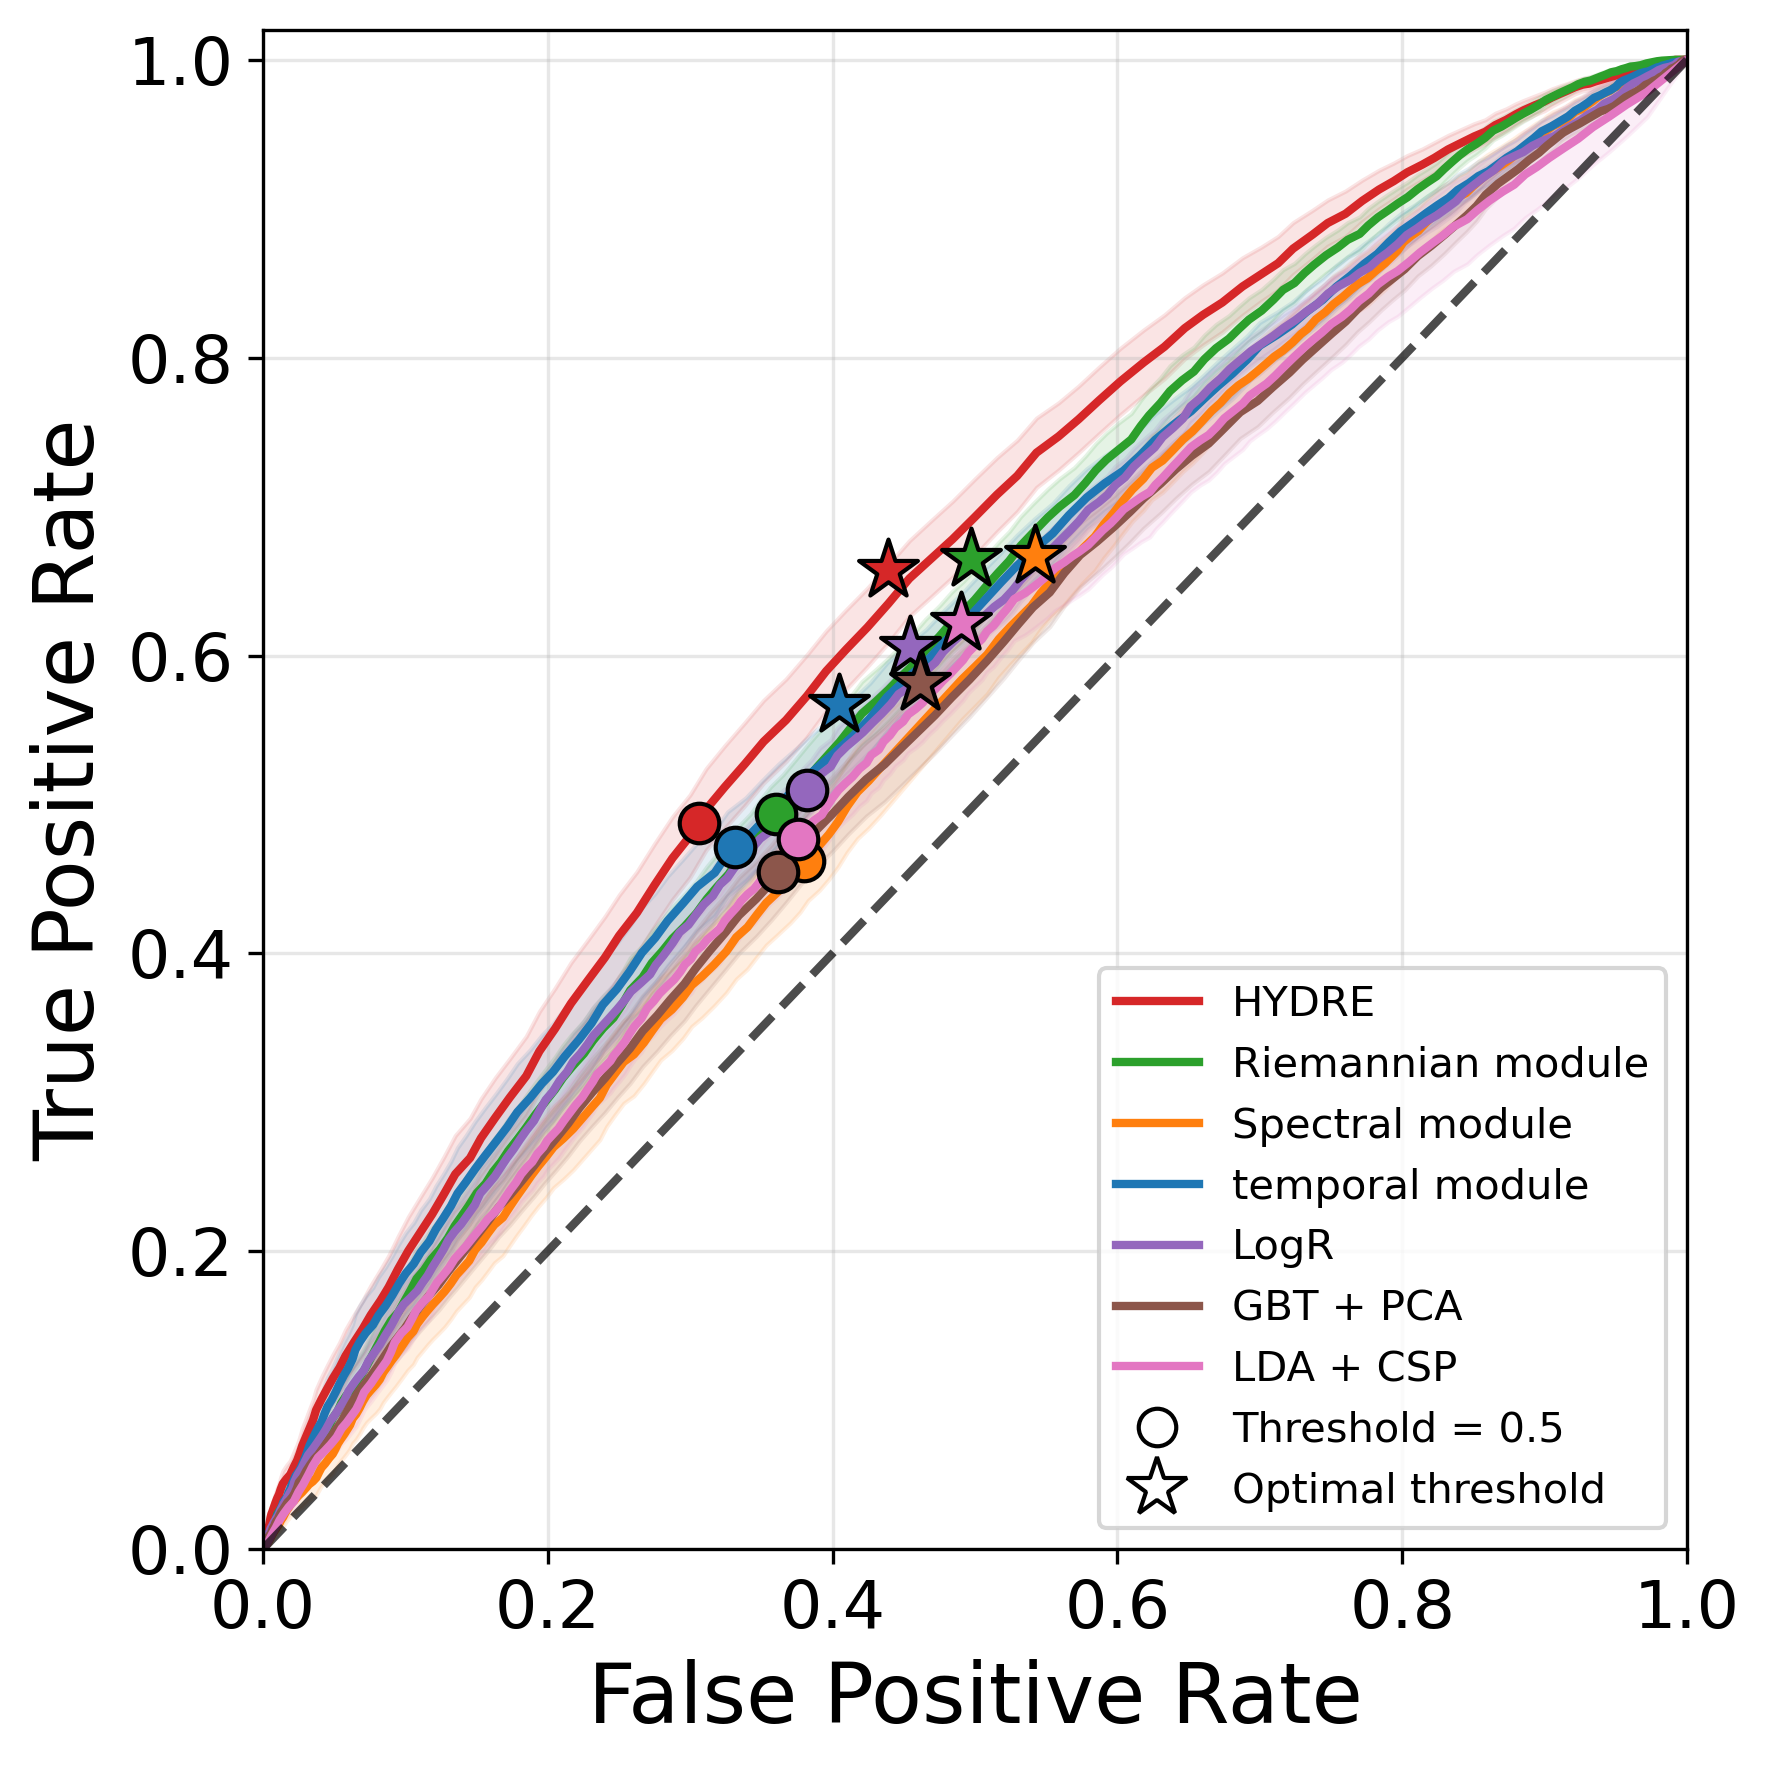

mean younden's J and Std
0.42002544727951213
0.02452900184883515


In [7]:
# Plotting the ROC curve at -300ms for all methods (Threshold-Averaged)

from matplotlib.lines import Line2D
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Plotting the ROC curve at -300ms for all methods (Threshold-Averaged)
time_point = -300

methods = [
    "HYDRE",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR",
    "GBT + PCA",
    "LDA + CSP"
]

mean_thresholds = np.linspace(0, 1, 200)

plt.figure(figsize=(6, 6), dpi=300)

list_youden_mean=[]
list_youden_sem=[]

for method in methods:

    # =====================================================
    # Select dataframe and probability column
    # =====================================================

    if method == "HYDRE":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_ensemble"

    elif method == "Riemannian module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_riemann"

    elif method == "Spectral module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_tfr"

    elif method == "temporal module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_temporal"

    elif method == "LogR":
        df_base = df_detailed_LogR_all_subjects
        proba_col = "proba"

    elif method == "GBT + PCA":
        df_base = df_detailed_GBT_PCA_all_subjects
        proba_col = "proba"

    elif method == "LDA + CSP":
        df_base = df_detailed_LDA_CSP_all_subjects
        proba_col = "proba"

    df = df_base[df_base["time"] == time_point]

    # =====================================================
    # Subject-wise computations
    # =====================================================

    fprs, tprs, aucs = [], [], []
    fpr_05_list, tpr_05_list = [], []
    fpr_j_list, tpr_j_list = [], []
    youden_thresholds = []

    for participant_id, df_sub in df.groupby("participant_id"):

        y_true = df_sub["y_true"]
        y_score = df_sub[proba_col]

        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        aucs.append(auc(fpr, tpr))

        # sort for interpolation
        sorted_idx = np.argsort(thresholds)
        sorted_thresholds = thresholds[sorted_idx]
        sorted_fpr = fpr[sorted_idx]
        sorted_tpr = tpr[sorted_idx]

        interp_fpr = np.interp(mean_thresholds, sorted_thresholds, sorted_fpr)
        interp_tpr = np.interp(mean_thresholds, sorted_thresholds, sorted_tpr)

        fprs.append(interp_fpr)
        tprs.append(interp_tpr)

        # threshold 0.5
        idx_05 = np.argmin(np.abs(thresholds - 0.5))
        fpr_05_list.append(fpr[idx_05])
        tpr_05_list.append(tpr[idx_05])

        # Youden J
        j_scores = tpr - fpr
        idx_j = np.argmax(j_scores)
        fpr_j_list.append(fpr[idx_j])
        tpr_j_list.append(tpr[idx_j])

        youden_thresholds.append(thresholds[idx_j])

    # =====================================================
    # Group-level summaries
    # =====================================================

    mean_fpr = np.mean(fprs, axis=0)
    mean_tpr = np.mean(tprs, axis=0)
    sem_tpr = np.std(tprs, axis=0, ddof=1) / np.sqrt(len(tprs))

    mean_auc = np.mean(aucs)

    mean_fpr_05 = np.mean(fpr_05_list)
    mean_tpr_05 = np.mean(tpr_05_list)

    mean_fpr_j = np.mean(fpr_j_list)
    mean_tpr_j = np.mean(tpr_j_list)

    mean_youden_threshold = np.mean(youden_thresholds)
    sem_youden_threshold = np.std(youden_thresholds, axis=0, ddof=1) / np.sqrt(len(youden_thresholds))

    list_youden_mean.append(mean_youden_threshold)
    list_youden_sem.append(sem_youden_threshold)

    print(method)
    print("Optimal threshold")
    print(np.array(youden_thresholds))
    print(f"Mean optimal threshold : {mean_youden_threshold} , SEM: {sem_youden_threshold}")

    # =====================================================
    # ROC curve
    # =====================================================

    line, = plt.plot(
        mean_fpr,
        mean_tpr,
        linewidth=2,
        label=method,
        color=color_map[method]
    )

    color = line.get_color()

    # SEM shading
    plt.fill_between(
        mean_fpr,
        np.clip(mean_tpr - sem_tpr, 0, 1),
        np.clip(mean_tpr + sem_tpr, 0, 1),
        color=color,
        alpha=0.12
    )

    # threshold 0.5 point
    plt.scatter(
        mean_fpr_05,
        mean_tpr_05,
        s=90,
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=6
    )

    # Youden point
    plt.scatter(
        mean_fpr_j,
        mean_tpr_j,
        s=220,
        marker="*",
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=7
    )

# =========================================================
# Chance line
# =========================================================

plt.plot([0, 1], [0, 1], "k--", linewidth=2, alpha=0.7)

# =========================================================
# Formatting
# =========================================================

plt.xlabel("False Positive Rate", fontsize=20)
plt.ylabel("True Positive Rate", fontsize=20)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)

# =========================================================
# Single clean legend
# =========================================================

handles, labels = plt.gca().get_legend_handles_labels()

handles.extend([
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor='white',
        markeredgecolor='black',
        markersize=9,
        label='Threshold = 0.5'
    ),
    Line2D(
        [0], [0],
        marker='*',
        linestyle='None',
        markerfacecolor='white',
        markeredgecolor='black',
        markersize=15,
        markeredgewidth=1,
        label='Max. Youden index'
    )
])

labels.extend([
    'Threshold = 0.5',
    'Optimal threshold'
])

plt.legend(
    handles,
    labels,
    fontsize=10,
    loc='lower right',
    frameon=True
)

plt.tight_layout()
plt.show()

print("mean younden's J and Std")
print(np.mean(list_youden_mean[1:]))
print(np.mean(list_youden_sem[1:]))

In [ ]:
# Test if the variance is significantly different between classifiers at the group level
def variance_difference(x, y):
    return np.var(x, ddof=1) - np.var(y, ddof=1)

# Comparing the time course of decoding scores for HYDRE and different classical methods
methods=[ "HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]
    
fname_fig_accu = 'decoding_time_course_HYDRE3_&_other_methods.svg' 

mask_methods = list()
all_roc_all_methods = list()

for method in methods:
    all_roc = list()

    for n_subject, subject in enumerate(subjects_id):

        if method == "HYDRE3" or method == "Riemannian module" or method == "Spectral module" or method == "temporal module":
        
            path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
            df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))

            roc_scores = []

            for time_point in df_detailed_HYDRE['time'].unique():
                # Select data for the current time window
                data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
                # Compute ROC AUC for HYDRE and each module
                if method == "HYDRE3":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
                if method == "Riemannian module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))
                if method == "Spectral module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_tfr'].values))
                if method == "temporal module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))      

        else:

            if method == "LogR_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LogR_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LogR_win50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))
            
            if method == "GBT_default_PCA_0.99_win50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'GBT_default_PCA_0.99_win50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_GBT_default_PCA_0.99_win50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))
            
            if method == "LDA_CSP_20_win200_sl50":
                path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'LDA_CSP_20_win200_sl50'))
                df_detailed = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_LDA_CSP_20_win200_sl50.csv' % subject))

                roc_scores = []

                for time_point in df_detailed['time'].unique():
                    # Select data for the current time window
                    data_per_time_win = df_detailed[df_detailed['time'] == time_point]
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba'].values))

        all_roc.append(roc_scores[-6])
    all_roc_all_methods.append(np.array(all_roc)) 
roc_array=np.array(all_roc_all_methods)

# and columns are ROC values for each model.
data = {
    'HYDRE': roc_array[0], 
    "Riemannian module":   roc_array[1], 
    "Spectral module":   roc_array[2],
    "temporal module":   roc_array[3],
    'LogR':   roc_array[4],
    'GBT+PCA':   roc_array[5],
    'CSP+LDA':   roc_array[6]
}
df = pd.DataFrame(data)

ref_col = 'HYDRE'
other_models = [c for c in df.columns if c != ref_col]

results = []

# --- CALCULATE ---
for model in other_models:
    res = permutation_test(
                (df[ref_col], df[model]), 
                variance_difference, 
                permutation_type='pairings', 
                n_resamples=10000,
                alternative='two-sided'
            )

    # Calculate actual variances for reporting
    var_ref = np.var(df[ref_col], ddof=1)
    var_other = np.var(df[model], ddof=1)
    
    results.append({
        'Comparison': f'{ref_col} vs {model}',
        'Var_Ref': var_ref,
        'Var_Other': var_other,
        't_stat': res.statistic,
        'p_raw': res.pvalue
    })

results_df = pd.DataFrame(results)

results_df

,Comparison,Var_Ref,Var_Other,t_stat,p_raw
0,HYDRE vs Riemannian module,0.002572,0.003523,-0.000951,1.0
1,HYDRE vs Spectral module,0.002572,0.001976,0.000596,1.0
2,HYDRE vs temporal module,0.002572,0.004634,-0.002062,1.0
3,HYDRE vs LogR,0.002572,0.002928,-0.000356,1.0
4,HYDRE vs GBT+PCA,0.002572,0.002302,0.000270,1.0
5,HYDRE vs CSP+LDA,0.002572,0.002922,-0.000350,1.0


HYDRE median ROC AUC at -300ms: 0.645333589402719
Riemannian median ROC AUC at -300ms: 0.5963545396555918
Spectral median ROC AUC at -300ms: 0.55426443477193
Temporal median ROC AUC at -300ms: 0.5850246134230633


C:\Users\Romar\AppData\Local\Temp\ipykernel_10212\114829369.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(data_to_plot, labels=labels, patch_artist=True,


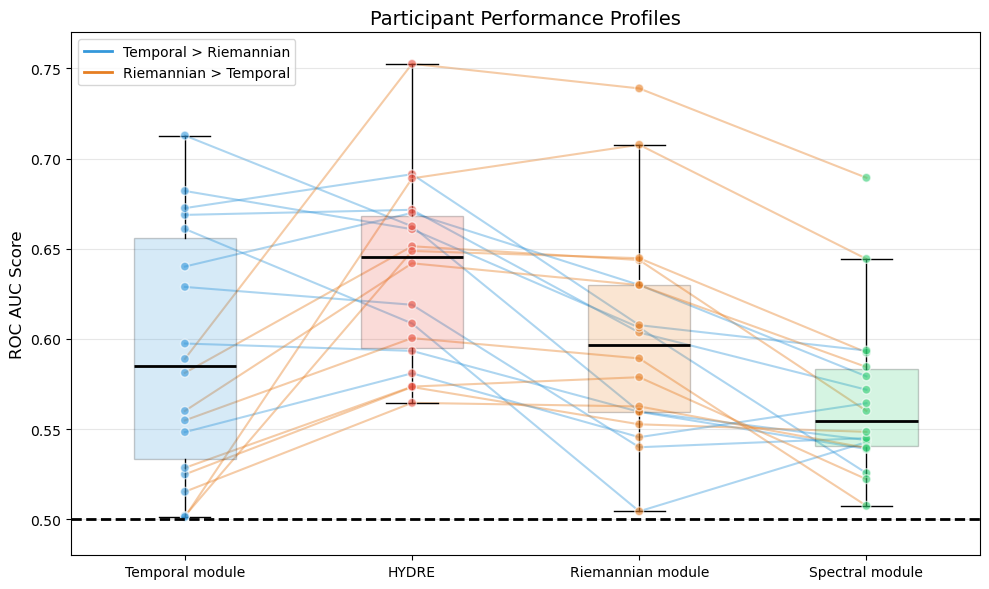

In [ ]:
# Boxplot comparing the scores of the 3 modules for each subject on time window from -300ms to -250ms
methods = ["temporal_module", "tfr_module", "riemann_module"]
fname_fig = 'boxplot_roc_score_300ms.svg' 

# Assign data to three dimensions
x = np.array(roc_scores_all_subjects_temporal_module) # temporal
y = np.array(roc_scores_all_subjects_spectral_module) # tfr
z = np.array(roc_scores_all_subjects_riemannian_module) # riemann
w= np.array(roc_scores_all_subjects_HYDRE) # HYDRE
x=x[:,-6]
y=y[:,-6]
z=z[:,-6]
w=w[:,-6]

print("HYDRE median ROC AUC at -300ms:", np.median(w))
print("Riemannian median ROC AUC at -300ms:", np.median(z))
print("Spectral median ROC AUC at -300ms:", np.median(y))
print("Temporal median ROC AUC at -300ms:", np.median(x))

data_to_plot = [x, w, z, y]
labels = ['Temporal module', 'HYDRE', 'Riemannian module', 'Spectral module']
colors = ['#3498db', '#e74c3c',  '#e67e22', '#2ecc71']
n_participants = len(w)

In [21]:
# Comparaison of the scores of the 3 modules for each subject at -300ms
methods = ["temporal_module", "tfr_module", "riemann_module"]
fname_fig = 'scatter_plot_3d_roc_score_300ms.svg' 
all_roc_all_methods = roc_scores_all_subjects_temporal_module, roc_scores_all_subjects_spectral_module, roc_scores_all_subjects_riemannian_module, roc_scores_all_subjects_HYDRE

# Assign data to three dimensions
x = np.array(all_roc_all_methods[0]) # temporal
y = np.array(all_roc_all_methods[1]) # tfr
z = np.array(all_roc_all_methods[2]) # riemann
w= np.array(all_roc_all_methods[3]) # HYDRE
x=x[:,-6]
y=y[:,-6]
z=z[:,-6]
w=w[:,-6]

# Create a colormap
cmap = plt.get_cmap('tab20')
colors = cmap(np.linspace(0, 1, len(subjects_id)))

base_modules = np.array([x, y, z]) 
best_base_score = np.max(base_modules, axis=0)

# 3. Update combinations list
combinations = [
    (x, y, "Temporal", "Spectral"),    
    (z, y, "Riemannian", "Spectral"),
    (x, z, "Temporal", "Riemannian"),
    (best_base_score, w, "Best module", "HYDRE") # New comparison 
]

# test correlation between modules and HYDRE

# stats_temporal_spectral = pg.corr(x, y, method='skipped')
# stats_spectral_riemann = pg.corr(y, z, method='skipped')
# stats_riemann_temporal = pg.corr(z, x, method='skipped')
# stats_HYDRE_best_module = pg.corr(best_base_score, w, method='skipped')

# corr_combinaison = [stats_temporal_spectral['r'].iloc[0], stats_spectral_riemann['r'].iloc[0], stats_riemann_temporal['r'].iloc[0], stats_HYDRE_best_module['r'].iloc[0]]
# p_combinaison = [stats_temporal_spectral['p-val'].iloc[0], stats_spectral_riemann['p-val'].iloc[0], stats_riemann_temporal['p-val'].iloc[0], stats_HYDRE_best_module['p-val'].iloc[0]]

corr_temporal_spectral, p_temporal_spectral = stats.spearmanr(x, y)
corr_spectral_riemann, p_spectral_riemann = stats.spearmanr(y, z)
corr_riemann_temporal, p_riemann_temporal = stats.spearmanr(z, x)
corr_HYDRE_best_module, p_HYDRE_best_module = stats.spearmanr(best_base_score, w)

corr_combinaison = [corr_temporal_spectral, corr_spectral_riemann, corr_riemann_temporal, corr_HYDRE_best_module]
p_combinaison = [p_temporal_spectral, p_spectral_riemann, p_riemann_temporal, p_HYDRE_best_module]

# Correction for multiple testing
from statsmodels.stats.multitest import multipletests 
reject, pvals_corrected, _, _ = multipletests(p_combinaison, alpha=0.05, method='holm')

# print("Correlation Temporal vs Spectral:", "r=", stats_temporal_spectral['r'].iloc[0], "p-value:", pvals_corrected[0])
# print(stats_temporal_spectral)
# print("Correlation Spectral vs Riemannian:", "r=", stats_spectral_riemann['r'].iloc[0], "p-value:", pvals_corrected[1])
# print(stats_spectral_riemann)
# print("Correlation Riemannian vs Temporal:", "r=", stats_riemann_temporal['r'].iloc[0], "p-value:", pvals_corrected[2])
# print(stats_riemann_temporal)
# print("Correlation HYDRE vs Best Module:", "r=", stats_HYDRE_best_module['r'].iloc[0], "p-value:", pvals_corrected[3])
# print(stats_HYDRE_best_module)

print(f"Correlation between Temporal and Spectral modules: r={corr_temporal_spectral:.3f}, p={pvals_corrected[0]:.3f}")
print(f"Correlation between Spectral and Riemannian modules: r={corr_spectral_riemann:.3f}, p={pvals_corrected[1]:.3f}")
print(f"Correlation between Riemannian and Temporal modules: r={corr_riemann_temporal:.3f}, p={pvals_corrected[2]:.3f}")
print(f"Correlation between HYDRE and Best module at each participant: r={corr_HYDRE_best_module:.3f}, p={ pvals_corrected[3]:.3f}")



Correlation between Temporal and Spectral modules: r=-0.115, p=0.957
Correlation between Spectral and Riemannian modules: r=0.620, p=0.018
Correlation between Riemannian and Temporal modules: r=-0.179, p=0.957
Correlation between HYDRE and Best module at each participant: r=0.899, p=0.000


C:\Users\Romar\AppData\Local\Temp\ipykernel_35984\3106382216.py:58: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax_box.boxplot(data_to_plot, labels=box_labels, patch_artist=True,
C:\Users\Romar\AppData\Local\Temp\ipykernel_35984\3106382216.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1])


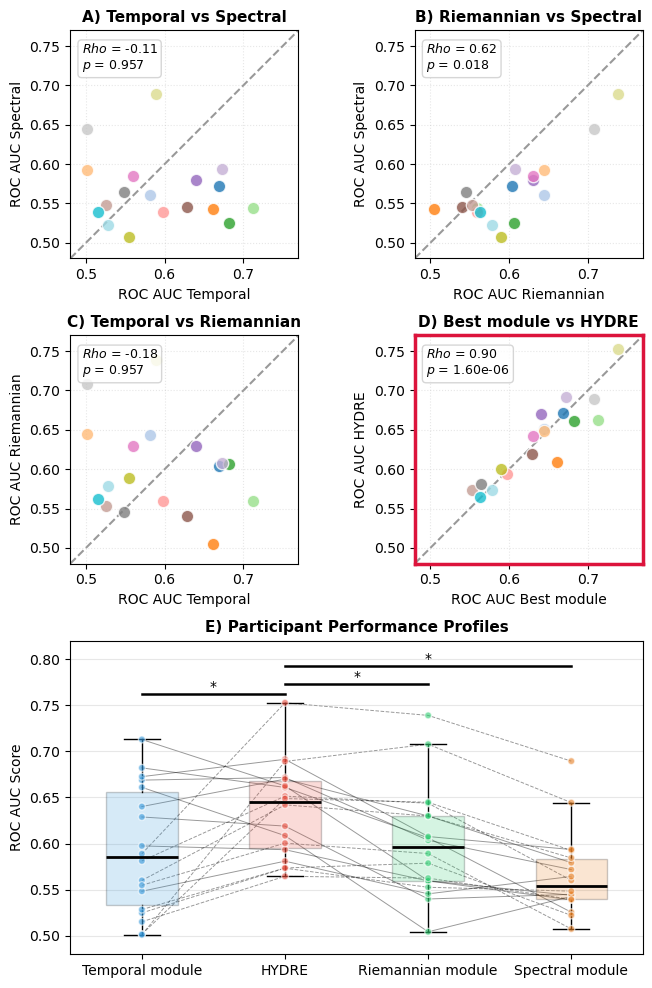

In [23]:
# --- FINALIZED FIGURE  CORRELATION PLOTS HYDRE & OTHER MODULES + BOXPLOT ---
# --- 1. SETUP THE GRID ---
heights = [0.8, 0.8, 1.1] 
fig = plt.figure(figsize=(10, 12))

# --- ADJUSTED SPACING ---
# wspace: horizontal spacing (reduced to 0.02)
# hspace: vertical spacing (reduced to 0.3)
gs = gridspec.GridSpec(3, 2, height_ratios=heights, hspace=0.3, wspace=-0.2)

limit_min, limit_max = 0.48, 0.77

# --- 2. THE 4 SCATTER PLOTS ---
axes_scatter = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
                fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

handles_scatter = [] 

for i, (ax, (data_x, data_y, label_x, label_y)) in enumerate(zip(axes_scatter, combinations)):
    letter = string.ascii_uppercase[i]
    ax.plot([limit_min, limit_max], [limit_min, limit_max], 
            linestyle='--', color='black', alpha=0.4, zorder=1)
    
    for j, subject in enumerate(subjects_id):
        sc = ax.scatter(data_x[j], data_y[j], color=colors[j], s=80, 
                        edgecolors='w', alpha=0.8, zorder=2, label=subject)
        if i == 0: handles_scatter.append(sc)
    
    stats_text = (f"$Rho$ = {corr_combinaison[i]:.2f}\n$p$ = {pvals_corrected[i]:.2e}" 
                  if pvals_corrected[i] < 0.001 
                  else f"$Rho$ = {corr_combinaison[i]:.2f}\n$p$ = {pvals_corrected[i]:.3f}")

    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
            verticalalignment='top', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='0.8'))
    
    ax.set_xlabel(f"ROC AUC {label_x}")
    ax.set_ylabel(f"ROC AUC {label_y}") 
    ax.set_xlim(limit_min, limit_max)
    ax.set_ylim(limit_min, limit_max)
    ax.set_box_aspect(1) 
    ax.grid(True, linestyle=':', alpha=0.3)
    
    title_text = f"{letter}) {label_x} vs {label_y}"
    if label_y == "HYDRE":
        ax.set_title(title_text, fontweight='extra bold', color='black', fontsize=11)
        for spine in ax.spines.values():
            spine.set_edgecolor('crimson'), spine.set_linewidth(2.5)
    else:
        ax.set_title(title_text, fontweight='bold', fontsize=11)

# --- 3. THE BOXPLOT ---
ax_box = fig.add_subplot(gs[2, :])
data_to_plot = [x, w, z, y]
box_labels = ['Temporal module', 'HYDRE', 'Riemannian module', 'Spectral module']
box_colors = ['#3498db', '#e74c3c', '#2ecc71', '#e67e22']

box = ax_box.boxplot(data_to_plot, labels=box_labels, patch_artist=True, 
                     medianprops={'color': 'black', 'linewidth': 2},
                     widths=0.5, showfliers=False)


for patch, color in zip(box['boxes'], box_colors):
    patch.set_facecolor(color), patch.set_alpha(0.2)

x_indices = np.arange(1, len(box_labels) + 1)
for i in range(len(w)):
    participant_scores = [x[i], w[i], z[i], y[i]]
    line_color ='k'
    line_style = '-' if x[i] > z[i] else '--'
    ax_box.plot(x_indices, participant_scores, color=line_color, alpha=0.4 , linewidth=0.7, linestyle=line_style,zorder=1)
    ax_box.scatter(x_indices, participant_scores, color=box_colors, s=25, edgecolors='white', alpha=0.6, zorder=2)

# Boxplot Styling
legend_elements = [
    Line2D([0], [0], linestyle='-', color='k', lw=3, label='Temporal > Riemannian'), #  color='#3498db',
    Line2D([0], [0], linestyle='--', color='k', lw=3, label='Riemannian > Temporal') #  color='#2ecc71', 
]
ax_box.set_title('E) Participant Performance Profiles', fontweight='bold', fontsize=11)
ax_box.set_ylabel('ROC AUC Score')
ax_box.grid(axis='y', linestyle='-', alpha=0.3)
ax_box.set_ylim(limit_min, limit_max+0.05)

def add_sig_line(ax, x1, x2, y, text="*"):
    """Simple horizontal significance line with centered asterisk."""
    ax.plot([x1, x2], [y, y], lw=1.8, c='black', zorder=5)
    ax.text((x1 + x2) / 2, y + 0.00001,
            text,
            ha='center', va='bottom',
            color='black', fontsize=10)

# x positions in boxplot (1-based indexing)
x_temporal = 1
x_hydre = 2
x_riemann = 3
x_spectral = 4

# compute a safe y level above whiskers/data
all_data = np.array(data_to_plot)
y_max = np.nanmax(all_data)
offset = 0.01
base_y = y_max + offset

# HYDRE vs Temporal
add_sig_line(ax_box, x_temporal, x_hydre, base_y)

# HYDRE vs Riemannian
add_sig_line(ax_box, x_hydre, x_riemann, base_y + 0.01)

# HYDRE vs Spectral
add_sig_line(ax_box, x_hydre, x_spectral, base_y + 0.03)

# --- 4. THE ALIGNMENT LOGIC ---
plt.tight_layout(rect=[0, 0, 0.88, 1])
fig.canvas.draw() 

# Grab coordinates of the squares
pos_left = axes_scatter[0].get_position()
pos_right = axes_scatter[1].get_position()
pos_box = ax_box.get_position()

# Snap boxplot to match the exact edges of the squares above
ax_box.set_position([pos_left.x0, pos_box.y0, pos_right.x1 - pos_left.x0, pos_box.height])

plt.show()

Temporal_module Normality p-value: 0.2447
Levene’s Test p-value: 0.1391
HYDRE Normality p-value: 0.4190
Levene’s Test p-value: 0.1391
Riemannian_module Normality p-value: 0.3524
Levene’s Test p-value: 0.1391
Spectral_module Normality p-value: 0.0249
Levene’s Test p-value: 0.1391
##########################################
Friedman Test p-value: 3.787949653574587e-05
Friedman statistic: 23.133333333333326


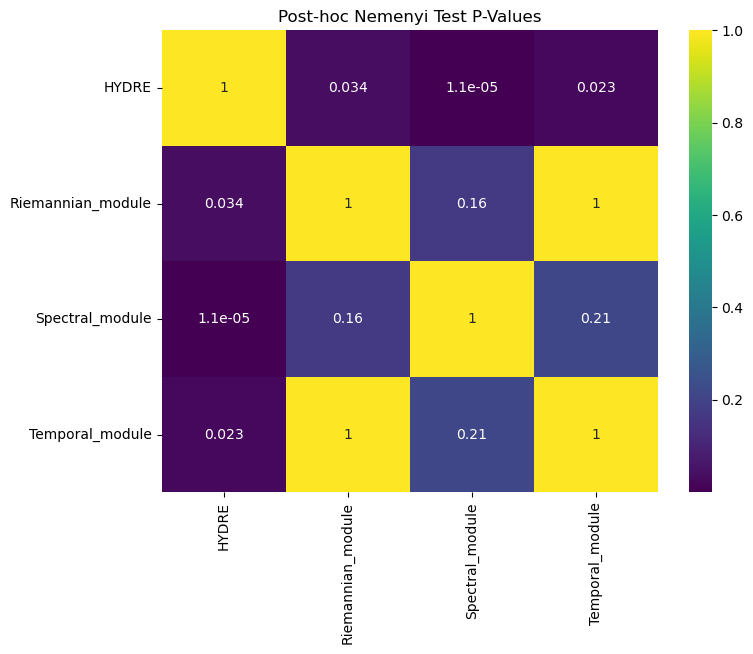

,HYDRE,Riemannian_module,Spectral_module,Temporal_module
HYDRE,1.000000,0.033904,0.000011,0.023358
Riemannian_module,0.033904,1.000000,0.164467,0.999232
Spectral_module,0.000011,0.164467,1.000000,0.212748
Temporal_module,0.023358,0.999232,0.212748,1.000000


In [30]:
# Perform ANOVA test on the scores of the 3 modules & HYDRE at -300ms
df_ANOVA = pd.DataFrame({
    'Participant': subjects_id,
    'Temporal_module': x,
    'HYDRE': w,
    'Riemannian_module': z,
    'Spectral_module': y
})

# Check normality assumption for each group using Shapiro-Wilk test & homosedasticity using Levene's test
for col in ['Temporal_module', 'HYDRE', 'Riemannian_module', 'Spectral_module']:
    stat, p = stats.shapiro(df_ANOVA[col])
    print(f'{col} Normality p-value: {p:.4f}')
    stat, p = stats.levene(df_ANOVA['Temporal_module'], df_ANOVA['HYDRE'], df_ANOVA['Riemannian_module'], df_ANOVA['Spectral_module'])
    print(f'Levene’s Test p-value: {p:.4f}')

print('##########################################')   

# Transform the dataframe: from wide to long format
df_ANOVA_long = pd.melt(df_ANOVA.reset_index(), id_vars=['Participant'], value_vars=['Temporal_module', 'HYDRE', 'Riemannian_module', 'Spectral_module'])
df_ANOVA_long.columns = ['Participant', 'models', 'scores']

# # Perform repeated measures ANOVA
# import pingouin as pg
# aov = pg.rm_anova(dv='scores', within='models', subject='Participant', data=df_ANOVA_long, detailed=True)
# print(aov)

# # Paired post-hoc tests with Bonferroni correction
# posthoc = pg.pairwise_tests(data=df_ANOVA_long, dv='scores', within='models', 
#                             subject='Participant', padjust='holm')
# print(posthoc)

from scipy.stats import friedmanchisquare
# Each column is a related "treatment" or "time point"
stat, p = friedmanchisquare(df_ANOVA['Temporal_module'], df_ANOVA['HYDRE'], df_ANOVA['Riemannian_module'], df_ANOVA['Spectral_module'])
print(f"Friedman Test p-value: {p}")
print('Friedman statistic:', stat)

import scikit_posthocs as sp
# Nemenyi test is the standard post-hoc for Friedman
# Perform the Nemenyi post-hoc test
# Rows = Participants, Columns = Models, Values = Scores
df_wide = df_ANOVA_long.pivot(index='Participant', columns='models', values='scores')
# 2. Drop any rows with missing values (Friedman/Nemenyi requires balanced data)
df_wide = df_wide.dropna()
# 3. Run the Nemenyi test cleanly! No extra arguments needed.
nemenyi_result = sp.posthoc_nemenyi_friedman(df_wide)


import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(nemenyi_result, annot=True, cmap='viridis')
plt.title('Post-hoc Nemenyi Test P-Values')
plt.show()

nemenyi_result


Group-level Complementarity Metrics at time window of interest -300ms to -250ms:
.Test if Kappa is significantly different than 0:
    t-statistic: 6.189, p-value: 9.907647330648633e-06
    Kappa 95% CI: [0.039, 0.080]
.Test if Error correlation is significantly different than 0:
    t-statistic: 5.538, p-value: 0.000
    Ensemble Gain 95% CI: [0.058, 0.130]
.Test if Q-statistic is significantly different than 0:
    t-statistic: 5.680, p-value: 0.000
    Q-statistic 95% CI: [0.115, 0.250]
.Test if Ensemble Gain is significantly dfferent than 0:
    t-statistic: -0.235, p-value: 0.817
    Ensemble Gain 95% CI: [-0.012, 0.010]
Cohen's Kappa temporal evolution:
Mean Spearman Rho: 0.5785
Group-level p-value: 3.814697265625e-06


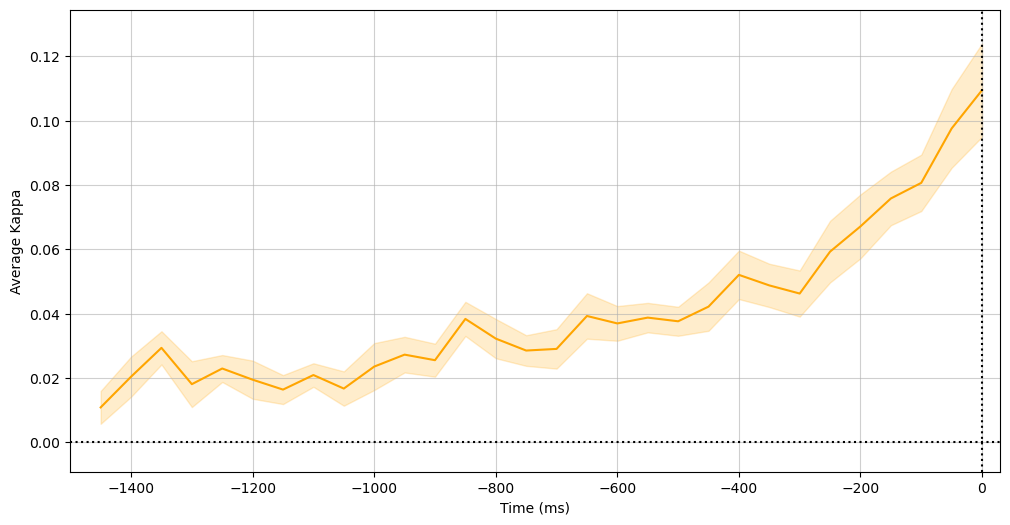

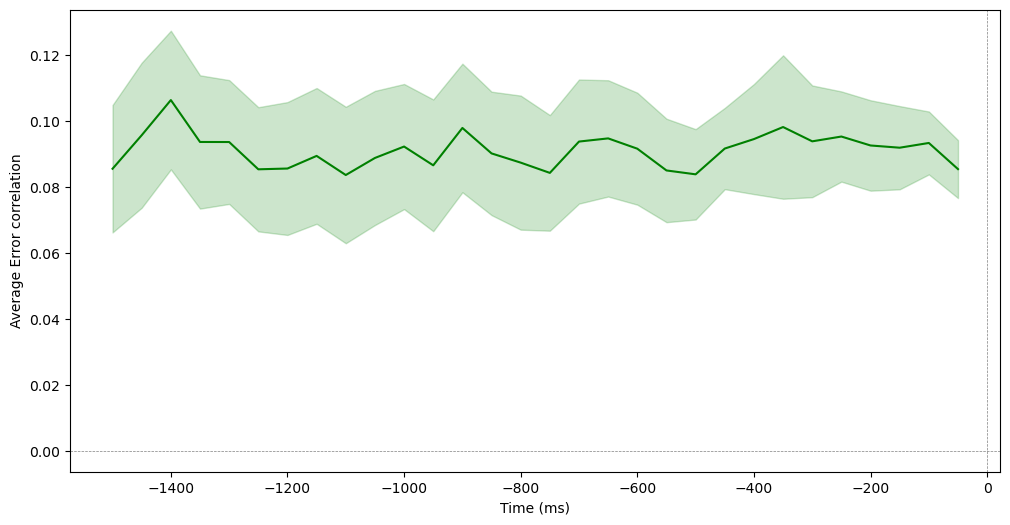

In [43]:
# Analysis of complementarity metrics across participants and time windows

fname1_fig = 'kappa_metrics_time_course.svg'
fname2_fig = 'q_statistic_metrics_time_course.svg'

data_WOI = complementary_df_all_participants[complementary_df_all_participants['time'] == -300]
ensemble_gain = data_WOI['ensemble_gain'].values
avg_q_statistic = data_WOI['avg_q_statistic'].values
avg_kappa = data_WOI['avg_kappa'].values
avg_err_corr = data_WOI['avg_err_corr'].values

# Compute confidence intervals for Kappa and Q-statistic 
confidence = 0.95
# Calculate basics
n = len(avg_kappa)
mean_kappa = np.mean(avg_kappa)
sem_kappa = stats.sem(avg_kappa)  # Standard Error of the Mean

mean_err_corr = np.mean(avg_err_corr)
sem_err_corr = stats.sem(avg_err_corr)

mean_q_statistic = np.mean(avg_q_statistic)
sem_q_statistic = stats.sem(avg_q_statistic)

mean_ensemble_gain = np.mean(ensemble_gain)
sem_ensemble_gain = stats.sem(ensemble_gain)

# Compute the interval using the T-distribution
interval_kappa = stats.t.interval(confidence, df=n-1, loc=mean_kappa, scale=sem_kappa)
interval_q_statistic = stats.t.interval(confidence, df=n-1, loc=mean_q_statistic, scale=sem_q_statistic)
interval_ensemble_gain = stats.t.interval(confidence, df=n-1, loc=mean_ensemble_gain, scale=sem_ensemble_gain)
interval_err_corr = stats.t.interval(confidence, df=n-1, loc=mean_err_corr, scale=sem_err_corr)

print("Group-level Complementarity Metrics at time window of interest -300ms to -250ms:")
# Test if Kappa is significantly greater than 0 (indicating agreement beyond chance)
kappa_ci = stats.ttest_1samp(avg_kappa, 0)
print(".Test if Kappa is significantly different than 0:")
print(f"    t-statistic: {kappa_ci[0]:.3f}, p-value: {kappa_ci[1]}")
print(f"    Kappa 95% CI: [{interval_kappa[0]:.3f}, {interval_kappa[1]:.3f}]")
# Test if Error correlation is significantly different than 0 (indicating improvement)
err_corr_ci = stats.ttest_1samp(avg_err_corr, 0)
print(".Test if Error correlation is significantly different than 0:")
print(f"    t-statistic: {err_corr_ci[0]:.3f}, p-value: {err_corr_ci[1]:.3f}")
print(f"    Ensemble Gain 95% CI: [{interval_err_corr[0]:.3f}, {interval_err_corr[1]:.3f}]")

# Test if Q-statistic is significantly greater than 0 (indicating positive association)
q_stat_ci = stats.ttest_1samp(avg_q_statistic, 0)
print(".Test if Q-statistic is significantly different than 0:")
print(f"    t-statistic: {q_stat_ci[0]:.3f}, p-value: {q_stat_ci[1]:.3f}")
print(f"    Q-statistic 95% CI: [{interval_q_statistic[0]:.3f}, {interval_q_statistic[1]:.3f}]")
# Test if Ensemble Gain is significantly greater than 0 (indicating improvement)
ensemble_gain_ci = stats.ttest_1samp(ensemble_gain, 0)
print(".Test if Ensemble Gain is significantly dfferent than 0:")
print(f"    t-statistic: {ensemble_gain_ci[0]:.3f}, p-value: {ensemble_gain_ci[1]:.3f}")
print(f"    Ensemble Gain 95% CI: [{interval_ensemble_gain[0]:.3f}, {interval_ensemble_gain[1]:.3f}]")


############## Time course of the group average of the complementarity metrics ############
averaged_q_statistic_time_series = complementary_df_all_participants.groupby('time')['avg_q_statistic'].mean().reset_index()
averaged_kappa_time_series = complementary_df_all_participants.groupby('time')['avg_kappa'].mean().reset_index()
averaged_ensemble_gain_time_series = complementary_df_all_participants.groupby('time')['ensemble_gain'].mean().reset_index()
averaged_err_corr_time_series = complementary_df_all_participants.groupby('time')['avg_err_corr'].mean().reset_index()

std_q_statistic_time_series = complementary_df_all_participants.groupby('time')['avg_q_statistic'].std().reset_index()
std_kappa_time_series = complementary_df_all_participants.groupby('time')['avg_kappa'].std().reset_index()
std_ensemble_gain_time_series = complementary_df_all_participants.groupby('time')['ensemble_gain'].std().reset_index()
std_err_corr_time_series = complementary_df_all_participants.groupby('time')['avg_err_corr'].std().reset_index()

# compute SEM
grouped = complementary_df_all_participants.groupby('time')['avg_kappa']
sem_kappa_time_series = grouped.agg(
    sem=lambda x: x.std(ddof=1) / np.sqrt(len(x))
).reset_index()

grouped = complementary_df_all_participants.groupby('time')['avg_err_corr']
sem_err_corr_time_series = grouped.agg(
    sem=lambda x: x.std(ddof=1) / np.sqrt(len(x))
).reset_index()

# Test if the kappa value is significantly raising across time
pivot_df = complementary_df_all_participants.pivot(index='participant', columns='time', values='avg_kappa')
# 2. Convert the pivoted dataframe into a numpy array
kappa_array = pivot_df.to_numpy()
n_participants = kappa_array.shape[0]
n_times = kappa_array.shape[1]
time_vector = np.arange(n_times)
rho_values = []
for i in range(n_participants):
     # We only care about the correlation coefficient (rho)
     rho, _ = stats.spearmanr(time_vector,kappa_array[i, :])
     rho_values.append(rho)
rho_values = np.array(rho_values)
# 2. Test if the distribution of rhos is significantly > 0
stat, p_value = stats.wilcoxon(rho_values - 0, alternative='greater')
print("Cohen's Kappa temporal evolution:")
print(f"Mean Spearman Rho: {np.mean(rho_values):.4f}")
print(f"Group-level p-value: {p_value}")
  
# # Plotting the time course of the group average of Kappa with sem
# plt.figure(figsize=(12, 6))
# plt.plot(averaged_kappa_time_series['time'], averaged_kappa_time_series['avg_kappa'], label='Group averaged Kappa', color='orange')
# plt.fill_between(averaged_kappa_time_series['time'], 
#                  averaged_kappa_time_series['avg_kappa'] - sem_kappa_time_series['sem'], 
#                  averaged_kappa_time_series['avg_kappa'] + sem_kappa_time_series['sem'], 
#                  color='orange', alpha=0.2)
# plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
# plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
# plt.xlabel('Time (ms)')
# plt.ylabel('Average Kappa')
# # plt.legend(loc='upper left')
# if saving:
#      plt.savefig(op.join(path_figure, fname1_fig), dpi=300)
# if viz_plot:
#     plt.show()





plt.figure(figsize=(12, 6))
plt.plot(
    averaged_kappa_time_series['time']+50,
    averaged_kappa_time_series['avg_kappa'],
    label='Group averaged Kappa',
    color='orange',
    zorder=2,
)
plt.fill_between(
    averaged_kappa_time_series['time']+50,
    averaged_kappa_time_series['avg_kappa'] - sem_kappa_time_series['sem'],
    averaged_kappa_time_series['avg_kappa'] + sem_kappa_time_series['sem'],
    color='orange',
    alpha=0.2,
    zorder=1,
)

# Added grid behind the plot elements
plt.grid(True, alpha=0.6, zorder=0)

# Made lines darker and thicker (and set zorder to render on top)
plt.axhline(0, color='black', linestyle=':', linewidth=1.5, zorder=3)
plt.axvline(0, color='black', linestyle=':', linewidth=1.5, zorder=3)

# Ensures the plot touches the vertical line at 0
plt.ylim(
    averaged_kappa_time_series['avg_kappa'].min()-0.020,
    averaged_kappa_time_series['avg_kappa'].max()+0.025,
)
plt.xlim(
    averaged_kappa_time_series['time'].min(),
    averaged_kappa_time_series['time'].max()+80,
)

plt.xlabel('Time (ms)')
plt.ylabel('Average Kappa')

if saving:
  plt.savefig(op.join(path_figure, fname1_fig), dpi=300)
if viz_plot:
  plt.show()






# Plotting the time course of the group average of Error correlation with sem
plt.figure(figsize=(12, 6))
plt.plot(averaged_err_corr_time_series['time'], averaged_err_corr_time_series['avg_err_corr'], label='Group averaged Error Correlation', color='green')
plt.fill_between(averaged_err_corr_time_series['time'], 
                 averaged_err_corr_time_series['avg_err_corr'] - sem_err_corr_time_series['sem'], 
                 averaged_err_corr_time_series['avg_err_corr'] + sem_err_corr_time_series['sem'], 
                 color='green', alpha=0.2)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.xlabel('Time (ms)')
plt.ylabel('Average Error correlation')
# plt.legend(loc='upper left')
if saving:
     plt.savefig(op.join(path_figure, fname1_fig), dpi=300)
if viz_plot:
    plt.show()

SUPPLEMENTARY FIGURES

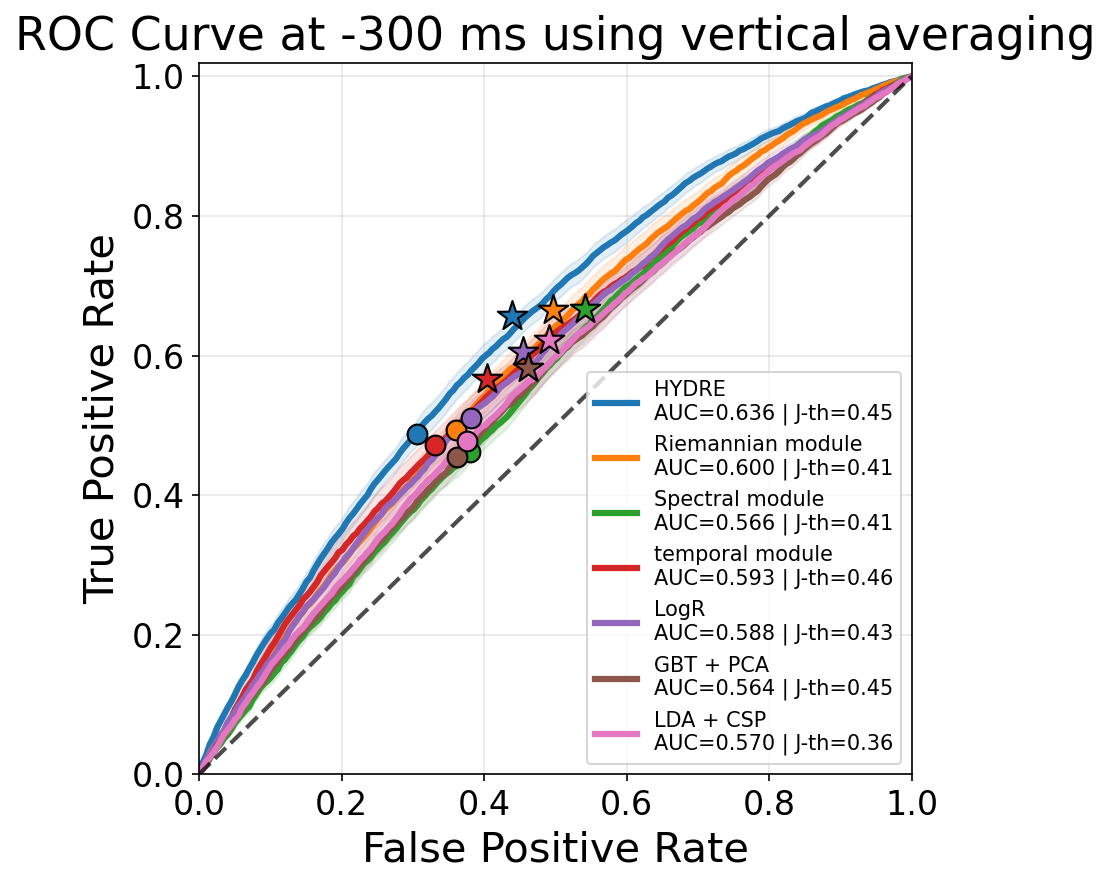

In [27]:
# Plotting the ROC curve at -300ms for all methods
time_point = -300

methods = [
    "HYDRE",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR",
    "GBT + PCA",
    "LDA + CSP"
]

# method = ["HYDRE3"]

mean_fpr = np.linspace(0, 1, 200)

plt.figure(figsize=(6, 6), dpi=150)

for method in methods:

    # =====================================================
    # Select dataframe and probability column
    # =====================================================

    if method == "HYDRE":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_ensemble"

    elif method == "Riemannian module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_riemann"

    elif method == "Spectral module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_tfr"

    elif method == "temporal module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_temporal"

    elif method == "LogR":
        df_base = df_detailed_LogR_all_subjects
        proba_col = "proba"

    elif method == "GBT + PCA":
        df_base = df_detailed_GBT_PCA_all_subjects
        proba_col = "proba"

    elif method == "LDA + CSP":
        df_base = df_detailed_LDA_CSP_all_subjects
        proba_col = "proba"

    df = df_base[df_base["time"] == time_point]

    # =====================================================
    # Subject-wise computations
    # =====================================================

    tpr_all_methods = []
    aucs = []

    # threshold = 0.5
    fpr_05_list = []
    tpr_05_list = []

    # Youden J
    fpr_j_list = []
    tpr_j_list = []

    youden_thresholds = []

    for participant_id, df_sub in df.groupby("participant_id"):

        y_true = df_sub["y_true"]
        y_score = df_sub[proba_col]

        fpr, tpr, thresholds = roc_curve(y_true, y_score)


        # -----------------------
        # AUC
        # -----------------------

        aucs.append(auc(fpr, tpr))

        # -----------------------
        # Mean ROC interpolation
        # -----------------------

        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        interp_tpr[-1] = 1.0

        tpr_all_methods.append(interp_tpr)
        

        # -----------------------
        # Threshold 0.5
        # -----------------------
        idx_05 = np.argmin(np.abs(thresholds - 0.5))

        fpr_05_list.append(fpr[idx_05])
        tpr_05_list.append(tpr[idx_05])

        # -----------------------
        # Youden J
        # -----------------------

        j_scores = tpr - fpr
        idx_j = np.argmax(j_scores)

        fpr_j_list.append(fpr[idx_j])
        tpr_j_list.append(tpr[idx_j])

        youden_thresholds.append(thresholds[idx_j])

    # =====================================================
    # Group-level summaries
    # =====================================================

    mean_tpr = np.mean(tpr_all_methods, axis=0)
    sem_tpr = np.std(tpr_all_methods, axis=0, ddof=1) / np.sqrt(len(tpr_all_methods))

    mean_auc = np.mean(aucs)
    sem_auc = np.std(aucs, ddof=1) / np.sqrt(len(aucs))

    mean_fpr_05 = np.mean(fpr_05_list)
    mean_tpr_05 = np.mean(tpr_05_list)

    mean_fpr_j = np.mean(fpr_j_list)
    mean_tpr_j = np.mean(tpr_j_list)

    mean_youden_threshold = np.mean(youden_thresholds)

    # =====================================================
    # ROC curve
    # =====================================================

    line, = plt.plot(
        mean_fpr,
        mean_tpr,
        linewidth=3,
        label=(
            f"{method}\n"
            f"AUC={mean_auc:.3f} | "
            f"J-th={mean_youden_threshold:.2f}"
        )
    )

    color = line.get_color()

    # =====================================================
    # SEM areas
    # =====================================================

    plt.fill_between(
        mean_fpr,
        np.clip(mean_tpr - sem_tpr, 0, 1),
        np.clip(mean_tpr + sem_tpr, 0, 1),
        color=color,
        alpha=0.12
    )

    # =====================================================
    # Threshold 0.5 point
    # =====================================================

    plt.scatter(
        mean_fpr_05,
        mean_tpr_05,
        s=90,
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=6
    )

    # =====================================================
    # Mean Youden point
    # =====================================================

    plt.scatter(
        mean_fpr_j,
        mean_tpr_j,
        s=220,
        marker="*",
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=7
    )

# =========================================================
# Chance line
# =========================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=2,
    alpha=0.7,
)

# =========================================================
# Formatting
# =========================================================

plt.title(f"ROC Curve at {time_point} ms using vertical averaging", fontsize=22)

plt.xlabel("False Positive Rate", fontsize=20)
plt.ylabel("True Positive Rate", fontsize=20)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)

plt.legend(
    fontsize=10,
    loc="lower right",
    frameon=True
)

plt.tight_layout()
plt.show()

In [21]:
# Compute Hybrid model gain Ieracitano 2021
best_Ieracitano = np.array([65.56, 62.96, 86.67, 92.22, 64.44, 58.52, 59.26, 71.85, 72.59, 67.41, 60.37, 71.85, 63.33, 69.63, 65.89])
hybrid = np.array([74.07, 66.30, 92.59, 97.04, 74.07, 71.48, 66.67, 80.74, 76.30, 70.37, 73.70, 71.85, 72.96, 80.74, 74.20])

gain = hybrid - best_Ieracitano 
average_gain= np.mean(gain)
std_gain= np.std(gain)

print(f"Average gain Ieracitano et al 2021: {average_gain}")
print(f"Std gain Ieracitano et al 2021: {std_gain}")

Average gain Ieracitano et al 2021: 7.368666666666668
Std gain Ieracitano et al 2021: 3.7190874627461445


C:\Users\Romar\AppData\Local\Temp\ipykernel_30328\111950390.py:59: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax_box.boxplot(data_to_plot, labels=box_labels, patch_artist=True,
C:\Users\Romar\AppData\Local\Temp\ipykernel_30328\111950390.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1])


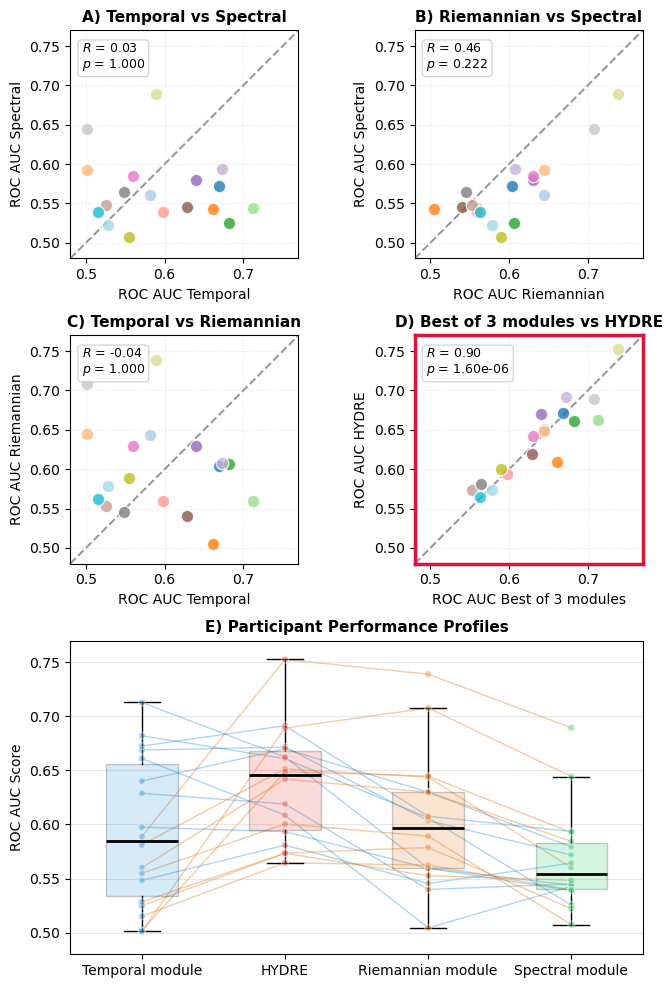

In [22]:
# --- FINALIZED FIGURE  CORRELATION PLOTS HYDRE & OTHER MODULES + BOXPLOT ---
# --- 1. SETUP THE GRID ---
# heights: [row1, row2, boxplot_row]
heights = [0.8, 0.8, 1.1] 
fig = plt.figure(figsize=(10, 12))

# --- ADJUSTED SPACING ---
# wspace: horizontal spacing (reduced to 0.02)
# hspace: vertical spacing (reduced to 0.3)
gs = gridspec.GridSpec(3, 2, height_ratios=heights, hspace=0.3, wspace=-0.2)

limit_min, limit_max = 0.48, 0.77

# --- 2. THE 4 SCATTER PLOTS ---
axes_scatter = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
                fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

handles_scatter = [] 

for i, (ax, (data_x, data_y, label_x, label_y)) in enumerate(zip(axes_scatter, combinations)):
    letter = string.ascii_uppercase[i]
    ax.plot([limit_min, limit_max], [limit_min, limit_max], 
            linestyle='--', color='black', alpha=0.4, zorder=1)
    
    for j, subject in enumerate(subjects_id):
        sc = ax.scatter(data_x[j], data_y[j], color=colors[j], s=80, 
                        edgecolors='w', alpha=0.8, zorder=2, label=subject)
        if i == 0: handles_scatter.append(sc)
    
    stats_text = (f"$R$ = {corr_combinaison[i]:.2f}\n$p$ = {pvals_corrected[i]:.2e}" 
                  if pvals_corrected[i] < 0.001 
                  else f"$R$ = {corr_combinaison[i]:.2f}\n$p$ = {pvals_corrected[i]:.3f}")

    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
            verticalalignment='top', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='0.8'))
    
    ax.set_xlabel(f"ROC AUC {label_x}")
    ax.set_ylabel(f"ROC AUC {label_y}") 
    ax.set_xlim(limit_min, limit_max)
    ax.set_ylim(limit_min, limit_max)
    ax.set_box_aspect(1) 
    ax.grid(True, linestyle=':', alpha=0.3)
    
    title_text = f"{letter}) {label_x} vs {label_y}"
    if label_y == "HYDRE":
        ax.set_title(title_text, fontweight='extra bold', color='black', fontsize=11)
        for spine in ax.spines.values():
            spine.set_edgecolor('crimson'), spine.set_linewidth(2.5)
    else:
        ax.set_title(title_text, fontweight='bold', fontsize=11)

# --- 3. THE BOXPLOT ---
ax_box = fig.add_subplot(gs[2, :])
data_to_plot = [x, w, z, y]
box_labels = ['Temporal module', 'HYDRE', 'Riemannian module', 'Spectral module']
box_colors = ['#3498db', '#e74c3c', '#e67e22', '#2ecc71']

box = ax_box.boxplot(data_to_plot, labels=box_labels, patch_artist=True, 
                     medianprops={'color': 'black', 'linewidth': 2},
                     widths=0.5, showfliers=False)


for patch, color in zip(box['boxes'], box_colors):
    patch.set_facecolor(color), patch.set_alpha(0.2)

x_indices = np.arange(1, len(box_labels) + 1)
for i in range(len(w)):
    participant_scores = [x[i], w[i], z[i], y[i]]
    line_color = '#3498db' if x[i] > z[i] else '#e67e22'
    ax_box.plot(x_indices, participant_scores, color=line_color, alpha=0.4, linewidth=1, zorder=1)
    ax_box.scatter(x_indices, participant_scores, color=box_colors, s=25, edgecolors='white', alpha=0.4, zorder=2)

# Boxplot Styling
legend_elements = [
    Line2D([0], [0], color='#3498db', lw=2, label='Temporal > Riemannian'),
    Line2D([0], [0], color='#e67e22', lw=2, label='Riemannian > Temporal')
]
# ax_box.legend(handles=legend_elements, loc='upper left', frameon=True, fontsize=9)
ax_box.set_title('E) Participant Performance Profiles', fontweight='bold', fontsize=11)
ax_box.set_ylabel('ROC AUC Score')
ax_box.grid(axis='y', linestyle='-', alpha=0.3)
ax_box.set_ylim(limit_min, limit_max)

# --- 4. THE ALIGNMENT LOGIC ---
plt.tight_layout(rect=[0, 0, 0.88, 1])
fig.canvas.draw() 

# Grab coordinates of the squares
pos_left = axes_scatter[0].get_position()
pos_right = axes_scatter[1].get_position()
pos_box = ax_box.get_position()

# Snap boxplot to match the exact edges of the squares above
ax_box.set_position([pos_left.x0, pos_box.y0, pos_right.x1 - pos_left.x0, pos_box.height])

plt.show()

HYDRE3 first becomes significantly better than chance at: -1500.0 ms
Average ROC AUC at -300ms for HYDRE3: 0.636
HYDRE2 first becomes significantly better than chance at: -1500.0 ms
Average ROC AUC at -300ms for HYDRE2: 0.640


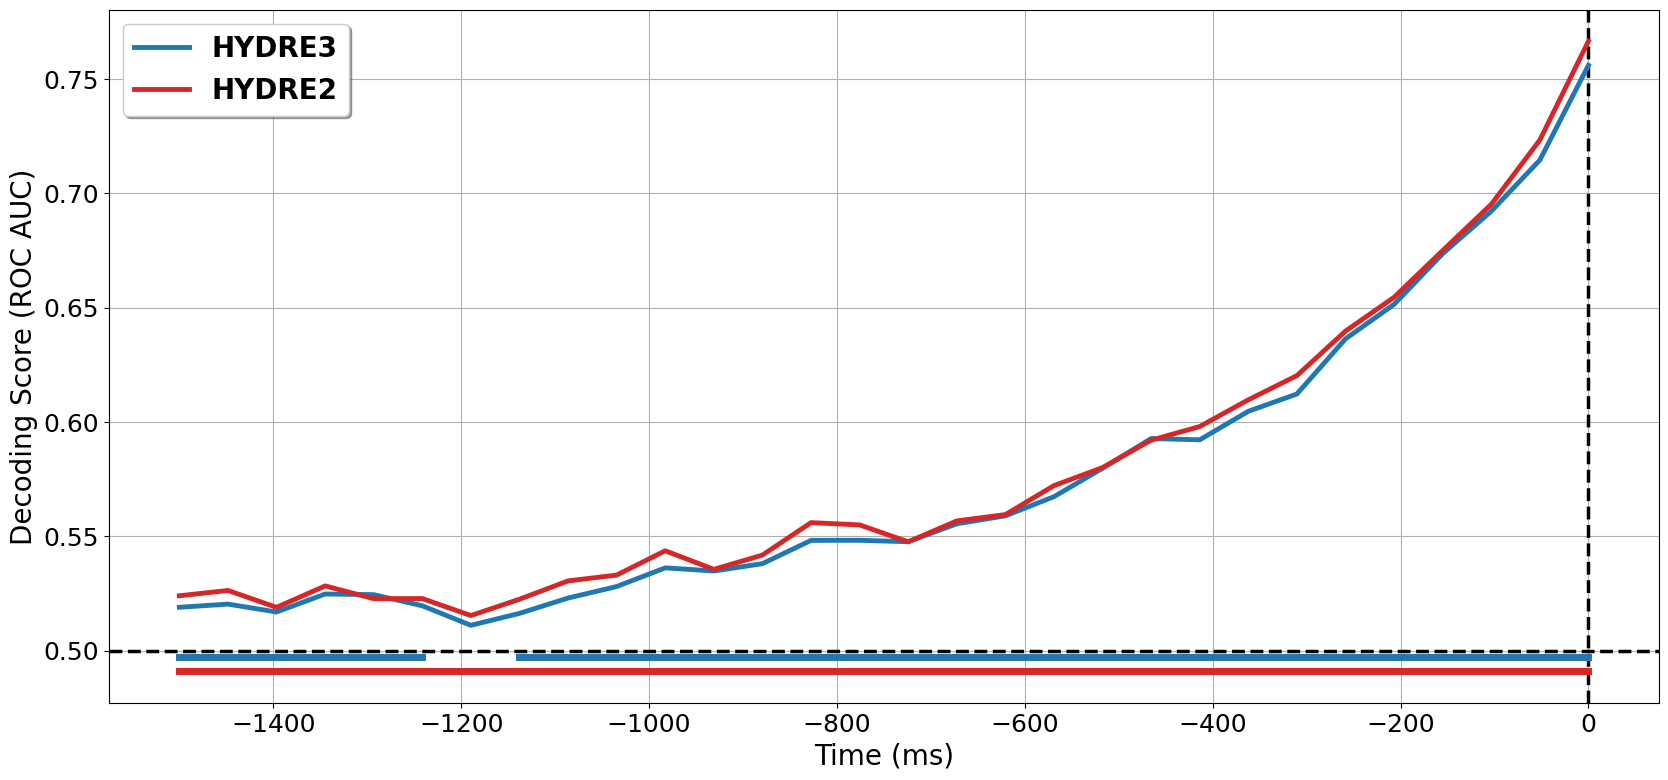

In [35]:
# Comparing HYDRE with and whitout the spectrale module
methods=[ "HYDRE3", "HYDRE2"]
    
fname_fig_accu = 'decoding_time_course_HYDRE3_&_other_methods.svg' 

mask_methods = list()
all_roc_all_methods = list()

for method in methods:
    all_roc = list()
    for n_subject, subject in enumerate(subjects_id):
        
        # path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_vf_voting_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50'))
        # df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_vf_voting_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50.csv' % subject))
        path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
        df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))
        df_detailed_HYDRE['proba_ensemble_2mod'] = (df_detailed_HYDRE[['proba_temporal', 'proba_riemann']].mean(axis=1))
        roc_scores = []

        for time_point in df_detailed_HYDRE['time'].unique():
            # Select data for the current time window
            data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
            # Compute ROC AUC for HYDRE and each module
            if method == "HYDRE3":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
                
            if method == "HYDRE2":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble_2mod'].values))      

        all_roc.append(roc_scores)

    p_val = decod_stats(np.array(all_roc)-1/2.)
    wh_sign = p_val<0.05
    mask_methods.append(wh_sign)
        
    all_roc= np.squeeze(np.mean(all_roc, axis=0))
    all_roc_all_methods.append(all_roc)   

    
# Plot all methods
times = np.linspace(-1500, 0, np.squeeze(all_roc_all_methods[0].shape)) #transform x axis from timestamps to seconds

# Print the time at which the worst performing model first became significantly better than chance
for i, method in enumerate(methods):

    first_significant_time = times[np.where(mask_methods[i])[0][0]]
    print(f"{method} first becomes significantly better than chance at: {first_significant_time:.1f} ms")
    average_score_300ms = all_roc_all_methods[i][-6]
    print(f"Average ROC AUC at -300ms for {method}: {average_score_300ms:.3f}")


# Colors for each method (high contrast)
colors = [ '#1f77b4', '#d62728']
labels = [ "HYDRE3", "HYDRE2"]
pos_bar = [0.497, 0.491]
# Create the plot
plt.figure(figsize=(20, 9))

plt.axvline(0., color='k', linestyle= '--', linewidth=2.5)
plt.axhline(0.5, color='k', linestyle= '--', linewidth=2.5)

# Loop over the decoding scores and plot each one
for i in range(len(all_roc_all_methods)):
    sign_pos=np.full(mask_methods[i].shape, pos_bar[i])
    sign_pos[~mask_methods[i]] = np.nan

    plt.plot(times, all_roc_all_methods[i], label= labels[i], color=colors[i], linewidth=3.5)
    # Plot significant difference between groups
    plt.plot(times,sign_pos,color=colors[i], linewidth=5)

# Add labels and title
plt.xlabel('Time (ms)', fontsize=20)
plt.ylabel('Decoding Score (ROC AUC)', fontsize=20)

# Increase tick size
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Customize legend
plt.legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})

# Add grid
plt.grid(True)

# Save the figure
if saving:
    plt.savefig(os.path.join(path_figure, fname_fig_accu), format='svg', dpi=300)
# Show the plot
if viz_plot:
    plt.show()

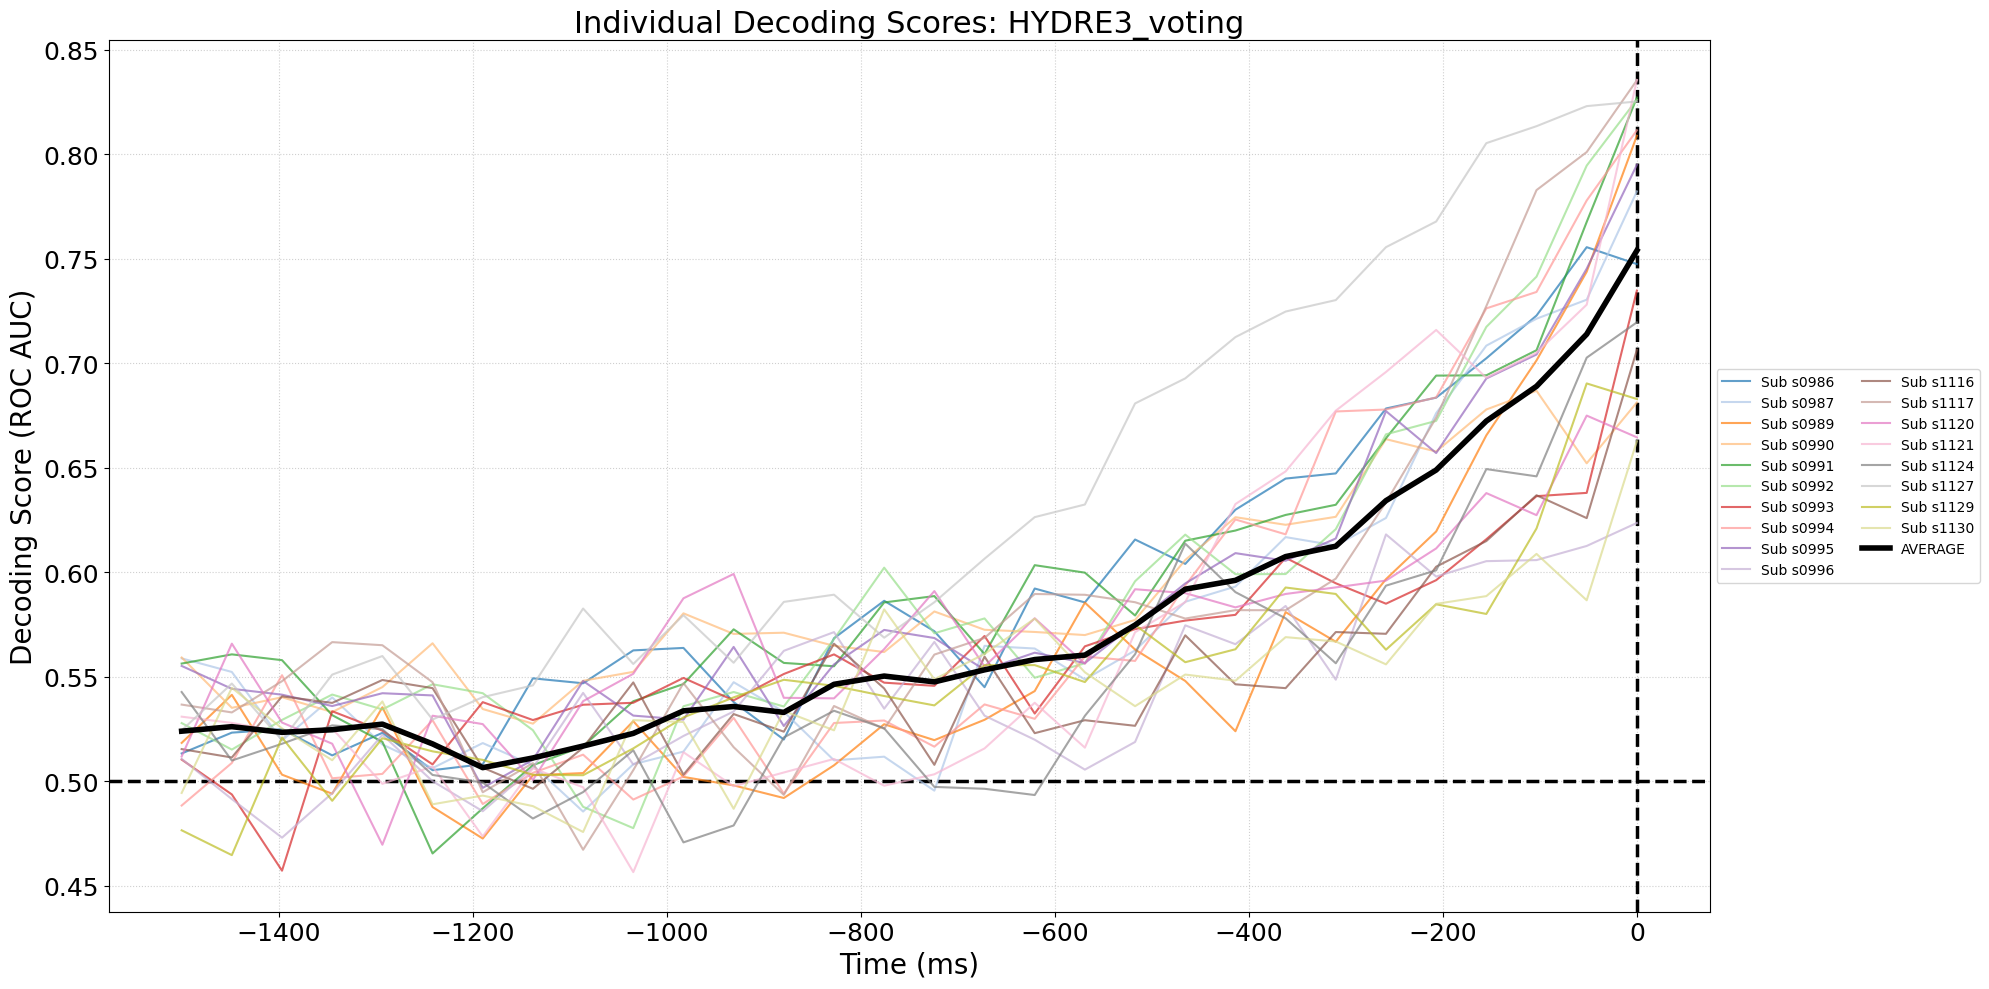

In [6]:
# Plotting the decoding scores for each participant and the group average for a HYDRE classifier

selected_method = "HYDRE3_vf_voting_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50"
method_label = "HYDRE3_voting"

fname_fig = 'HYDRE3_decoding_over_time_subjects_&_average.svg'

all_subject_rocs = []

# 2. Process only the selected method
for n_subject, subject in enumerate(subjects_id):
    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', selected_method))
    
    # Handle naming conventions based on method string
    data_roc = '%s_meg_roc_auc_scores_offline_%s.npy' % (subject, selected_method)
    
    # Load the data
    roc_auc = np.load(Path(path_scores, data_roc))
    
    # Specific fix for the sliding window offset
    if selected_method == "TS_LogR_win200_sl50":
        roc_auc = np.insert(roc_auc, 0, [roc_auc[0]] * 3)

    all_subject_rocs.append(roc_auc)

# Setup Time Axis
# Assuming all subject data has the same length
n_time_points = all_subject_rocs[0].shape[0]
times = np.linspace(-1500, 0, n_time_points)

# 3. Create the Plot
plt.figure(figsize=(20, 10))

plt.axvline(0., color='k', linestyle='--', linewidth=2.5)
plt.axhline(0.5, color='k', linestyle='--', linewidth=2.5)

# Use a colormap to give each participant a unique color
cmap = plt.get_cmap('tab20') 

for i, subject_roc in enumerate(all_subject_rocs):
    plt.plot(times, subject_roc, 
             label=f'Sub {subjects_id[i]}', 
             color=cmap(i % 20), 
             linewidth=1.5, 
             alpha=0.7) # Slightly transparent to see overlapping lines

# Add a thicker line for the average (Optional, but helpful for context)
avg_roc = np.mean(all_subject_rocs, axis=0)
plt.plot(times, avg_roc, color='black', linewidth=4, label='AVERAGE', zorder=10)

# Labels and Styling
plt.title(f'Individual Decoding Scores: {method_label}', fontsize=22)
plt.xlabel('Time (ms)', fontsize=20)
plt.ylabel('Decoding Score (ROC AUC)', fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Legend - placing it outside if you have many participants
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10, ncol=2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

if saving:
    plt.savefig(Path(path_figure, fname_fig), format='svg', dpi=300)

plt.show()

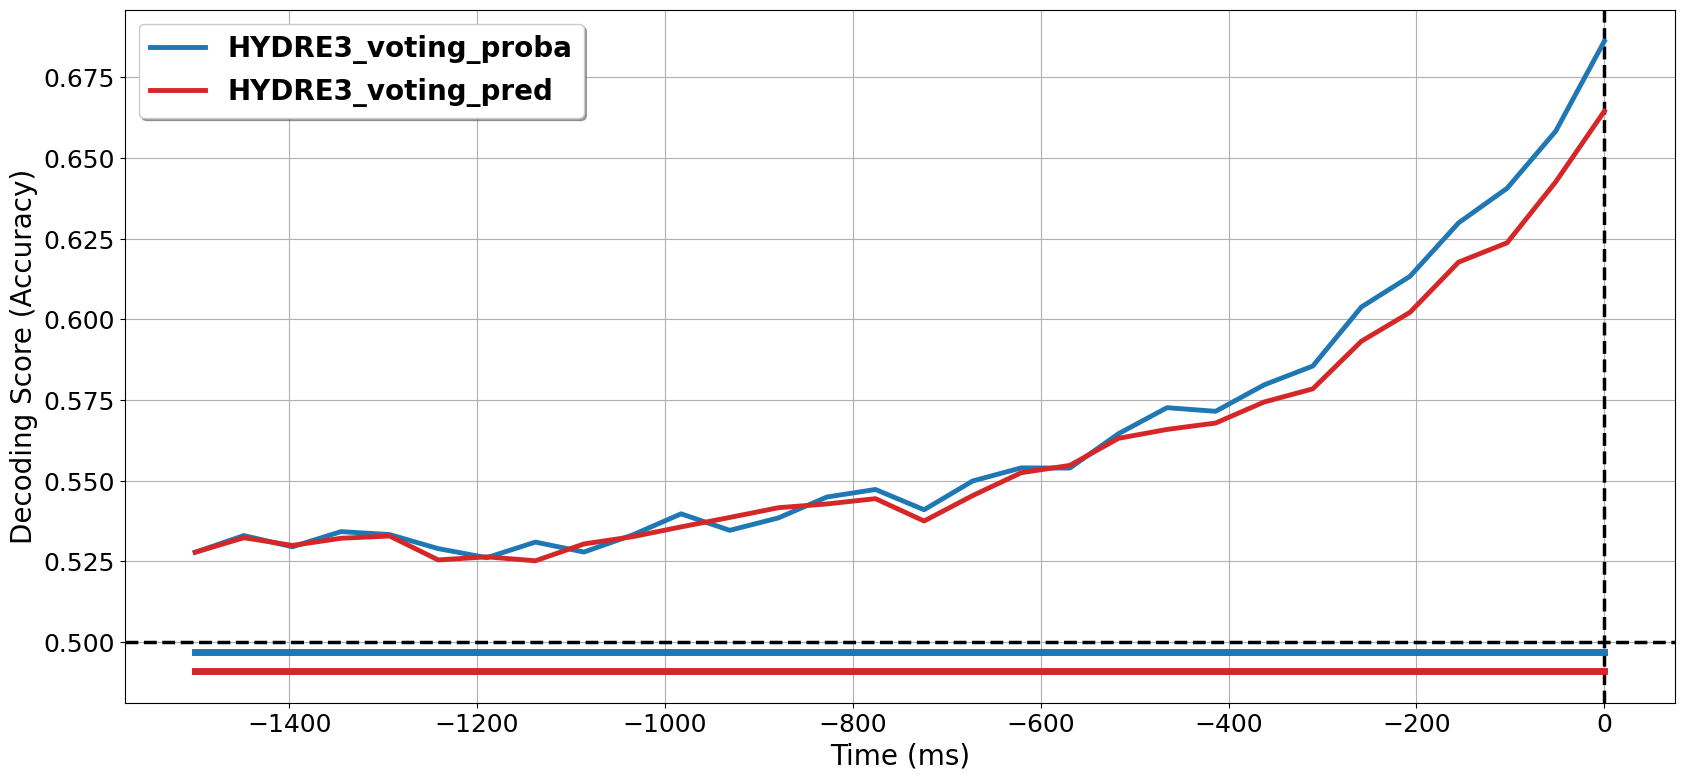

In [31]:
# Comparing the time course of decoding scores for HYDRE and different classical methods
methods=[ "HYDRE3_proba","HYDRE3_pred"]
    
fname_fig_accu = 'decoding_time_course_HYDRE3_voting_proba_vs_predict.svg'

all_accuracy_HYDRE_proba = []
all_accuracy_HYDRE_predict= []

for n_subject, subject in enumerate(subjects_id):
    
    path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
    df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))
    df_detailed_HYDRE['pred_ensemble_predict'] = (df_detailed_HYDRE[['pred_temporal', 'pred_tfr', 'pred_riemann']].sum(axis=1) >= 2).astype(int)
   
    accuracy_HYDRE_proba = []
    accuracy_HYDRE_predict= []

    for time_point in df_detailed_HYDRE['time'].unique():
        # Select data for the current time window
        data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
        # Compute accuracy for HYDRE 
        accuracy_HYDRE_proba.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_ensemble'].values))
        accuracy_HYDRE_predict.append(accuracy_score(data_per_time_win['y_true'].values, data_per_time_win['pred_ensemble_predict'].values))

    all_accuracy_HYDRE_proba.append(accuracy_HYDRE_proba)
    all_accuracy_HYDRE_predict.append(accuracy_HYDRE_predict)

p_val = decod_stats(np.array(all_accuracy_HYDRE_proba)-1/2.)
wh_sign_proba = p_val<0.05
p_val = decod_stats(np.array(all_accuracy_HYDRE_predict)-1/2.)
wh_sign_predict = p_val<0.05
mask_methods= (wh_sign_proba, wh_sign_predict)
    
mean_accu_proba= np.squeeze(np.mean(all_accuracy_HYDRE_proba, axis=0))
mean_accu_predict= np.squeeze(np.mean(all_accuracy_HYDRE_predict, axis=0))
all_roc_all_methods =  mean_accu_proba, mean_accu_predict

    
# Plot all methods
times = np.linspace(-1500, 0, np.squeeze(all_roc_all_methods[0].shape)) #transform x axis from timestamps to seconds
# Colors for each method (high contrast)
colors = [ '#1f77b4', '#d62728']
labels = [ "HYDRE3_voting_proba", "HYDRE3_voting_pred"]
pos_bar = [0.497, 0.491]
# Create the plot
plt.figure(figsize=(20, 9))

plt.axvline(0., color='k', linestyle= '--', linewidth=2.5)
plt.axhline(0.5, color='k', linestyle= '--', linewidth=2.5)

# Loop over the decoding scores and plot each one
for i in range(len(all_roc_all_methods)):
    sign_pos=np.full(mask_methods[i].shape, pos_bar[i])
    sign_pos[~mask_methods[i]] = np.nan

    plt.plot(times, all_roc_all_methods[i], label= labels[i], color=colors[i], linewidth=3.5)
    # Plot significant difference between groups
    plt.plot(times,sign_pos,color=colors[i], linewidth=5)

# Add labels and title
plt.xlabel('Time (ms)', fontsize=20)
plt.ylabel('Decoding Score (Accuracy)', fontsize=20)

# Increase tick size
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Customize legend
plt.legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})

# Add grid
plt.grid(True)

# Save the figure
if saving:
    plt.savefig(os.path.join(path_figure, fname_fig_accu), format='svg', dpi=300)
# Show the plot
if viz_plot:
    plt.show()

OLD Script parts

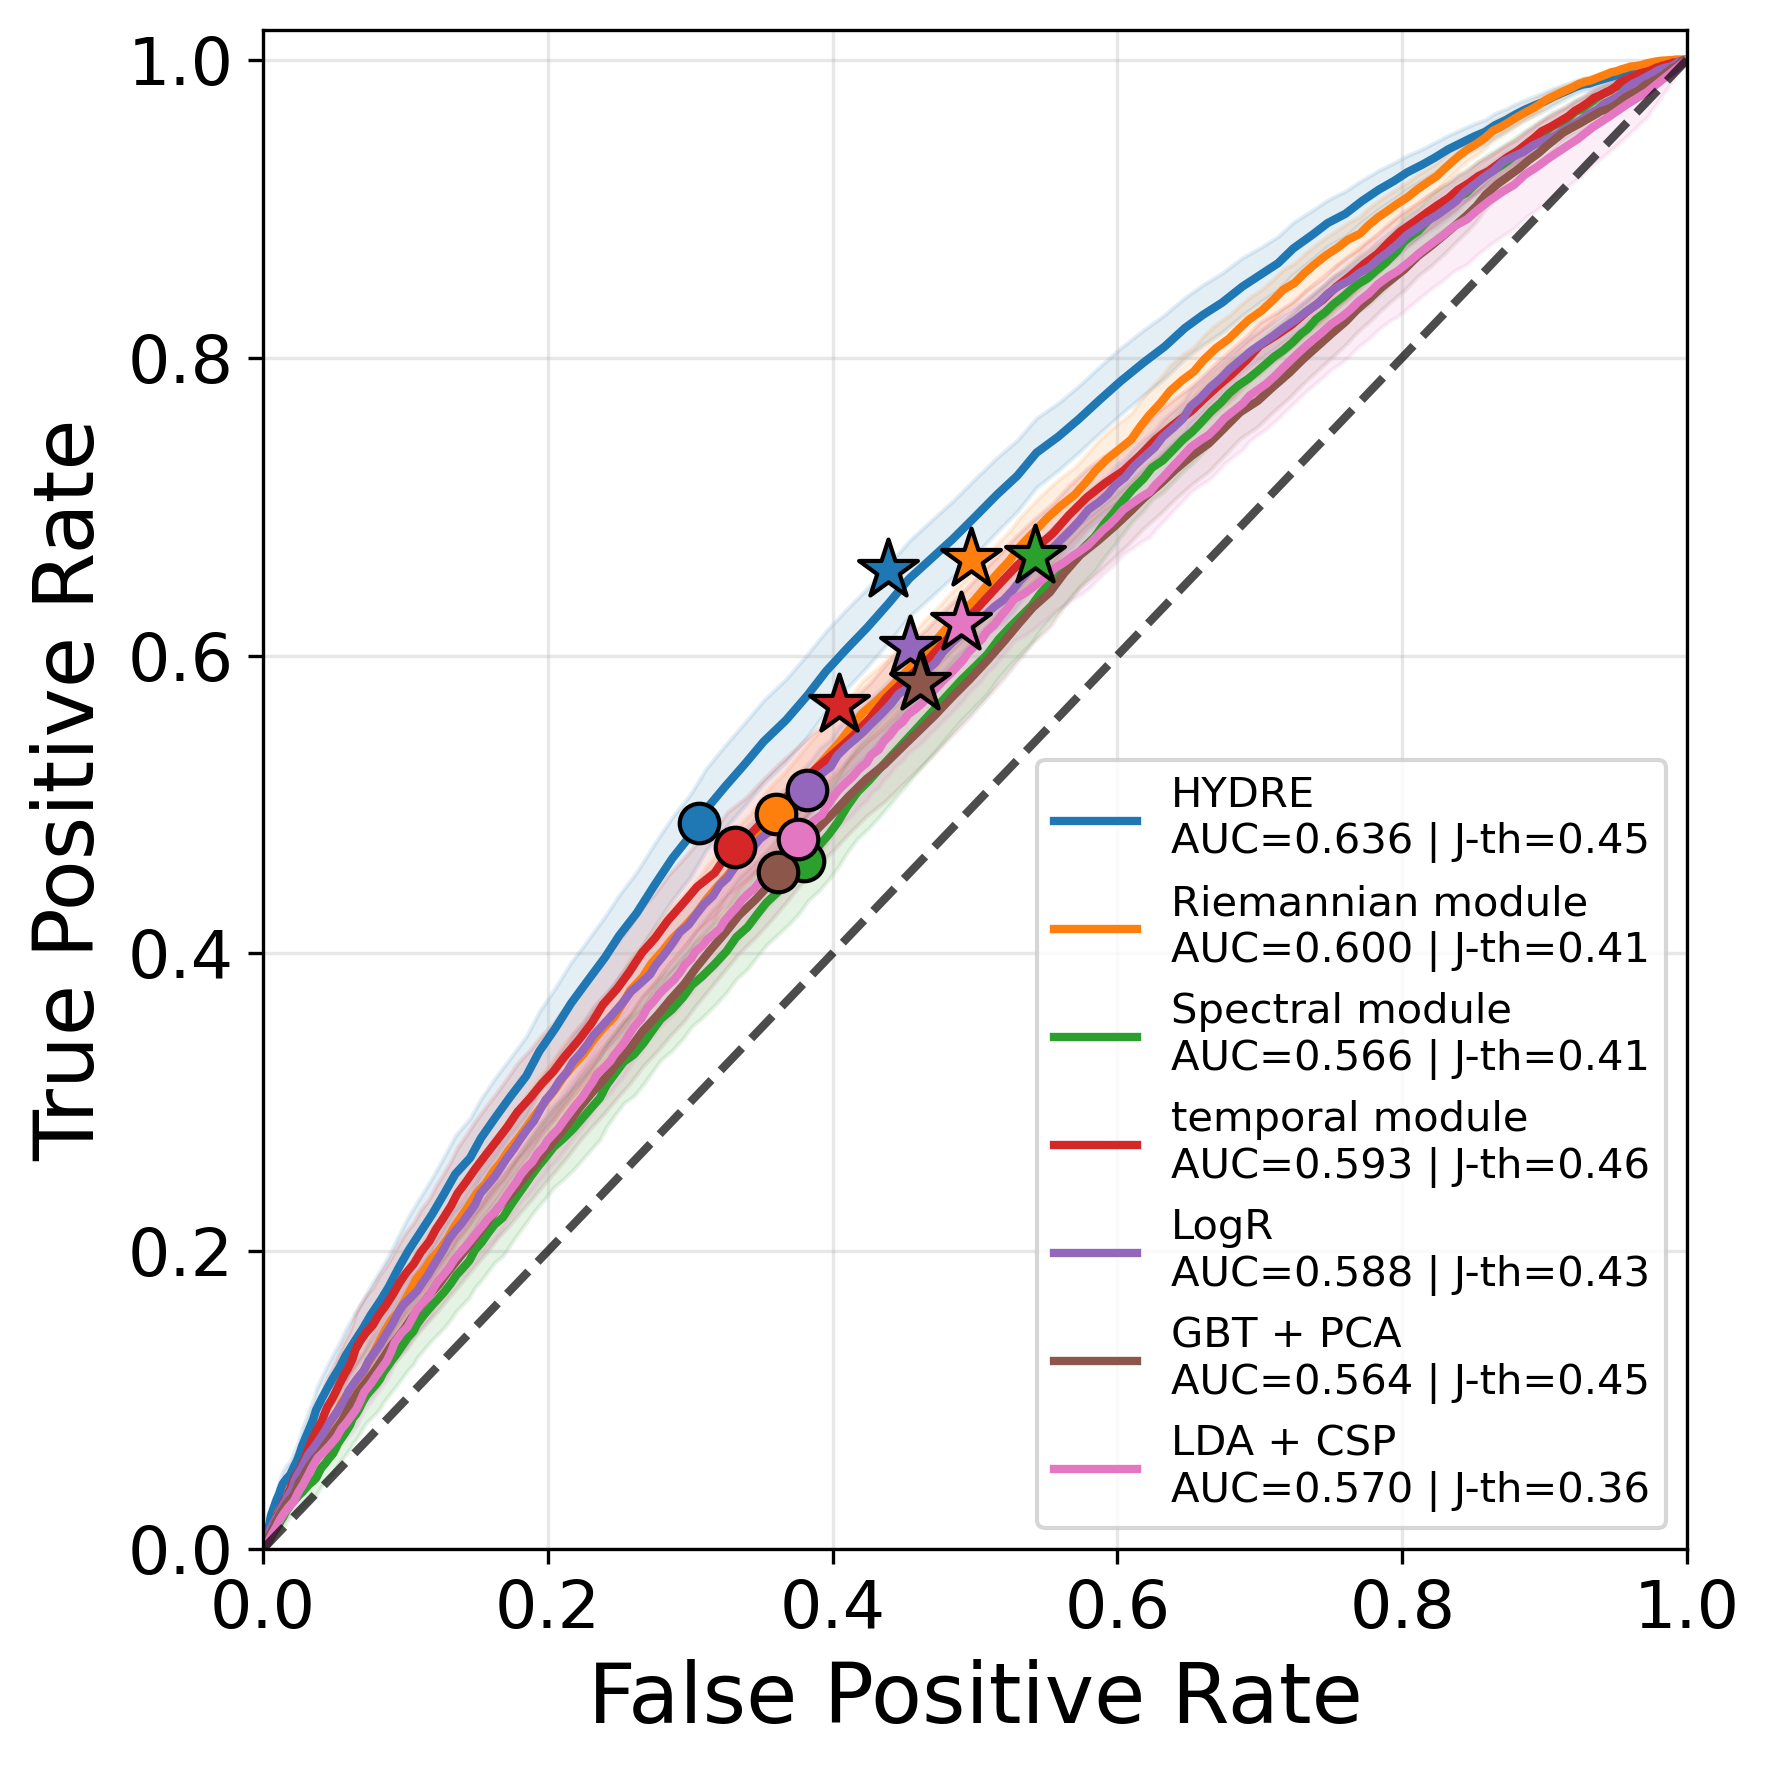

In [ ]:
# Plotting the ROC curve at -300ms for all methods (Threshold-Averaged)
time_point = -300

methods = [
    "HYDRE",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR",
    "GBT + PCA",
    "LDA + CSP"
]

# CHANGE 1: Define a common grid for thresholds (0 to 1) instead of FPR
mean_thresholds = np.linspace(0, 1, 200)

plt.figure(figsize=(6, 6), dpi=300)

for method in methods:

    # =====================================================
    # Select dataframe and probability column
    # =====================================================

    if method == "HYDRE":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_ensemble"

    elif method == "Riemannian module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_riemann"

    elif method == "Spectral module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_tfr"

    elif method == "temporal module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_temporal"

    elif method == "LogR":
        df_base = df_detailed_LogR_all_subjects
        proba_col = "proba"

    elif method == "GBT + PCA":
        df_base = df_detailed_GBT_PCA_all_subjects
        proba_col = "proba"

    elif method == "LDA + CSP":
        df_base = df_detailed_LDA_CSP_all_subjects
        proba_col = "proba"

    df = df_base[df_base["time"] == time_point]

    # =====================================================
    # Subject-wise computations
    # =====================================================

    fprs = []
    tprs = []
    aucs = []
    fpr_05_list = []
    tpr_05_list = []
    fpr_j_list = []
    tpr_j_list = []
    youden_thresholds = []

    for participant_id, df_sub in df.groupby("participant_id"):

        y_true = df_sub["y_true"]
        y_score = df_sub[proba_col]

        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        aucs.append(auc(fpr, tpr))

        # CHANGE 2: np.interp requires the thresholds to be ascending.
        # sklearn outputs them descending, so we must sort them.
        sorted_idx = np.argsort(thresholds)
        sorted_thresholds = thresholds[sorted_idx]
        sorted_fpr = fpr[sorted_idx]
        sorted_tpr = tpr[sorted_idx]

        # CHANGE 3: Interpolate BOTH fpr and tpr over the threshold grid
        interp_fpr = np.interp(mean_thresholds, sorted_thresholds, sorted_fpr)
        interp_tpr = np.interp(mean_thresholds, sorted_thresholds, sorted_tpr)

        fprs.append(interp_fpr)
        tprs.append(interp_tpr)

        # -----------------------
        # Threshold 0.5
        # -----------------------
        idx_05 = np.argmin(np.abs(thresholds - 0.5))
        fpr_05_list.append(fpr[idx_05])
        tpr_05_list.append(tpr[idx_05])

        # -----------------------
        # Youden J
        # -----------------------
        j_scores = tpr - fpr
        idx_j = np.argmax(j_scores)
        fpr_j_list.append(fpr[idx_j])
        tpr_j_list.append(tpr[idx_j])

        youden_thresholds.append(thresholds[idx_j])

    # =====================================================
    # Group-level summaries
    # =====================================================

    # CHANGE 4: Average both coordinates across subjects
    mean_fpr = np.mean(fprs, axis=0)
    mean_tpr = np.mean(tprs, axis=0)
    
    # Standard Error of the Mean for the vertical axis (TPR)
    sem_tpr = np.std(tprs, axis=0, ddof=1) / np.sqrt(len(tprs))

    mean_auc = np.mean(aucs)
    sem_auc = np.std(aucs, ddof=1) / np.sqrt(len(aucs))

    
    mean_fpr_05 = np.mean(fpr_05_list)
    mean_tpr_05 = np.mean(tpr_05_list)

    mean_fpr_j = np.mean(fpr_j_list)
    mean_tpr_j = np.mean(tpr_j_list)

    mean_youden_threshold = np.mean(youden_thresholds)

    # =====================================================
    # ROC curve
    # =====================================================

    line, = plt.plot(
        mean_fpr,
        mean_tpr,
        linewidth=2,
        label=(           # f"{method}"
            f"{method}\n"
            f"AUC={mean_auc:.3f} | "
            f"J-th={mean_youden_threshold:.2f}"
        )
    )

    color = line.get_color()

    # =====================================================
    # SEM areas
    # =====================================================

    plt.fill_between(
        mean_fpr,
        np.clip(mean_tpr - sem_tpr, 0, 1),
        np.clip(mean_tpr + sem_tpr, 0, 1),
        color=color,
        alpha=0.12
    )

    # =====================================================
    # Threshold 0.5 point
    # =====================================================

    plt.scatter(
        mean_fpr_05,
        mean_tpr_05,
        s=90,
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=6
    )

    # =====================================================
    # Mean Youden point
    # =====================================================

    plt.scatter(
        mean_fpr_j,
        mean_tpr_j,
        s=220,
        marker="*",
        color=color,
        edgecolor="black",
        linewidth=1,
        zorder=7
    )

# =========================================================
# Chance line
# =========================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    alpha=0.7,
)

# =========================================================
# Formatting
# =========================================================

plt.xlabel("False Positive Rate", fontsize=20)
plt.ylabel("True Positive Rate", fontsize=20)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)

plt.legend(
    fontsize=10,
    loc="lower right",
    frameon=True
)

plt.tight_layout()
plt.show()

In [ ]:
# OLD version : Comparing the time course of decoding scores for HYDRE and different classical methods and testing if they are significantly raising across time
methods=[ "HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]
    
fname_fig_accu = 'decoding_time_course_HYDRE3_&_other_methods.svg' 

mask_methods = list()
all_roc_all_methods = list()
df_stat_raising= list()

HYDRE_roc_dict = dict()

rho_value_all=[]

for method in methods:
    all_roc = list()

    for n_subject, subject in enumerate(subjects_id):

        if method == "HYDRE3" or method == "Riemannian module" or method == "Spectral module" or method == "temporal module":
        
            path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
            df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))

            roc_scores = []

            for time_point in df_detailed_HYDRE['time'].unique():
                # Select data for the current time window
                data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
                # Compute ROC AUC for HYDRE and each module
                if method == "HYDRE3":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
                if method == "Riemannian module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))
                if method == "Spectral module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_tfr'].values))
                if method == "temporal module":
                    roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))     

        else:

            path_scores = Path('C:/Users/Romar/Documents/PhD_Agency/DATA/decoding_output/%s/meg/scores/%s' % (subject, method))
            data_roc = '%s_meg_roc_auc_scores_offline_%s.npy' % (subject, method)
            roc_scores = np.load(Path(path_scores, data_roc))

        all_roc.append(roc_scores)
        
        if method in ["HYDRE3", "Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]:
            HYDRE_roc_dict[method] = np.array(all_roc)


    # Test if the decoding scores are significantly better than chance (0.5) at each time point
    p_val = decod_stats(np.array(all_roc)-1/2.)
    wh_sign = p_val<0.05
    mask_methods.append(wh_sign)
    all_roc_all_methods.append(np.squeeze(np.mean(all_roc, axis=0)))  


    # Test if the score are significantly raising across time
    n_participants = np.array(all_roc).shape[0]
    n_times = np.array(all_roc).shape[1]
    time_vector = np.arange(n_times)
    rho_values = []

    for i in range(n_participants):
        # We only care about the correlation coefficient (rho)
        rho, _ = stats.spearmanr(time_vector,np.array(all_roc)[i, :])
        rho_values.append(rho)

    rho_values = np.array(rho_values)

    rho_value_all.append(rho_values)

    # 2. Test if the distribution of rhos is significantly > 0
    # We use Wilcoxon signed-rank test
    stat, p_value = stats.wilcoxon(rho_values, alternative='greater')
    res_dict = {
        "Method": method,
        "Stat": stat,
        "p_value": p_value,
        "Mean_Rho": np.mean(rho_values),
        "std_Rho": np.std(rho_values),
        "range_Rho": (np.min(rho_values), np.max(rho_values))
    }
    df_stat_raising.append(res_dict)

# Compute significance masks
method_ref = "HYDRE3"
method_other = ["Riemannian module", "Spectral module", "temporal module", "LogR_win50", "GBT_default_PCA_0.99_win50", "LDA_CSP_20_win200_sl50"]

# Test against HYDRE
mask_compare_HYDRE = []
for method2 in method_other:
    X1 = np.vstack(HYDRE_roc_dict[method_ref])  # shape: (n_subjects, n_times)
    X2 = np.vstack(HYDRE_roc_dict[method2])
    X_diff = X1 - X2
    p_val = decod_stats(X_diff)  # your cluster-based permutation function
    mask_compare_HYDRE.append(p_val < 0.05)

# Create time axis
n_times = HYDRE_roc_dict[method_ref][0].shape[0]
times = np.linspace(-1500, 0, n_times)

mask_HYDRE_all_diff = np.logical_and.reduce(mask_compare_HYDRE)
indices = np.where(mask_HYDRE_all_diff == True)
print(f"Time window of significant difference between HYDRE & all the classifiers: {times[indices[0][0]]} ms to {times[indices[0][-1]]} ms")

df_stat_raising = pd.DataFrame(df_stat_raising)   

from statsmodels.stats.multitest import multipletests 
reject, pvals_corrected, _, _ = multipletests(df_stat_raising["p_value"], alpha=0.05, method='fdr_bh')

for n_method, method in enumerate(methods):
    print(method,":")
    tmp=df_stat_raising["Mean_Rho"].values[n_method]
    print(f"Mean Spearman Rho: {tmp:.4f}")
    tmp2=df_stat_raising["Stat"].values[n_method]
    print(f"t-statistic: {tmp2:.4f}")
    print(f"Group-level p-value: {pvals_corrected[n_method]}")

# Print the time at which the worst performing model first became significantly better than chance
for i, method in enumerate(methods):

    first_significant_time = times[np.where(mask_methods[i])[0][0]]
    print(f"{method} first becomes significantly better than chance at: {first_significant_time:.1f} ms")
    average_score_300ms = all_roc_all_methods[i][-6]
    print(f"Average ROC AUC at -300ms for {method}: {average_score_300ms:.3f}")
    average_score_0ms = all_roc_all_methods[i][-1]
    print(f"Average ROC AUC at the button press for {method}: {average_score_0ms:.3f}")
    average_score_last_300ms = all_roc_all_methods[i][-6:-1]
    print(f"Average ROC AUC -300ms to 0ms for {method}: {np.mean(average_score_last_300ms):.3f}")
    print("#########################################################################")
    print("\n")

Time window of significant difference between HYDRE & all the classifiers: -465.51724137931024 ms to -51.72413793103442 ms
HYDRE3 :
Mean Spearman Rho: 0.8572
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
Riemannian module :
Mean Spearman Rho: 0.7846
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
Spectral module :
Mean Spearman Rho: 0.6860
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
temporal module :
Mean Spearman Rho: 0.6419
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
LogR_win50 :
Mean Spearman Rho: 0.6035
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
GBT_default_PCA_0.99_win50 :
Mean Spearman Rho: 0.6054
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
LDA_CSP_20_win200_sl50 :
Mean Spearman Rho: 0.7138
t-statistic: 171.0000
Group-level p-value: 3.814697265625e-06
HYDRE3 first becomes significantly better than chance at: -1500.0 ms
Average ROC AUC at -300ms for HYDRE3: 0.636
Average ROC AUC 

PLOT NOT USED ANYMORE

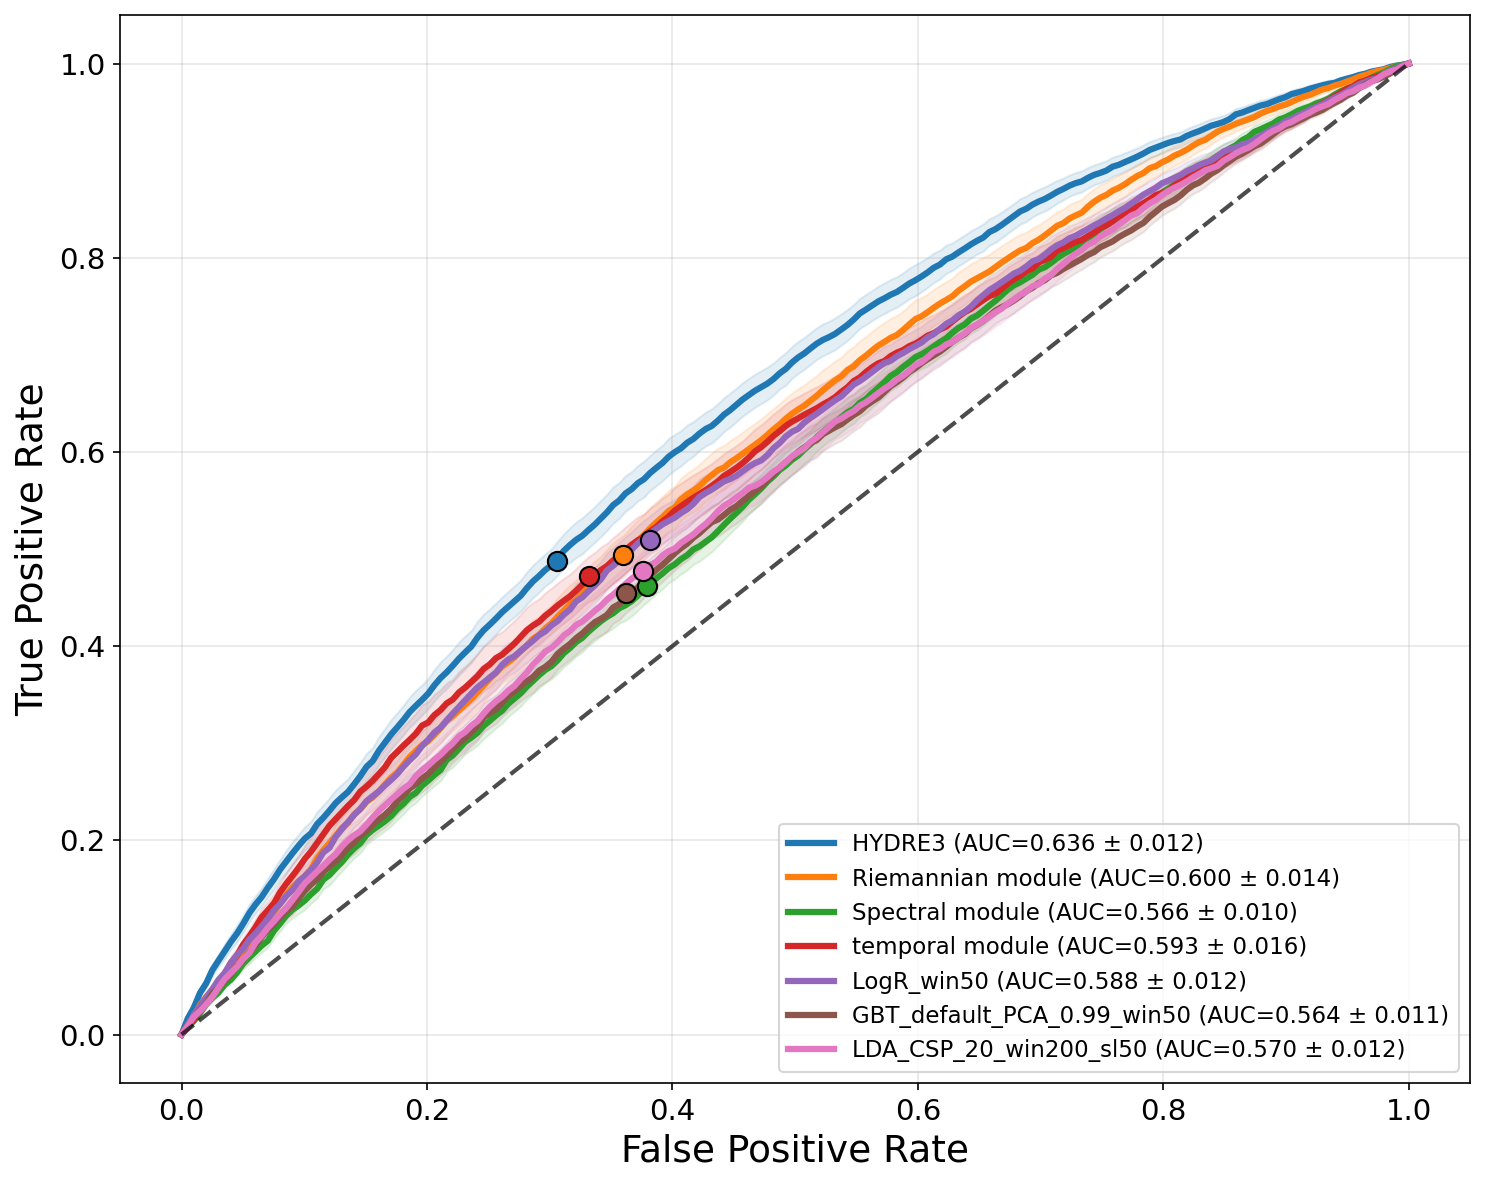

In [10]:
# Plotting the ROC curve at -300ms for all methods
from sklearn.metrics import roc_curve, auc

time_point = -300

methods = [
    "HYDRE3",
    "Riemannian module",
    "Spectral module",
    "temporal module",
    "LogR_win50",
    "GBT_default_PCA_0.99_win50",
    "LDA_CSP_20_win200_sl50"
]

mean_fpr = np.linspace(0, 1, 200)

plt.figure(figsize=(10, 8), dpi=150)

for method in methods:

    # -------------------------
    # Select dataframe + column
    # -------------------------
    if method == "HYDRE3":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_ensemble"

    elif method == "Riemannian module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_riemann"

    elif method == "Spectral module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_tfr"

    elif method == "temporal module":
        df_base = df_detailed_HYDRE_all_subjects
        proba_col = "proba_temporal"

    elif method == "LogR_win50":
        df_base = df_detailed_LogR_all_subjects
        proba_col = "proba"

    elif method == "GBT_default_PCA_0.99_win50":
        df_base = df_detailed_GBT_PCA_all_subjects
        proba_col = "proba"

    elif method == "LDA_CSP_20_win200_sl50":
        df_base = df_detailed_LDA_CSP_all_subjects
        proba_col = "proba"

    df = df_base[df_base["time"] == time_point]

    # -------------------------
    # Per-subject computation
    # -------------------------
    tprs = []
    aucs = []

    fpr_05_list = []
    tpr_05_list = []

    for participant_id, df_sub in df.groupby("participant_id"):

        if df_sub["y_true"].nunique() < 2:
            continue

        y_true = df_sub["y_true"]
        y_score = df_sub[proba_col]

        fpr, tpr, thresholds = roc_curve(y_true, y_score)

        aucs.append(auc(fpr, tpr))

        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        interp_tpr[-1] = 1.0
        tprs.append(interp_tpr)

        # threshold ≈ 0.5 point
        idx_05 = np.argmin(np.abs(thresholds - 0.5))
        fpr_05_list.append(fpr[idx_05])
        tpr_05_list.append(tpr[idx_05])

    # -------------------------
    # Mean ROC + SEM
    # -------------------------
    mean_tpr = np.mean(tprs, axis=0)
    sem_tpr = np.std(tprs, axis=0) / np.sqrt(len(tprs))

    mean_auc = np.mean(aucs)
    sem_auc = np.std(aucs) / np.sqrt(len(aucs))

    # -------------------------
    # Mean threshold point
    # -------------------------
    mean_fpr_05 = np.mean(fpr_05_list)
    mean_tpr_05 = np.mean(tpr_05_list)

    # -------------------------
    # Plot ROC curve (capture color)
    # -------------------------
    line, = plt.plot(
        mean_fpr,
        mean_tpr,
        linewidth=3,
        label=f"{method} (AUC={mean_auc:.3f} ± {sem_auc:.3f})"
    )

    color = line.get_color()

    # -------------------------
    # SEM band (same color, lighter)
    # -------------------------
    plt.fill_between(
        mean_fpr,
        np.clip(mean_tpr - sem_tpr, 0, 1),
        np.clip(mean_tpr + sem_tpr, 0, 1),
        alpha=0.12,
        color=color
    )

    # -------------------------
    # threshold = 0.5 point
    # -------------------------
    plt.scatter(
        mean_fpr_05,
        mean_tpr_05,
        s=85,
        color=color,
        edgecolor="black",
        linewidth=1.0,
        zorder=6
    )

# -------------------------
# Chance line
# -------------------------
plt.plot([0, 1], [0, 1], "k--", linewidth=2, alpha=0.7)

# -------------------------
# Labels / styling
# -------------------------
plt.xlabel("False Positive Rate", fontsize=18)
plt.ylabel("True Positive Rate", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.grid(alpha=0.3)

plt.legend(fontsize=11, loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

In [ ]:
# fig, ax = plt.subplots(figsize=(10, 6))

# # 1. Create the Boxplot (base layer)
# box = ax.boxplot(data_to_plot, labels=labels, patch_artist=True, 
#                  medianprops={'color': 'black', 'linewidth': 2},
#                  showfliers=False)

# for patch, color in zip(box['boxes'], colors):
#     patch.set_facecolor(color)
#     patch.set_alpha(0.2) # Light boxes to keep focus on the participant lines

# # 2. Connect the dots with conditional coloring
# x_indices = np.arange(1, len(labels) + 1)

# for i in range(n_participants):
#     participant_scores = [x[i], w[i], z[i], y[i]]
    
#     # Determine color based on Y vs Z performance
#     if x[i] > z[i]:
#         line_color = '#3498db'
#     else:
#         line_color = '#e67e22'
    
#     # Plot the line
#     ax.plot(x_indices, participant_scores, color=line_color, alpha=0.4, linewidth=1.5, zorder=1)
    
#     # Scatter the points on top of the lines
#     ax.scatter(x_indices, participant_scores, color=colors, s=40, edgecolors='white', alpha=0.6, zorder=2)

# # 3. Add Legend for the lines (Pro Tip)
# # We create "fake" lines to show in the legend since we can't easily label 100+ individual lines
# legend_elements = [
#     Line2D([0], [0], color='#3498db', lw=2, label='Temporal > Riemannian'),
#     Line2D([0], [0], color='#e67e22', lw=2, label='Riemannian > Temporal')
# ]
# ax.legend(handles=legend_elements, loc='upper left', frameon=True)

# # Styling
# ax.set_title('Participant Performance Profiles', fontsize=14)
# ax.set_ylabel('ROC AUC Score', fontsize=12)
# ax.grid(axis='y', linestyle='-', alpha=0.3)
# ax.set_ylim(0.48, 0.77)
# ax.axhline(0.5, color='k', linestyle='--', linewidth=2, zorder=3)

# plt.tight_layout()
# plt.show()

Time window of significant difference between HYDRE & all the modules: -517.2413793103448 ms to -51.72413793103442 ms


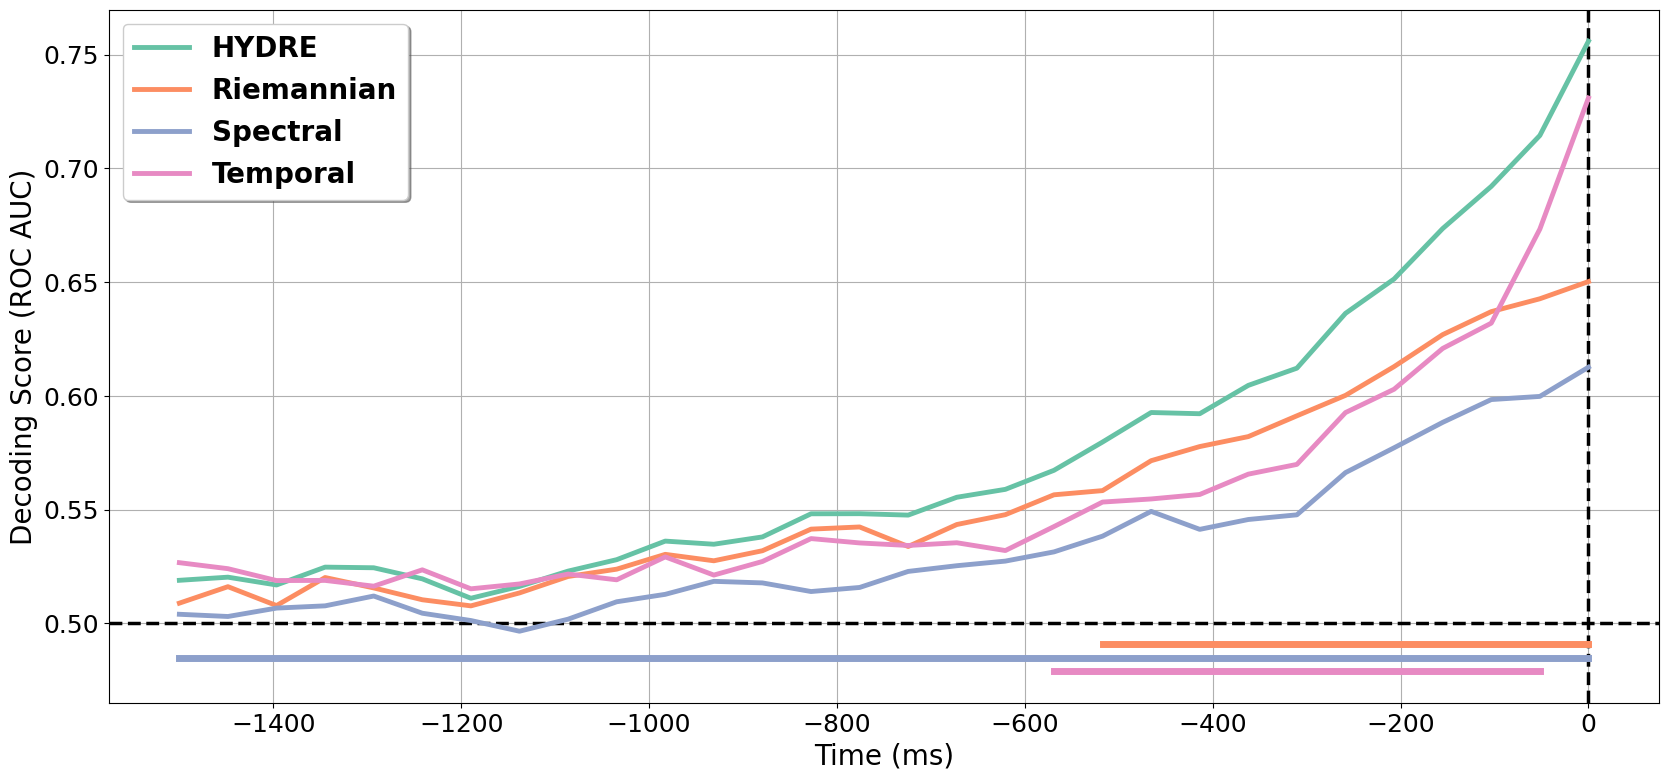

In [6]:
# Comparing the time course of decoding scores for HYDRE and each module
methods=["HYDRE3", "Riemannian module", "Spectral module", "temporal module"]

fname_fig = 'decoding_time_course_HYDRE3_&_modules.svg'

all_roc_dict = {}

for method in methods:
    all_roc = list()

    for n_subject, subject in enumerate(subjects_id):

        path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
        df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % subject))

        roc_scores = []

        for time_point in df_detailed_HYDRE['time'].unique():
            # Select data for the current time window
            data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == time_point]
            # Compute ROC AUC for HYDRE and each module
            if method == "HYDRE3":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_ensemble'].values))
            if method == "Riemannian module":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))
            if method == "Spectral module":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_tfr'].values))
            if method == "temporal module":
                roc_scores.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))      

        all_roc.append(roc_scores)
    all_roc_dict[method] = np.array(all_roc)

# Compute significance masks
method_ref = "HYDRE3"
method_other = ["Riemannian module", "Spectral module", "temporal module"]

mask_methods = []
for method2 in method_other:
    X1 = np.vstack(all_roc_dict[method_ref])  # shape: (n_subjects, n_times)
    X2 = np.vstack(all_roc_dict[method2])
    X_diff = X1 - X2
    p_val = decod_stats(X_diff)  # your cluster-based permutation function
    mask_methods.append(p_val < 0.05)

# Create time axis
n_times = all_roc_dict[method_ref][0].shape[0]
times = np.linspace(-1500, 0, n_times)

# compute time window of significant difference between HYDRE and all the module
indices = np.where(mask_methods[0] & mask_methods[1] & mask_methods[2])[0]
print(f"Time window of significant difference between HYDRE & all the modules: {times[indices[0]]} ms to {times[indices[-1]]} ms")

# Plotting
colors = ['#66c2a5','#fc8d62', "#8da0cb", '#e78ac3']

labels = ['HYDRE', 'Riemannian', 'Spectral', 'Temporal']
pos_bar = [0.491, 0.485, 0.479, 0.473]

plt.figure(figsize=(20, 9))
plt.axvline(0., color='k', linestyle='--', linewidth=2.5)
plt.axhline(0.5, color='k', linestyle='--', linewidth=2.5)

# Loop over the decoding scores and plot each one
for i in range(len(methods)):
    plt.plot(times, np.mean(all_roc_dict[methods[i]], axis=0), label= labels[i], color=colors[i], linewidth=3.5)
    
sign_pos=np.full(mask_methods[0].shape, pos_bar[0])
sign_pos[~mask_methods[0]] = np.nan
# Plot significant difference between groups
plt.plot(times,sign_pos,color='#fc8d62', linewidth=5)

sign_pos2=np.full(mask_methods[1].shape, pos_bar[1])
sign_pos2[~mask_methods[1]] = np.nan
# Plot significant difference between groups
plt.plot(times,sign_pos2,color= "#8da0cb", linewidth=5)

sign_pos3=np.full(mask_methods[2].shape, pos_bar[2])
sign_pos3[~mask_methods[2]] = np.nan
# Plot significant difference between groups
plt.plot(times,sign_pos3,color= '#e78ac3', linewidth=5)

# Add labels and title
plt.xlabel('Time (ms)', fontsize=20)
plt.ylabel('Decoding Score (ROC AUC)', fontsize=20)

# Increase tick size
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Customize legend
plt.legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})

# Add grid
plt.grid(True)

if saving:
    plt.savefig(os.path.join(path_figure, fname_fig), format='svg', dpi=300)
# Show the plot
if viz_plot:
    plt.show()

HYDRE average ROC AUC at -300ms: 0.6362896568972323
Riemannian average ROC AUC at -300ms: 0.6002394351871174
Spectral average ROC AUC at -300ms: 0.5662944525774621
Temporal average ROC AUC at -300ms: 0.5926799911991754
Number of subjects where HYDRE outperforms all the other methods: 11
Number of subjects where HYDRE outperforms the Riemannian method: 16
Number of subjects where HYDRE outperforms the Spectral method: 18
Number of subjects where HYDRE outperforms the Temporal method: 13


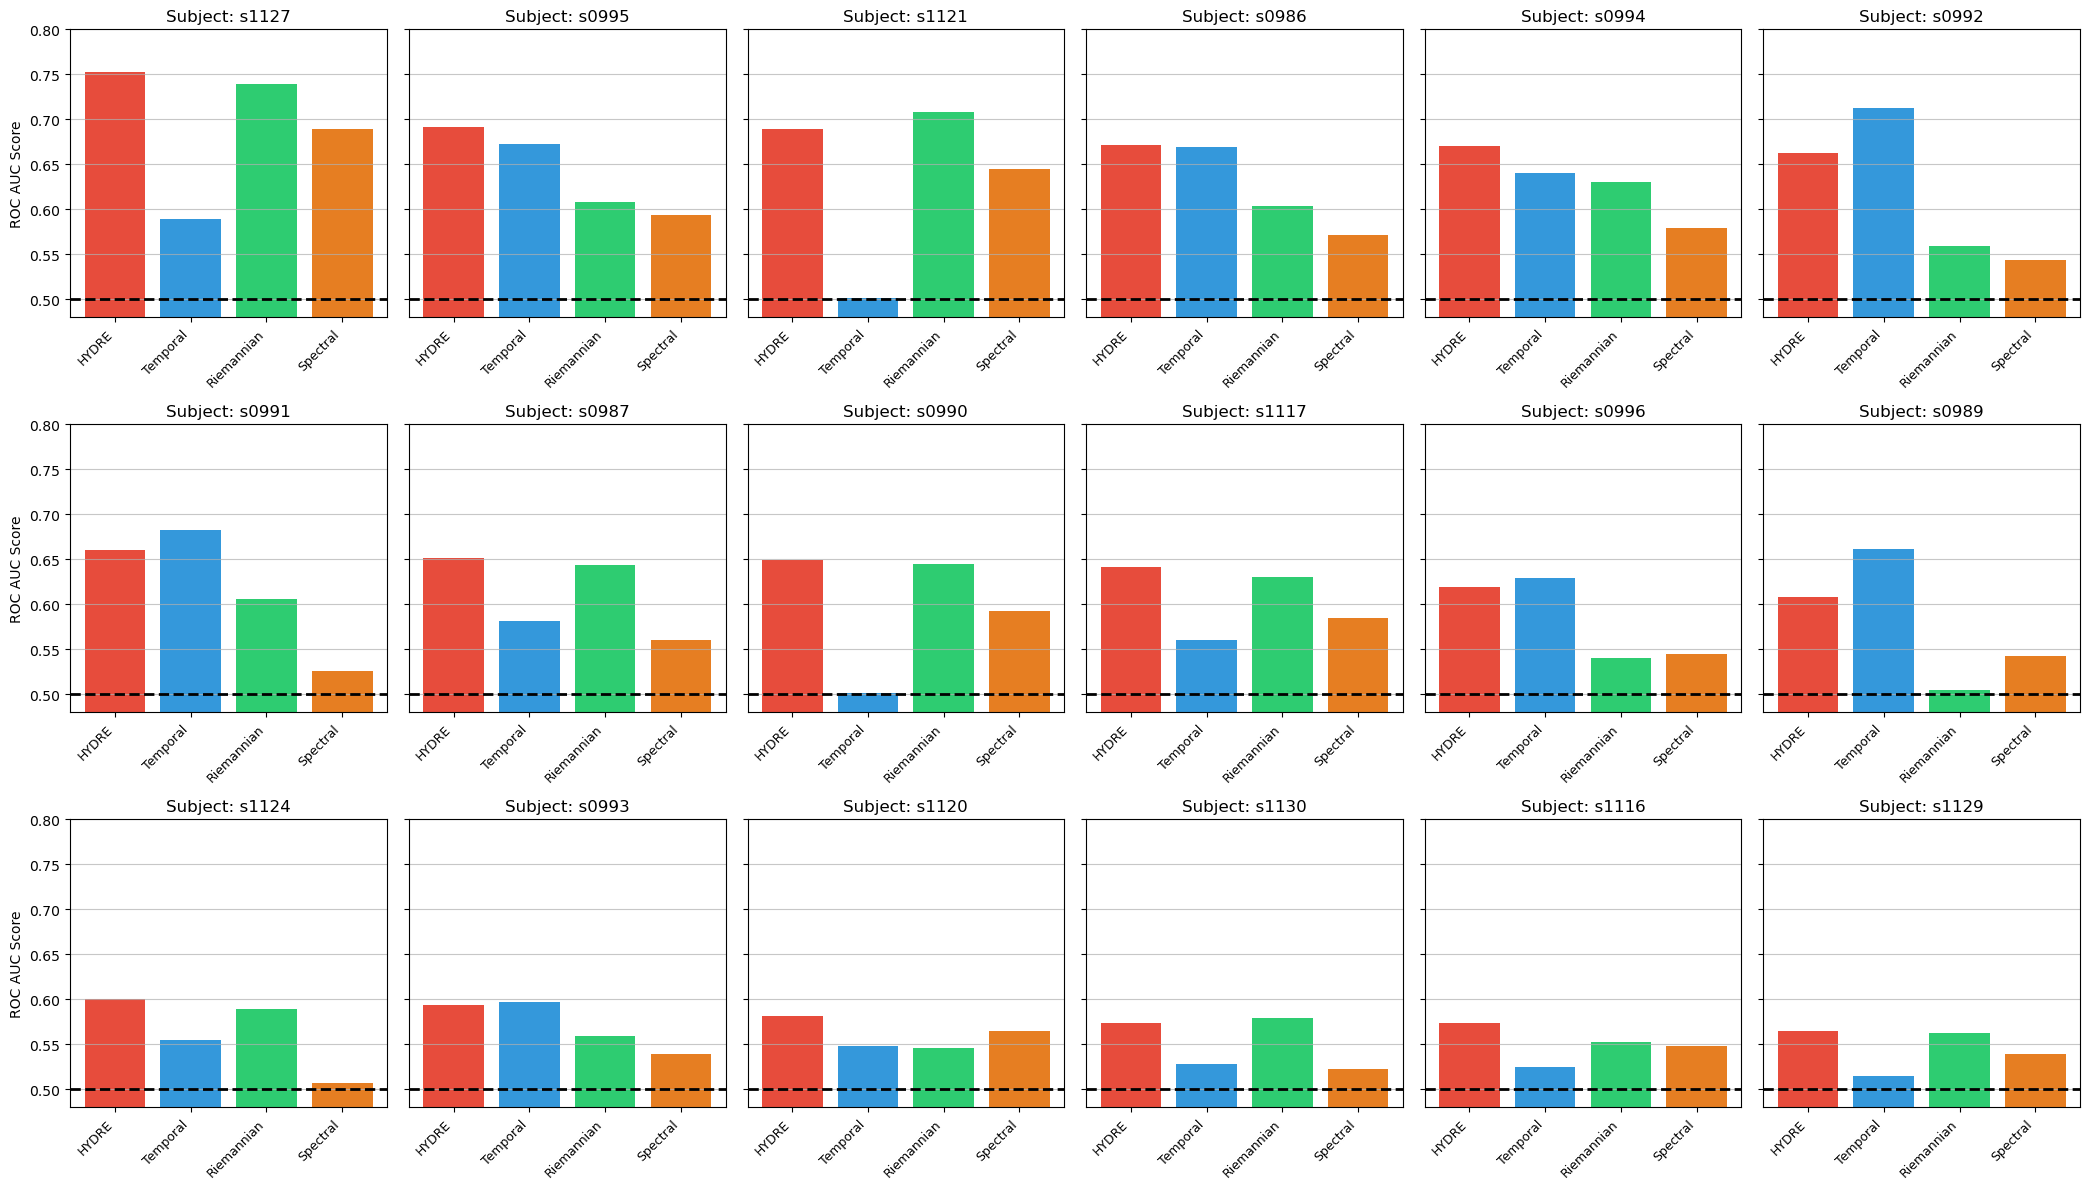

In [9]:
# Barplot comparing the scores of the 3 modules for each subject on time window from -300ms to -250ms
methods = ["temporal_module", "tfr_module", "riemann_module"]
fname_fig = 'barplot_roc_score_300ms.svg' 
all_roc_all_methods = roc_scores_all_subjects_temporal_module, roc_scores_all_subjects_spectral_module, roc_scores_all_subjects_riemannian_module, roc_scores_all_subjects_HYDRE

# Assign data to three dimensions
x = np.array(all_roc_all_methods[0]) # temporal
y = np.array(all_roc_all_methods[1]) # tfr
z = np.array(all_roc_all_methods[2]) # riemann
w= np.array(all_roc_all_methods[3]) # HYDRE
x=x[:,-6]
y=y[:,-6]
z=z[:,-6]
w=w[:,-6]

print("HYDRE average ROC AUC at -300ms:", np.mean(w))
print("Riemannian average ROC AUC at -300ms:", np.mean(z))
print("Spectral average ROC AUC at -300ms:", np.mean(y))
print("Temporal average ROC AUC at -300ms:", np.mean(x))

count = np.sum((w > x) & (w > y) & (w > z))
print(f"Number of subjects where HYDRE outperforms all the other methods: {count}")
count = np.sum((w > z))
print(f"Number of subjects where HYDRE outperforms the Riemannian method: {count}")
count = np.sum((w > y))
print(f"Number of subjects where HYDRE outperforms the Spectral method: {count}")
count = np.sum((w > x))
print(f"Number of subjects where HYDRE outperforms the Temporal method: {count}")

# Get the indices that would sort 'w' in descending order
# np.argsort returns indices for ascending; [::-1] reverses it for descending
sort_indices = np.argsort(w)[::-1]

# 2. Reorder all data arrays using these indices
sorted_subjects = np.array(subjects_id)[sort_indices]
sorted_w = np.array(w)[sort_indices]
sorted_x = np.array(x)[sort_indices]
sorted_y = np.array(y)[sort_indices]
sorted_z = np.array(z)[sort_indices]

# Calculate grid dimensions
n_subjects = len(sorted_subjects)
n_cols = ceil(n_subjects / 3) 

fig, axes = plt.subplots(3, n_cols, figsize=(n_cols * 3.5, 12), sharey=True)
axes = axes.flatten()

# Data labels and colors
labels = ['HYDRE', 'Temporal', 'Riemannian', 'Spectral']
colors = [ '#e74c3c','#3498db', '#2ecc71','#e67e22']
x_pos = np.arange(len(labels))

# Iterate through the SORTED data
for i, subject in enumerate(sorted_subjects):
    ax = axes[i]
    
    # Use the sorted arrays for the scores
    scores = [sorted_w[i], sorted_x[i], sorted_z[i], sorted_y[i]]
    
    # Create the bars
    bars = ax.bar(x_pos, scores, color=colors)
    
    # Subplot styling
    ax.set_title(f'Subject: {subject}')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
    ax.grid(axis='y', linestyle='-', alpha=0.7)
    ax.set_ylim(0.48, 0.8) 
    ax.axhline(0.5, color='k', linestyle='--', linewidth=2, zorder=3)
    # Only label the Y axis for the leftmost plots
    if i % n_cols == 0:
        ax.set_ylabel('ROC AUC Score')

# Remove any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

if saving:
    plt.savefig(Path(path_figure, fname_fig), format='svg', dpi=300)
if viz_plot:
    plt.show()


In [ ]:
# Plot the figure with the time course of decoding scores for HYDRE and different classical methods 
# fig, axes = plt.subplots(1, 1, figsize=(20, 18))
fig, axes = plt.subplots(1, 1, figsize=(20, 10))

colors_master = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b', '#e377c2']
labels_master = ["HYDRE", "Riemannian module", "Spectral module", "temporal module", "LogR", "GBT+PCA", "LDA+CSP"]
# Create a mapping for easy lookup in the second plot
color_map = dict(zip(labels_master, colors_master))

# --- FIRST SUBPLOT (TOP - A) ---
pos_bar1 = [0.485, 0.481, 0.477, 0.473, 0.469, 0.465, 0.461]


axes.axvline(0., color='k', linestyle='--', linewidth=2.5)
axes.axhline(0.5, color='k', linestyle='--', linewidth=2.5)

for i in range(len(all_roc_all_methods)):
    sign_pos = np.full(mask_methods[i].shape, pos_bar1[i])
    sign_pos[~mask_methods[i]] = np.nan
    axes.plot(times, all_roc_all_methods[i], label=labels_master[i], color=colors_master[i], linewidth=3.5)
    axes.plot(times, sign_pos, color=colors_master[i], linewidth=5)

axes.fill_between(times, 0, 1, where=mask_HYDRE_all_diff, color='grey', alpha=0.3, 
                            transform=axes.get_xaxis_transform(), zorder=1)

# Formatting for A
axes.set_ylabel('Decoding Score (ROC AUC)', fontsize=20)
axes.set_xlabel('Time (ms)', fontsize=20)
axes.tick_params(axis='y', labelsize=18)
axes.tick_params(axis='x', labelsize=18) 
axes.legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})
axes.grid(True)
axes.text(-0.04, 1.00, 'A)', transform=axes.transAxes, fontsize=24, fontweight='bold', va='top', ha='right')



# axes[0].axvline(0., color='k', linestyle='--', linewidth=2.5)
# axes[0].axhline(0.5, color='k', linestyle='--', linewidth=2.5)

# for i in range(len(all_roc_all_methods)):
#     sign_pos = np.full(mask_methods[i].shape, pos_bar1[i])
#     sign_pos[~mask_methods[i]] = np.nan
#     axes[0].plot(times, all_roc_all_methods[i], label=labels_master[i], color=colors_master[i], linewidth=3.5)
#     axes[0].plot(times, sign_pos, color=colors_master[i], linewidth=5)

# axes[0].fill_between(times, 0, 1, where=mask_HYDRE_all_diff, color='grey', alpha=0.3, 
#                             transform=axes[0].get_xaxis_transform(), zorder=1)

# # Formatting for A
# axes[0].set_ylabel('Decoding Score (ROC AUC)', fontsize=20)
# axes[0].tick_params(axis='y', labelsize=18)
# axes[0].tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False) # Removes tick labels
# axes[0].set_xlabel('') 
# axes[0].legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})
# axes[0].grid(True)
# axes[0].text(-0.04, 1.00, 'A)', transform=axes[0].transAxes, fontsize=24, fontweight='bold', va='top', ha='right')


# # --- SECOND SUBPLOT (BOTTOM - B) ---
# # Use the labels that exist in labels_master for consistency
# methods2 = ["HYDRE3", "Riemannian module", "Spectral module", "temporal module"]
# labels2 = ["HYDRE", "Riemannian module", "Spectral module", "temporal module"]
# pos_bar2 = [0.496, 0.492, 0.488, 0.484]

# axes[1].axvline(0., color='k', linestyle='--', linewidth=2.5)
# axes[1].axhline(0.5, color='k', linestyle='--', linewidth=2.5)

# for i in range(len(methods2)):
#     # Get color from the master mapping based on the label
#     current_label = labels2[i]
#     current_color = color_map[current_label]
    
#     axes[1].plot(times, np.mean(HYDRE_roc_dict[methods2[i]], axis=0), 
#                  label=current_label, color=current_color, linewidth=3.5)

# # Significant bars for B using the mapped colors
# # Riemannian (index 0), Spectral (index 1), Temporal (index 2)
# for i, label_key in enumerate(["Riemannian module", "Spectral module", "temporal module"]):
#     sign_pos = np.full(mask_compare_HYDRE[i].shape, pos_bar2[i])
#     sign_pos[~mask_compare_HYDRE[i]] = np.nan
#     axes[1].plot(times, sign_pos, color=color_map[label_key], linewidth=5)

# # Formatting for B
# axes[1].set_xlabel('Time (ms)', fontsize=20)
# axes[1].set_ylabel('Decoding Score (ROC AUC)', fontsize=20)
# axes[1].tick_params(axis='both', labelsize=18)
# axes[1].legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})
# axes[1].grid(True)
# axes[1].text(-0.04, 1.00, 'B)', transform=axes[1].transAxes, fontsize=24, fontweight='bold', va='top', ha='right')

plt.tight_layout()

if saving:
    plt.savefig(os.path.join(path_figure, fname_fig), format='svg', dpi=300)

if viz_plot:
    plt.show()

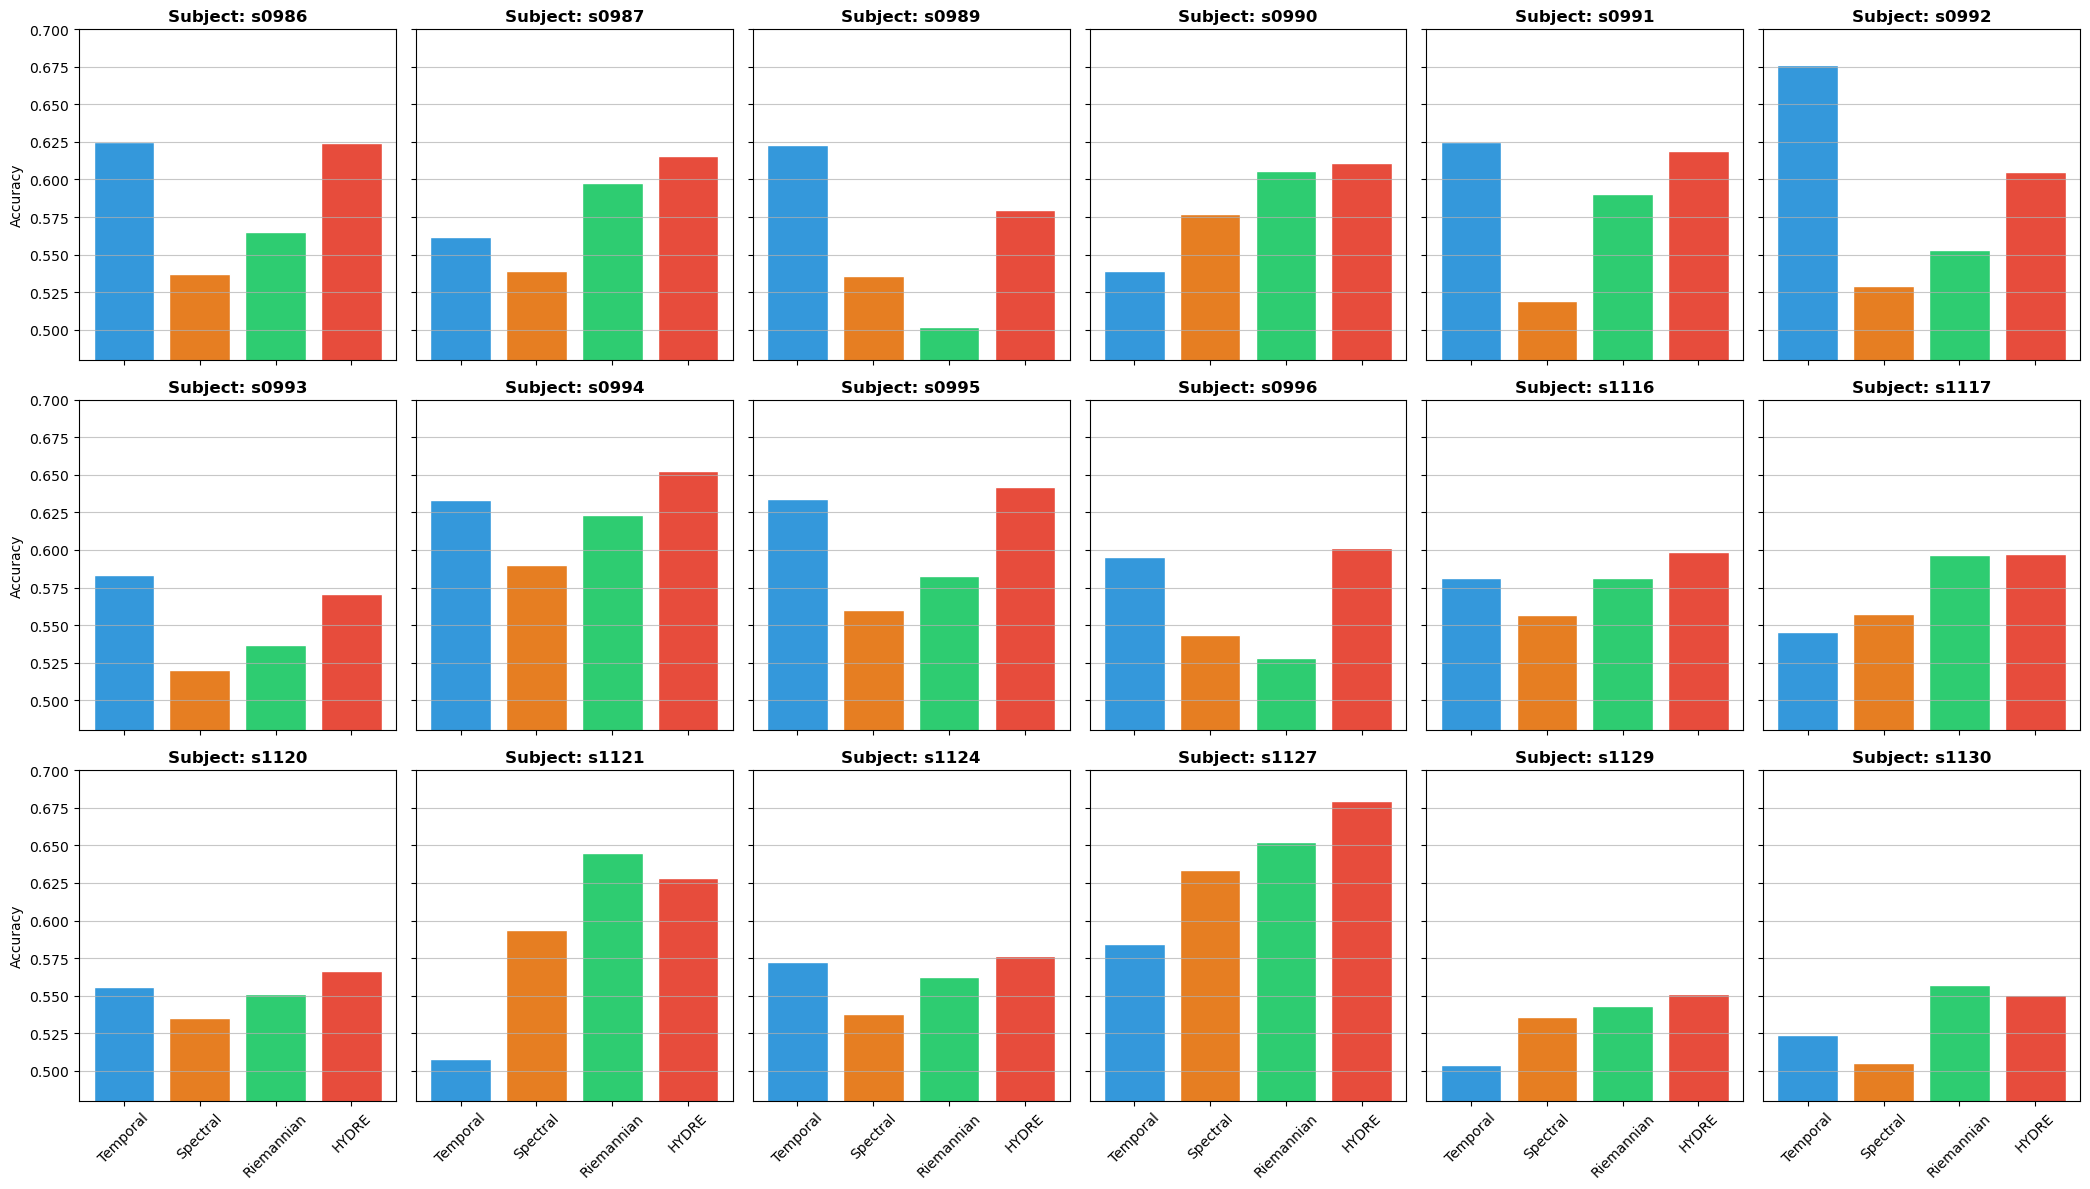

In [ ]:
# Barplot accuracy 
fname_fig = '_per_subject.svg'

results_list = []

data_time_window = df_detailed_HYDRE_all_subjects[df_detailed_HYDRE_all_subjects['time'] == -300]
for subject in subjects_id:
    data_time_window_subject = data_time_window[data_time_window['participant_id'] == subject]
    # ratio of correctly predicted trials/total nbr of trials of one model for one participant
    nbr_correct_temporal = np.sum(data_time_window_subject['pred_temporal'] == data_time_window_subject['y_true'])
    nbr_correct_spectral = np.sum(data_time_window_subject['pred_tfr'] == data_time_window_subject['y_true'])
    nbr_correct_riemannian = np.sum(data_time_window_subject['pred_riemann'] == data_time_window_subject['y_true'])
    nbr_correct_ensemble = np.sum(data_time_window_subject['pred_ensemble'] == data_time_window_subject['y_true'])
    total_trials = len(data_time_window_subject)
    ratio_temporal = nbr_correct_temporal / total_trials
    ratio_spectral = nbr_correct_spectral / total_trials
    ratio_riemannian = nbr_correct_riemannian / total_trials
    ratio_ensemble = nbr_correct_ensemble / total_trials

    tmp = {'subject': subject,
           'ratio_temporal': ratio_temporal,
           'ratio_spectral': ratio_spectral,
           'ratio_riemannian': ratio_riemannian,
           'ratio_ensemble': ratio_ensemble}
    
    results_list.append(tmp)

# Convert to DataFrame if needed
results_df = pd.DataFrame(results_list)

# Identify the ratio columns (excluding the 'subject' column)
ratio_cols = ['ratio_temporal', 'ratio_spectral', 'ratio_riemannian', 'ratio_ensemble']
labels = ['Temporal', 'Spectral', 'Riemannian', 'HYDRE']
colors = ['#3498db', '#e67e22', '#2ecc71', '#e74c3c'] # More modern palette

# Calculate grid dimensions (now 3 rows as requested)
n_subjects = len(results_df)
n_cols = ceil(n_subjects / 3)

fig, axes = plt.subplots(3, n_cols, figsize=(n_cols * 3.5, 12), sharey=True)
axes = axes.flatten()

for i, (idx, row) in enumerate(results_df.iterrows()):
    ax = axes[i]
    ax.grid(axis='y', linestyle='-', alpha=0.7)

    subject_scores = row[ratio_cols].values
    ax.bar(labels, subject_scores, color=colors, edgecolor='white')
    
    ax.set_title(f"Subject: {row['subject']}", fontweight='bold')
    ax.set_ylim(0.48, 0.7) 
    
    # Check if this subplot is in the last row
    # (i + n_cols) >= n_subjects ensures it's the "bottom-most" bar for that column
    if (i + n_cols) < n_subjects:
        ax.set_xticklabels([]) # Hide labels for upper rows
    else:
        ax.tick_params(axis='x', rotation=45) # Show and rotate for bottom row

    if i % n_cols == 0:
        ax.set_ylabel('Accuracy')

# Cleanup ghost plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

if saving:
    plt.savefig(Path(path_figure, fname_fig), format='svg', dpi=300)
if viz_plot:
    plt.show()

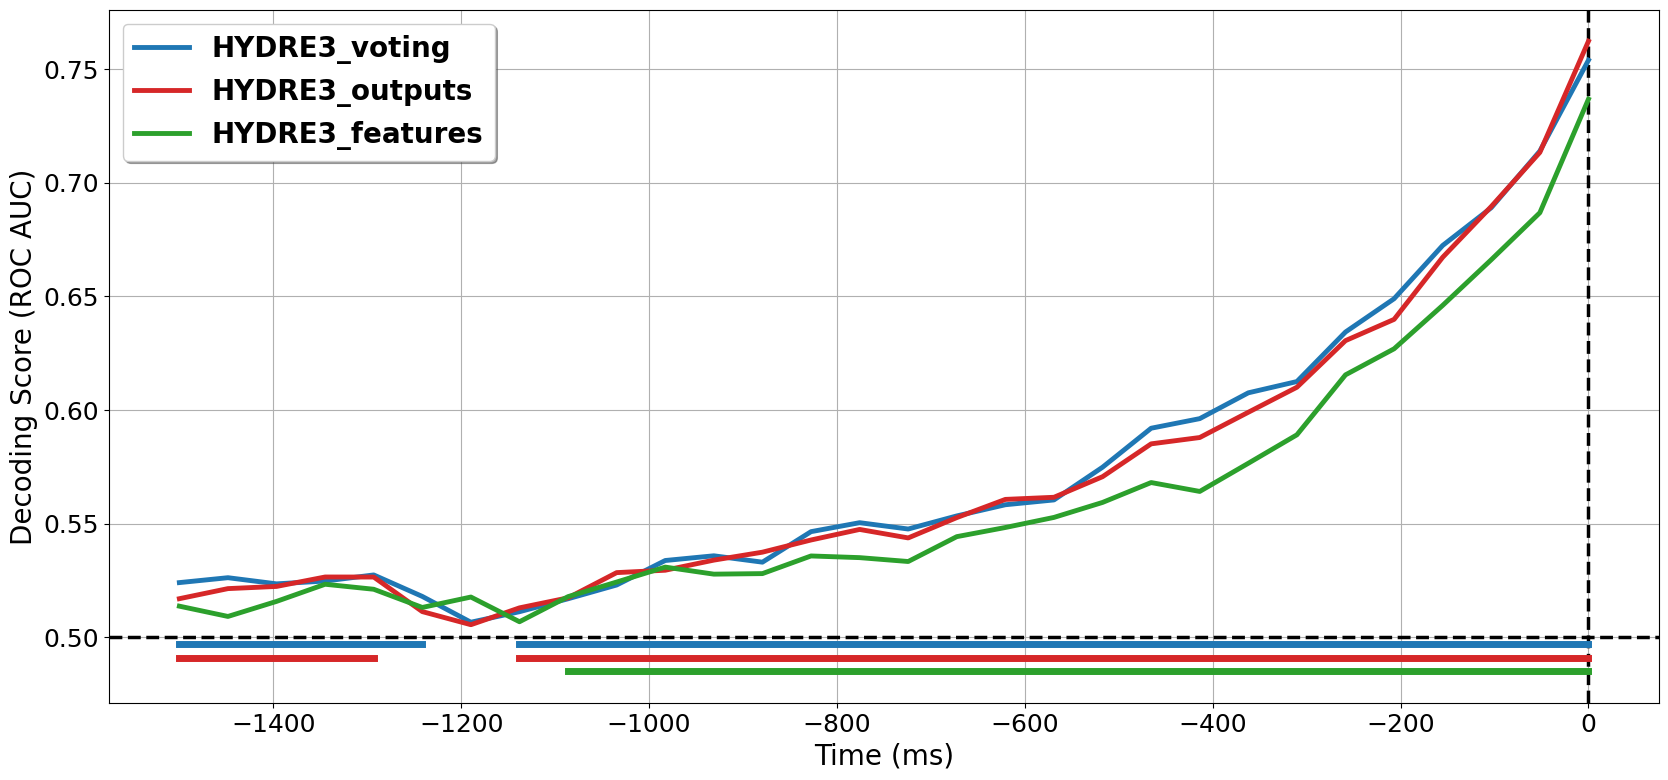

In [5]:
# Plotting the average decoding scores of the 3 ensembling methods tested

methods=[ "HYDRE3_vf_voting_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50", "HYDRE3_vf_outputs_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50", "HYDRE3_vf_features_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_C=0.1_win50"]
    
fname_fig = 'toto.svg' 

mask_methods = list()

all_roc_all_methods = []
for method in methods:

    all_roc = []
    for n_subject, subject in enumerate(subjects_id):

        path_scores = Path(op.join(path_load_score, subject, 'meg', 'scores', method))
        data_roc = '%s_meg_roc_auc_scores_offline_%s.npy' % (subject, method)
        roc_auc = np.load(Path(path_scores, data_roc))
        all_roc.append(roc_auc)   
    
    p_val = decod_stats(np.array(all_roc)-1/2.)
    wh_sign = p_val<0.05
    mask_methods.append(wh_sign)
        
    all_roc= np.squeeze(np.mean(all_roc, axis=0))
    all_roc_all_methods.append(all_roc)   

# Plot all methods
times = np.linspace(-1500, 0, np.squeeze(all_roc_all_methods[0].shape)) #transform x axis from timestamps to seconds
# Colors for each method (high contrast)
colors = [ '#1f77b4', '#d62728', '#2ca02c']
labels = [ "HYDRE3_voting", "HYDRE3_outputs", "HYDRE3_features"]
pos_bar = [0.497, 0.491, 0.485]
# Create the plot
plt.figure(figsize=(20, 9))

plt.axvline(0., color='k', linestyle= '--', linewidth=2.5)
plt.axhline(0.5, color='k', linestyle= '--', linewidth=2.5)

# Loop over the decoding scores and plot each one
for i in range(len(all_roc_all_methods)):
    sign_pos=np.full(mask_methods[i].shape, pos_bar[i])
    sign_pos[~mask_methods[i]] = np.nan

    plt.plot(times, all_roc_all_methods[i], label= labels[i], color=colors[i], linewidth=3.5)
    # Plot significant difference between groups
    plt.plot(times,sign_pos,color=colors[i], linewidth=5)

# Add labels and title
plt.xlabel('Time (ms)', fontsize=20)
plt.ylabel('Decoding Score (ROC AUC)', fontsize=20)

# Increase tick size
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Customize legend
plt.legend(loc='best', frameon=True, fancybox=True, shadow=True, prop={'weight': 'bold', 'size': 20})

# Add grid
plt.grid(True)

# Show the plot
plt.show()

c:\Users\Romar\anaconda3\envs\Agency_pix_MEG\lib\site-packages\matplotlib_venn\_venn3.py:165: UserWarning: normalize_to is deprecated. Please use layout_algorithm=matplotlib_venn.layout.venn3.DefaultLayoutAlgorithm(normalize_to) instead.
  warnings.warn(


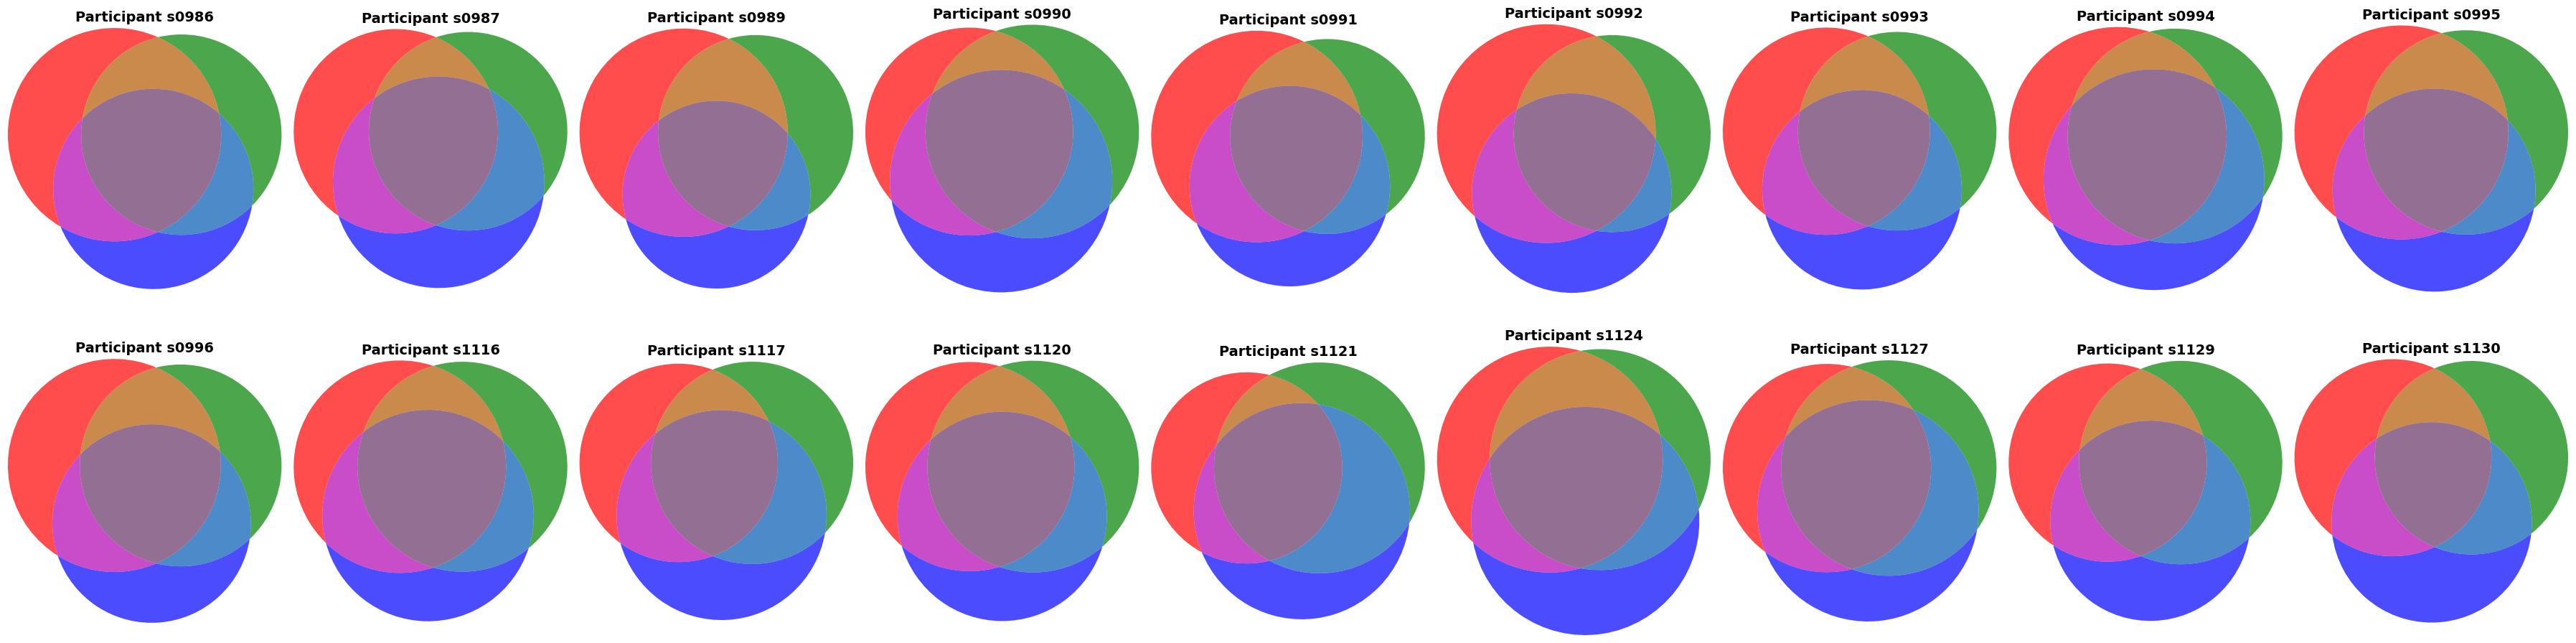

In [ ]:
# Plot Venn diagrams for all participants in a 2-row grid with normalized areas

def plot_all_participants_venn(df, participant_ids, target_time):
    import math
    """
    Plots Venn diagrams for multiple participants in a 2-row grid with normalized areas.
    """
    n_participants = len(participant_ids)
    
    # Calculate columns needed for 2 rows (ceiling division)
    n_cols = math.ceil(n_participants / 2)
    
    # Create the 2-row figure
    fig, axes = plt.subplots(2, n_cols, figsize=(n_cols * 4, 10))
    
    # Flatten axes to easily iterate in a single loop
    # This turns a [[ax1, ax2], [ax3, ax4]] grid into [ax1, ax2, ax3, ax4]
    axes_flat = axes.flatten()

    # 1. Determine a global normalization factor (using the first participant as reference)
    window_df_all = df[df['time'] == target_time]
    # Check if participant_ids[0] exists in the window to avoid empty slice errors
    ref_df = window_df_all[window_df_all['participant_id'] == participant_ids[0]]
    max_area = len(ref_df) if not ref_df.empty else 100 

    for i, p_id in enumerate(participant_ids):
        ax = axes_flat[i]
        
        # Filter for this specific participant
        p_df = window_df_all[window_df_all['participant_id'] == p_id]
        
        # 2. Create sets
        set1 = set(p_df[p_df['pred_temporal'] == p_df['y_true']]['trial_idx'])
        set2 = set(p_df[p_df['pred_tfr'] == p_df['y_true']]['trial_idx'])
        set3 = set(p_df[p_df['pred_riemann'] == p_df['y_true']]['trial_idx'])

        # 3. Plot on the flattened axis
        v = venn3([set1, set2, set3], 
                  set_labels=('', '', ''), 
                  ax=ax, 
                  normalize_to=max_area)
        
        # 4. Remove internal text (numbers/counts)
        if v and v.subset_labels:
            for text in v.subset_labels:
                if text: text.set_text('')
        
        ax.set_title(f"Participant {p_id}", fontsize=14, fontweight='bold')

        # Style colors
        if v:
            for patch in v.patches:
                if patch:
                    patch.set_alpha(0.7)

    # 5. Hide any unused subplots (if you have an odd number of participants)
    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].axis('off')

    plt.tight_layout()
    plt.show()
plot_all_participants_venn(df_detailed_HYDRE_all_subjects, participant_ids=subjects_id, target_time=-300)

c:\Users\Romar\anaconda3\envs\Agency_pix_MEG\lib\site-packages\upsetplot\data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
c:\Users\Romar\anaconda3\envs\Agency_pix_MEG\lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linew

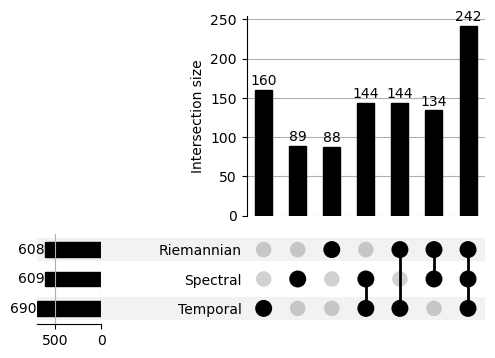

In [ ]:
# Plot Upset diagram for a single participant at a specific time window
from upsetplot import from_contents, plot
import matplotlib.pyplot as plt

def plot_group_upset(df, target_time):
    window_df = df[df['time'] == target_time]
    # We aggregate ALL correct trials across the group
    # Or you can do this per participant.
    contents = {
        'Temporal': window_df[window_df['pred_temporal'] == window_df['y_true']]['trial_idx'].tolist(),
        'Spectral': window_df[window_df['pred_tfr'] == window_df['y_true']]['trial_idx'].tolist(),
        'Riemannian': window_df[window_df['pred_riemann'] == window_df['y_true']]['trial_idx'].tolist()
    }
    
    data = from_contents(contents)
    
    # This chart is 100% proportional. 
    # If the 'Temporal Only' bar is twice as high as 'Spectral Only', 
    # it is because it has exactly twice the correct predictions.
    plot(data, show_counts=True)
    plt.show()
toto = df_detailed_HYDRE_all_subjects[df_detailed_HYDRE_all_subjects['participant_id'] == 's0986']

plot_group_upset(toto, target_time=-300)

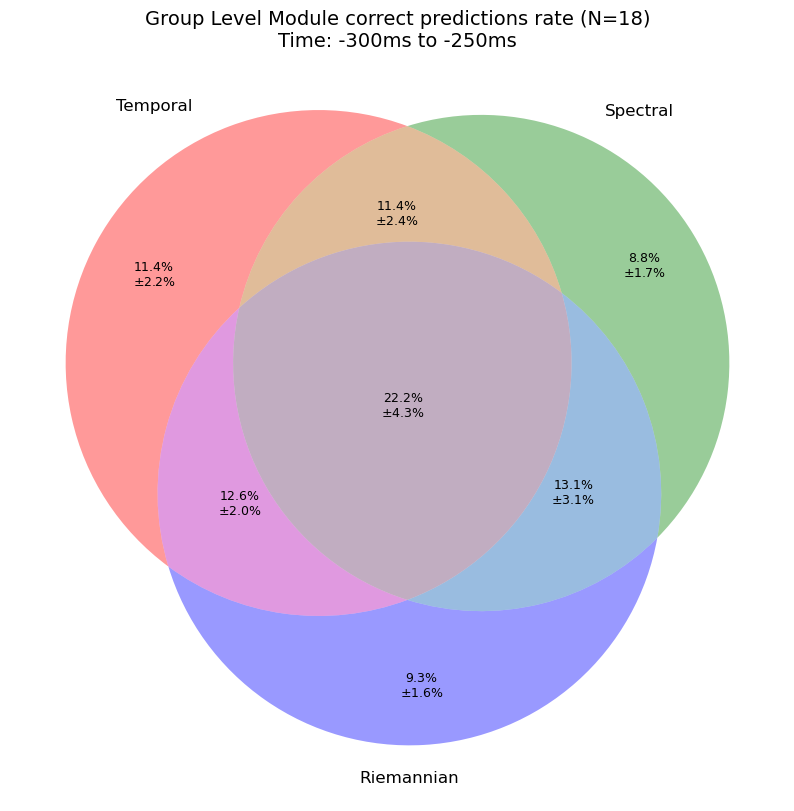

In [ ]:
# Plot Venn diagram with percentages and standard deviations for each region across the group

def plot_group_venn(df, target_time):
    window_df = df[df['time'] == target_time]
    participants = window_df['participant_id'].unique()
    
    # Storage for the 7 regions per participant
    region_data = []

    for p_id in participants:
        p_df = window_df[window_df['participant_id'] == p_id]
        total_trials = len(p_df)
        
        # 1. Define sets
        s1 = set(p_df[p_df['pred_temporal'] == p_df['y_true']]['trial_idx'])
        s2 = set(p_df[p_df['pred_tfr'] == p_df['y_true']]['trial_idx'])
        s3 = set(p_df[p_df['pred_riemann'] == p_df['y_true']]['trial_idx'])
        
        # 2. Calculate the 7 DISJOINT subsets manually
        # The order expected by venn3 is: (Abc, aBc, ABc, abC, AbC, aBC, ABC)
        Abc = len(s1 - (s2 | s3))        # Only 1
        aBc = len(s2 - (s1 | s3))        # Only 2
        ABc = len((s1 & s2) - s3)       # 1 & 2
        abC = len(s3 - (s1 | s2))        # Only 3
        AbC = len((s1 & s3) - s2)       # 1 & 3
        aBC = len((s2 & s3) - s1)       # 2 & 3
        ABC = len(s1 & s2 & s3)          # All 3
        
        subsets = [Abc, aBc, ABc, abC, AbC, aBC, ABC]
        
        # Convert to percentages
        p_percentages = (np.array(subsets) / total_trials) * 100
        region_data.append(p_percentages)

    # 3. Aggregate
    region_data = np.array(region_data)
    means = np.mean(region_data, axis=0)
    stds = np.std(region_data, axis=0)

    # 4. Plot
    plt.figure(figsize=(10, 10))
    v = venn3(subsets=tuple(means), set_labels=('Temporal', 'Spectral', 'Riemannian'))

    region_ids = ['100', '010', '110', '001', '101', '011', '111']
    for i, r_id in enumerate(region_ids):
        lbl = v.get_label_by_id(r_id)
        if lbl:
            # Use LaTeX for the plus-minus symbol
            lbl.set_text(f"{means[i]:.1f}%\n$\pm${stds[i]:.1f}%")
            lbl.set_fontsize(9)

    plt.title(f"Group Level Module correct predictions rate (N={len(participants)})\nTime: {target_time}ms to {target_time + 50}ms", fontsize=14)
    plt.show()

plot_group_venn(df_detailed_HYDRE_all_subjects, target_time=-300)

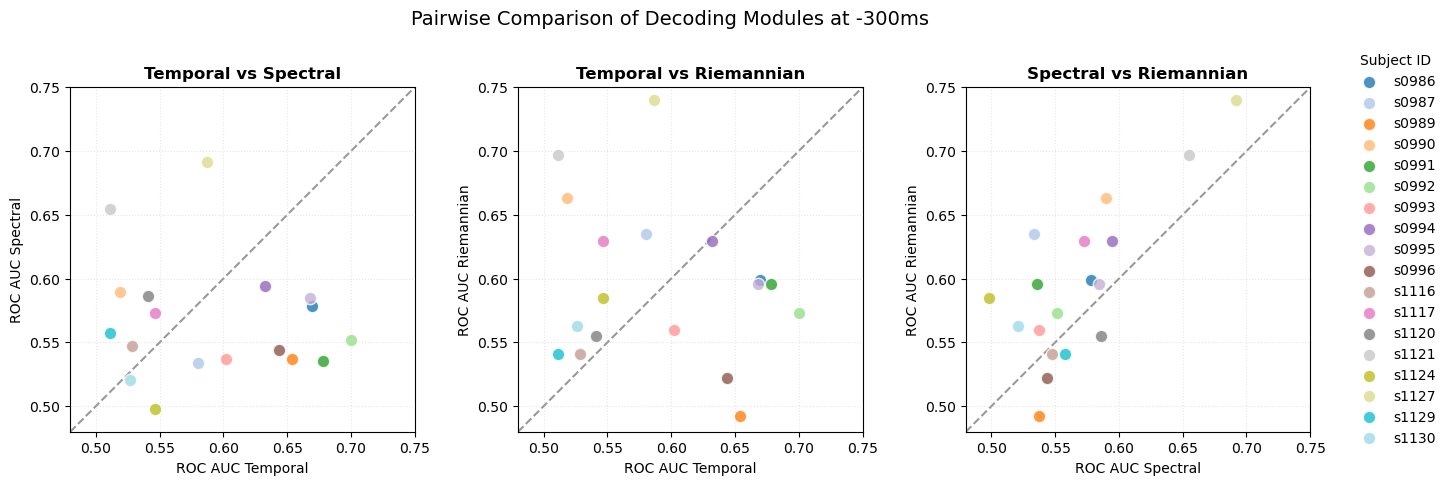

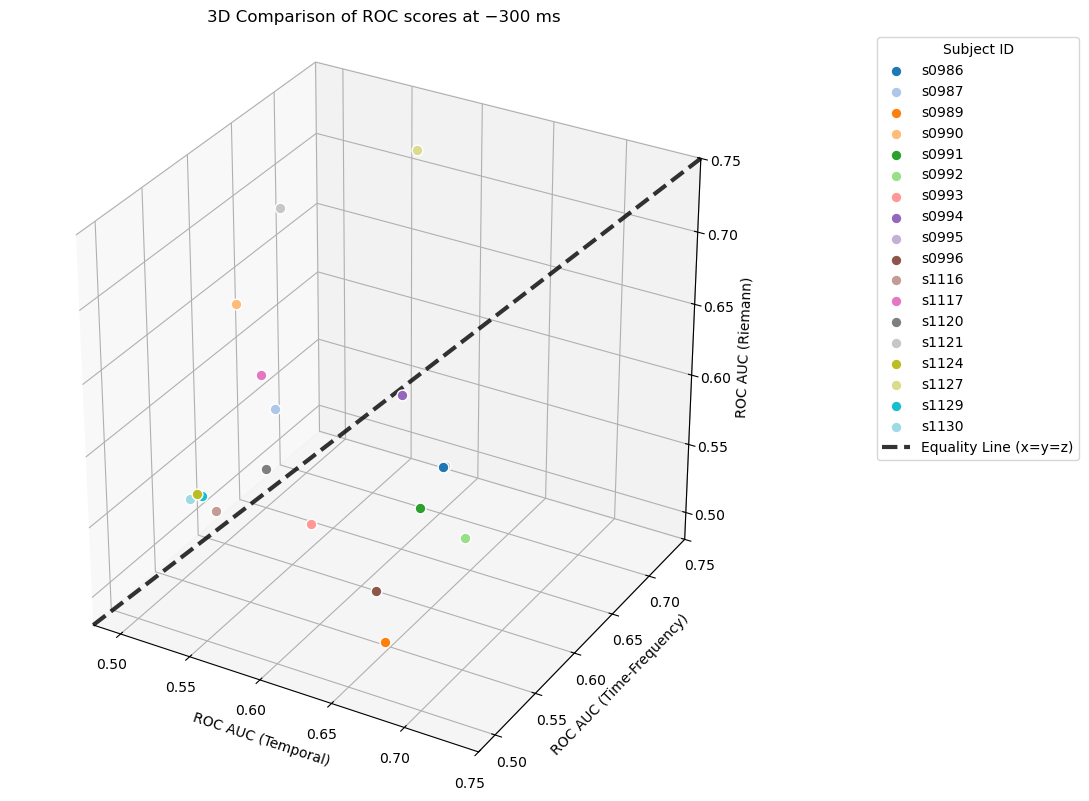

In [63]:
# Scatter plot comparing the scores of the 3 modules for each subject at -300ms
methods = ["temporal_module", "tfr_module", "riemann_module"]
fname_fig = 'scatter_plot_3d_roc_score_300ms.svg' 
all_roc_all_methods = roc_scores_all_subjects_temporal_module, roc_scores_all_subjects_spectral_module, roc_scores_all_subjects_riemannian_module

# Assign data to three dimensions
x = np.array(all_roc_all_methods[0]) # temporal
y = np.array(all_roc_all_methods[1]) # tfr
z = np.array(all_roc_all_methods[2]) # riemann
x=x[:,-6]
y=y[:,-6]
z=z[:,-6]
# Create a colormap
cmap = plt.get_cmap('tab20')
colors = cmap(np.linspace(0, 1, len(subjects_id)))

combinations = [
    (x, y, "Temporal", "Spectral"),
    (x, z, "Temporal", "Riemannian"),
    (y, z, "Spectral", "Riemannian")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

limit_min, limit_max = 0.48, 0.75
handles = [] 

for ax, (data_x, data_y, label_x, label_y) in zip(axes, combinations):
    # Plot identity line
    ax.plot([limit_min, limit_max], [limit_min, limit_max], 
            linestyle='--', color='black', alpha=0.4, zorder=1)
    
    for i, subject in enumerate(subjects_id):
        sc = ax.scatter(data_x[i], data_y[i], color=colors[i], s=80, 
                        edgecolors='w', alpha=0.8, zorder=2, label=subject)
        if ax == axes[0]:
            handles.append(sc)
    
    # --- FIX START ---
    # Force the y-axis ticks to show even though sharey=True is active
    ax.tick_params(labelleft=True) 
    
    # Set labels for every subplot
    ax.set_xlabel(f"ROC AUC {label_x}")
    ax.set_ylabel(f"ROC AUC {label_y}") 
    # --- FIX END ---

    ax.set_xlim(limit_min, limit_max)
    ax.set_ylim(limit_min, limit_max)
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.set_title(f"{label_x} vs {label_y}", fontweight='bold')

# Adjust wspace slightly higher (e.g., 0.3) so the new y-labels don't overlap the previous plot
plt.subplots_adjust(wspace=0.3, top=0.85)

fig.legend(
    handles=handles, 
    labels=list(subjects_id), 
    title="Subject ID", 
    loc='center left', 
    bbox_to_anchor=(0.92, 0.5),
    frameon=False
)

plt.suptitle("Pairwise Comparison of Decoding Modules at -300ms", fontsize=14)

if saving:
    plt.savefig(Path(path_figure, fname_fig), format='svg', bbox_inches='tight')

plt.show()


######################################################################################################
######### Scatter plot comparing the scores of the 3 modules for each subject at -300ms in a 3D plot
######################################################################################################

from mpl_toolkits.mplot3d import Axes3D  # Necessary for 3D projection

methods = ["temporal_module", "tfr_module", "riemann_module"]
fname_fig = 'scatter_plot_3d_roc_score_300ms.svg' 
all_roc_all_methods = roc_scores_all_subjects_temporal_module, roc_scores_all_subjects_spectral_module, roc_scores_all_subjects_riemannian_module

# Assign data to three dimensions
x = np.array(all_roc_all_methods[0]) # temporal
y = np.array(all_roc_all_methods[1]) # tfr
z = np.array(all_roc_all_methods[2]) # riemann
x=x[:,-6]
y=y[:,-6]
z=z[:,-6]
# Create a colormap
cmap = plt.get_cmap('tab20')
colors = cmap(np.linspace(0, 1, len(subjects_id)))

# Initialize 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot each subject separately in 3D
for i, subject in enumerate(subjects_id):
    ax.scatter(
        x[i],
        y[i],
        z[i],
        color=colors[i],
        label=subject,
        s=60,
        edgecolors='w'
    )

# Define the range for the line (e.g., from 0.4 to 0.8 based on your data)
line_min, line_max = 0.48, 0.75
line_coords = np.linspace(line_min, line_max, 100)

# Plotting the 3D diagonal
ax.plot(line_coords, line_coords, line_coords, 
        label='Equality Line (x=y=z)', 
        color='black', 
        linestyle='--', 
        linewidth=3, 
        alpha=0.8,
        zorder=10) # Keep it on top

# Labels
ax.set_xlabel("ROC AUC (Temporal)")
ax.set_ylabel("ROC AUC (Time-Frequency)")
ax.set_zlabel("ROC AUC (Riemann)")
ax.set_title("3D Comparison of ROC scores at −300 ms")

# Legend
ax.legend(
    title="Subject ID",
    bbox_to_anchor=(1.15, 1),
    loc='upper left',
    fontsize=10
)

plt.tight_layout()

if saving:
    # Note: SVG can be heavy for 3D plots; PNG is often preferred if rotation isn't interactive
    plt.savefig(Path(path_figure, fname_fig), format='svg', dpi=300)

# Set equal scaling so the diagonal looks like a true 45-degree angle
ax.set_box_aspect([1,1,1]) 

# Limits (tighten these to your data range to make the differences visible)
ax.set_xlim(0.48, 0.75)
ax.set_ylim(0.48, 0.75)
ax.set_zlim(0.48, 0.75)

# Add a subtle grid
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()